# Adaptive Power Units (APU): complete experiment suite, paper configuration

Open this notebook in Jupyter and choose **Kernel -> Restart & Run All**. It installs what it needs, downloads the datasets, runs every experiment, and ends with paper-ready figures, tables, captions and a findings summary in `apu_runs_<size>/paper_assets` (also zipped as `paper_assets.zip`).

**Nothing in here comes with pre-computed results.** Every table and figure is built from run files. Figures report what was measured, including where APU is worse than the baselines.

## How the paper run works (two steps)

1. **First Run All = preflight.** With `SIZE = "paper"` the notebook first runs the same grid for 1 epoch (folder `apu_runs_preflight`, separate from the real results). It finds crashes, missing downloads and disk problems in about an hour plus download time. When it prints **PREFLIGHT OK** it writes `apu_preflight_ok.flag`.
2. **Second Run All = the real paper run.** Section 7a prints the estimated hours for your GPU, then everything runs. If it is interrupted, run all cells again: finished runs are skipped and half-finished runs resume (progress is saved every 5 epochs).

The two runs never mix: each size has its own results folder.

## Before you start (Windows laptop)

1. Plug in, set sleep and hibernate to **Never**, pause Windows updates, give the laptop airflow. Use a recent NVIDIA driver (570+ for RTX 50-series).
2. Free disk space: about **25 GB** (datasets 2 GB, Tiny-ImageNet cache 1.5 GB, checkpoints about 8 GB, outputs).
3. Datasets are large downloads (CIFAR 170 MB each, Tiny-ImageNet 237 MB, EMNIST 560 MB). Downloads resume after a drop and run in the background. You can also put the files in the `data` folder by hand (names in cell 5b).
4. RAM: the first Tiny-ImageNet load needs about 4 GB of free memory.

## Paper configuration (`SIZE = "paper"`) and where it differs from the plan

| Item | Plan (poster) | This notebook | Reason |
|---|---|---|---|
| Seeds | 5 | 5 for CIFAR, ablation, Tiny-ImageNet; 3 for pilot, LR sweep, MNIST/EMNIST, GAN | requirements: at least 5 for the principal experiments |
| Epochs, CIFAR-10/100 | 200 | 200 | same |
| Epochs, MNIST/EMNIST | 100 | 30 | these converge in under 20 epochs; 100 would cost days. Override in cell 0a |
| Epochs, GAN | 100 | 100 | same |
| ImageNet-1K (ResNet-50 + ViT, 200 epochs) | planned | **Tiny-ImageNet-200** (ResNet-18 + ViT-Tiny, 100 epochs) | ImageNet-1K needs ~150 GB and weeks; the code path exists (`IMAGENET_DIR`) but is not run |
| Batch size | 256 (CIFAR), 64 (GAN) | 128 (CIFAR), 64 (GAN) | standard ResNet recipe; identical for every activation |
| Optimizer / LR | AdamW or SGD, 1e-3, cosine | SGD 0.1 (ResNet), AdamW 1e-3 (ViT, SimpleCNN), cosine with warm-up | SGD at 1e-3 would handicap ResNets; same recipe for all activations |
| Augmentation | crop, flip, colour jitter, mixup (optional) | crop, flip | mixup/jitter change baseline accuracies; optional in the plan |
| Activations | ReLU, LeakyReLU, PReLU, SoftReLU, ESReLU, GELU, SiLU, Mish, fixed power, APU | same; SoftReLU is SiLU so it is not listed twice; fixed power is in the ablation | |
| Models | SimpleCNN, ResNet-18/50, ViT, GAN | SimpleCNN, ResNet-18, ViT-Tiny, GAN | ResNet-18 satisfies "ResNet-18 or ResNet-50" |
| Statistics | mean ± std, tests | mean ± std, 95% CI, Welch tests with Holm correction | |
| Robustness | corruptions, optional adversarial | re-implemented corruption subset (official CIFAR-C is a 2.7 GB download), PGD sanity check | |

Other sizes: `medium` (3 seeds, 40 epochs, about a day) and `quick` (a few hours). To change one stage without editing code use `OVERRIDES` in cell 0a.

## What each part does

| Cell | Purpose |
|---|---|
| 0a / 0b | Settings; installs libraries and PyTorch, tests the GPU, tries to enable `torch.compile` |
| 1-6c | Setup, the APU, models, GPU data pipeline, training engine, GAN code |
| 5b | Downloads datasets (CIFAR-10 first, the rest in the background) |
| 7a | Speed test and measured time estimate (including the GAN stage) |
| 7b | Pilot on a held-out split; diverged variants excluded; best APU settings chosen automatically |
| 8 | Learning-rate sweep, main runs, ablation, Tiny-ImageNet, supplementary datasets |
| 9 | GAN runs with Frechet distance and inception-like score |
| 10-14 | Tables and statistics, stability at init, exponent analysis, robustness + PGD, efficiency (eager and compiled) |
| 15 / 15a / 15b | Figures 1-10 (diagnostics), paper figures P1-P14 (comparisons), findings summary, captions, paper-asset zip |
| 16 | Requirements checklist and the preflight verdict |

## Figures

`figures/` (and the zip) hold two sets, each as PDF (vector) and PNG:

| Set | Files | Use |
|---|---|---|
| Diagnostic figures | `fig1` ... `fig10` | multi-panel views of one experiment; good for the supplement |
| **Paper and comparison figures** | `figP01` ... `figP14` | one question each, column-width sizes, colour + marker per activation (readable in black and white) |

Suggested main-paper figures: P1 (the functions), P2 (difference to ReLU in every setting), P3 (critical-difference diagram), P7 (accuracy vs cost), P8 (robustness), P9 (efficiency), P11 (learned exponent asymmetry), plus Figure 2 (exponent analysis). Suggested supplement: P4, P5, P6, P10, P12, P13, P14 and the diagnostic figures. `CAPTIONS.md` has a caption for each.

## About torch.compile

If the install cell reports that `torch.compile` works, training uses it, and the compile cache is reset before every model (otherwise PyTorch silently falls back to slow eager mode after about 8 different models). Efficiency tables report both eager and compiled numbers.

## Stability note

A power unit `z * (z^2 + eps)^((p-1)/2)` with `p > 1` compounds through residual additions. Section 11 prints the largest activation at initialisation for each variant: `p = 2` and `apu@1.5` reach 10^5 to 10^11 where ReLU is about 10, and these variants diverge in training. They are kept on purpose, counted in the tables, and excluded from the analyses and from the automatic choice of APU settings. Variants in the unstable regime (for example the sigmoid-exponent variant) can also give different results in eager and compiled mode: report them with their spread.


In [27]:
# ===== 0a. Settings (the only cell you may want to edit) =====
import os, json
from pathlib import Path

SIZE = "paper"
# "paper"     : the planned paper: 5 seeds, 200 epochs on CIFAR-10/100 (ResNet-18, ViT-Tiny, SimpleCNN), 100 epochs on Tiny-ImageNet and the GANs,
#               ablation, learning-rate sweep, MNIST/EMNIST, robustness, efficiency. Several days: section 7a prints the estimate for your GPU.
# "preflight" : the same grid with 1 epoch. Finds crashes in about an hour (plus downloads) instead of on day 3. Runs automatically before "paper".
# "medium"    : 3 seeds, 40 epochs, 5 model/dataset pairs, Tiny-ImageNet (about a day).
# "quick"     : 2 seeds, 10-15 epochs (a few hours).

SKIP_PREFLIGHT_CHECK = False
# With SIZE = "paper" the notebook first runs the 1-epoch preflight (separate folder, nothing is mixed) and writes apu_preflight_ok.flag
# if everything worked. Then you run all cells again and the real run starts. Set True only if you want to skip that safety check.

STAGES = "all"
# "all" runs every stage in order and then builds tables, figures and paper assets. Or a comma list of:
# speedtest, pilot, lrsweep, main, ablation, tiny, supp, gan, analysis        (example: "analysis" rebuilds figures from finished runs)

OVERRIDES = {}
# Change a stage without editing code, e.g. {"supp": {"epochs": 100, "seeds": 5}, "gan": {"epochs": 50}, "tiny": {"epochs": 60}}
# Stages: pilot, lrsweep, main, ablation, tiny, supp, gan. "seeds" may be a number (5 -> seeds 0..4) or a list.

TRY_COMPILE = True         # try to enable torch.compile (APU is about 3x faster with it). Falls back to normal mode if it does not work.
ALLOW_CPU = False          # False: stop with a clear message if the GPU cannot be used (CPU training would take weeks)

_flag = Path("apu_preflight_ok.flag")
_size = SIZE
if SIZE == "paper" and not SKIP_PREFLIGHT_CHECK and not _flag.exists():
    _size = "preflight"
    print("=" * 78 + "\nPREFLIGHT: no apu_preflight_ok.flag yet, so this run is the 1-epoch dry run of the paper grid.\n"
          "When it finishes and says 'PREFLIGHT OK', run all cells again to start the real paper run.\n" + "=" * 78)
os.environ["APU_SIZE"], os.environ["APU_STAGES"] = _size, STAGES
os.environ["APU_REQUESTED_SIZE"] = SIZE
os.environ["APU_OVERRIDES"] = json.dumps(OVERRIDES) if _size != "preflight" else "{}"
os.environ["APU_ALLOW_CPU"] = "1" if ALLOW_CPU else "0"
os.environ["APU_TRY_COMPILE"] = "1" if TRY_COMPILE else "0"
if not TRY_COMPILE: os.environ["APU_COMPILE"] = "0"
print(f"SIZE={_size} (requested {SIZE})  STAGES={STAGES}  TRY_COMPILE={TRY_COMPILE}  OVERRIDES={OVERRIDES if _size != 'preflight' else '(ignored in preflight)'}")


SIZE=paper (requested paper)  STAGES=all  TRY_COMPILE=True  OVERRIDES={}


In [28]:
# ===== 0b. Install libraries and check the GPU (safe to re-run; the first run downloads about 3 GB) =====
import sys, subprocess, importlib, importlib.util, shutil, json, os

def pip(*args):
    cmd = [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *args]
    print(">", " ".join(cmd)); return subprocess.run(cmd).returncode == 0

print("Python", sys.version.split()[0], "|", sys.executable)
if sys.version_info >= (3, 14):
    print("NOTE: very new Python. If the PyTorch install below fails with 'no matching distribution', install Python 3.12 from python.org and run again.")

# 1) general libraries
BASE = [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"), ("matplotlib", "matplotlib"), ("tqdm", "tqdm"),
        ("jinja2", "jinja2"), ("ipywidgets", "ipywidgets")]
missing = [p for p, m in BASE if importlib.util.find_spec(m) is None]
if missing and not pip(*missing):
    print("WARNING: could not install", missing, "- check your internet connection or run: python -m pip install", " ".join(missing))

# 2) is there an NVIDIA GPU?
gpu_present = False
if shutil.which("nvidia-smi"):
    r = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"], capture_output=True, text=True)
    gpu_present = r.returncode == 0 and bool(r.stdout.strip())
    print("GPU:", r.stdout.strip())
    try:
        if int(r.stdout.strip().split(",")[-1].strip().split(".")[0]) < 570:
            print("WARNING: NVIDIA driver is older than 570. RTX 50-series cards need a recent driver: update it from nvidia.com, restart, run again.")
    except Exception:
        pass
else:
    print("nvidia-smi not found: no NVIDIA GPU or driver detected.")

# 3) does PyTorch exist and really work on the GPU? (checked in a separate process so the notebook is not affected)
PROBE = ("import json,torch\n"
         "d=dict(version=torch.__version__,cuda=torch.version.cuda,available=torch.cuda.is_available(),ok=False,name=None,mem_gb=None)\n"
         "if d['available']:\n"
         " try:\n"
         "  x=torch.randn(256,256,device='cuda');d['ok']=bool(torch.isfinite((x@x).sum()).item());p=torch.cuda.get_device_properties(0)\n"
         "  d['name']=p.name;d['mem_gb']=round(p.total_memory/2**30,1)\n"
         " except Exception as e: d['err']=str(e)[:200]\n"
         "print('JSON'+json.dumps(d))")
def probe_torch():
    r = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
    for line in r.stdout.splitlines():
        if line.startswith("JSON"): return json.loads(line[4:])
    return None
def usable(s):
    return s is not None and ((s["available"] and s["ok"]) if gpu_present else True)

state = probe_torch()
if not usable(state):
    if gpu_present:        # try stable CUDA 12.8 first, then newer / nightly builds; keep the first one that really runs on this GPU
        cands = [("stable CUDA 12.8", "https://download.pytorch.org/whl/cu128", False), ("stable CUDA 13.0", "https://download.pytorch.org/whl/cu130", False),
                 ("nightly CUDA 13.0", "https://download.pytorch.org/whl/nightly/cu130", True), ("nightly CUDA 12.8", "https://download.pytorch.org/whl/nightly/cu128", True)]
    else:
        cands = [("CPU", "", False)]
    for label, url, pre in cands:
        print(f"\n--- installing PyTorch: {label} ---")
        if state is not None: subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torch", "torchvision"])
        ok = pip("torch", "torchvision", *(["--pre"] if pre else []), *(["--index-url", url] if url else []))
        importlib.invalidate_caches(); state = probe_torch()
        print("probe:", state)
        if ok and usable(state): break
print("\nPyTorch:", state)
if gpu_present and not usable(state):
    msg = ("PyTorch could not use your GPU. Likely causes: Python too new for the wheels (install Python 3.12), NVIDIA driver older than 570, "
           "or no wheel with Blackwell (sm_120) support for your Python. Fix that and run this cell again. "
           "(To run on the CPU anyway, set ALLOW_CPU = True in cell 0a.)")
    if os.environ.get("APU_ALLOW_CPU") != "1": raise RuntimeError(msg)
    print("WARNING:", msg)
elif state is None:
    raise RuntimeError("PyTorch could not be installed. Check the pip messages above (the most common cause is a Python version without PyTorch wheels: use Python 3.12).")
else:
    print(f"OK: GPU {state.get('name')} with {state.get('mem_gb')} GB" if gpu_present else "No GPU: running on CPU (very slow).")

# 4) torch.compile: APU is made of many small operations; compiling fuses them. Needs Triton (on Windows: the community package triton-windows).
def compile_probe():
    code = "import torch\nf=torch.compile(lambda x:(x*x+1).tanh())\ny=f(torch.randn(4096,device='cuda'))\ntorch.cuda.synchronize()\nprint('COMPILE_OK')"
    try:
        r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, timeout=600); return "COMPILE_OK" in r.stdout
    except subprocess.TimeoutExpired:
        return False
if gpu_present and usable(state) and state.get("available") and os.environ.get("APU_TRY_COMPILE", "1") == "1" and os.environ.get("APU_COMPILE") is None:
    print("\nchecking torch.compile (can take a minute) ...")
    ok = compile_probe()
    if not ok and os.name == "nt":
        try: minor = int(state["version"].split("+")[0].split(".")[1])
        except Exception: minor = None
        for spec in ([f"triton-windows>=3.{minor - 4},<3.{minor - 3}"] if minor else []) + ["triton-windows"]:
            if pip(spec):
                importlib.invalidate_caches(); ok = compile_probe()
                if ok: break
    os.environ["APU_COMPILE"] = "1" if ok else "0"
    print("torch.compile:", "works, it will be used for training" if ok else "not available, using normal (eager) mode: APU runs will be slower")


Python 3.12.10 | C:\Users\ziaur\AppData\Local\Programs\Python\Python312\python.exe
GPU: NVIDIA GeForce RTX 5070, 12227 MiB, 610.88

PyTorch: {'version': '2.11.0+cu128', 'cuda': '12.8', 'available': True, 'ok': True, 'name': 'NVIDIA GeForce RTX 5070', 'mem_gb': 11.9}
OK: GPU NVIDIA GeForce RTX 5070 with 11.9 GB


In [29]:
# ===== 1. Setup, profile, reproducibility record =====
import os, sys, json, time, math, random, platform, itertools, warnings, copy, glob, traceback, datetime, contextlib
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, linalg
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = print
warnings.filterwarnings("ignore")

IS_WINDOWS = os.name == "nt"
PROFILE    = os.environ.get("APU_PROFILE", "local")           # "local" (real experiments) | "smoke" (tiny offline test)
SIZE       = os.environ.get("APU_SIZE", "quick")             # "quick" | "medium" | "paper" | "preflight" (see section 0a)
RUN_STAGES = os.environ.get("APU_STAGES", "all").split(",")
STRICT     = os.environ.get("APU_STRICT", "0") == "1"       # raise on failed runs instead of logging them
SMOKE      = PROFILE == "smoke"
ROOT       = Path(os.environ.get("APU_ROOT", "apu_runs_smoke" if SMOKE else f"apu_runs_{SIZE}"))   # one results folder per SIZE: runs of different sizes are never mixed
DATA_DIR   = Path(os.environ.get("APU_DATA", "data"))
IMAGENET_DIR = os.environ.get("IMAGENET_DIR", "")
CIFAR_C_DIR  = os.environ.get("CIFAR_C_DIR", "")
for d in ["results", "ckpt", "figures", "tables", "analysis", "samples", "robust", "logs"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)

if SIZE == "preflight" and (ROOT / "logs" / "failures.log").exists():      # a dry run starts with a clean failure log, so the verdict reflects this run only
    (ROOT / "logs" / "failures.log").replace(ROOT / "logs" / f"failures_before_{datetime.datetime.now():%Y%m%d_%H%M%S}.log")

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IS_CUDA = device.type == "cuda"

def stage_on(name):
    return "all" in RUN_STAGES or name in RUN_STAGES

def analysis_on():
    return stage_on("analysis")          # exponent analysis, robustness, efficiency table, figures

def safe(fn, *a, **k):
    """Run an analysis step; print the traceback instead of stopping the notebook (so the final save cell always runs)."""
    try:
        return fn(*a, **k)
    except Exception:
        traceback.print_exc()

# ---- optional time budget: if you set APU_BUDGET_H, training pauses itself (state is saved) when it is used up ----
BUDGET_H = float(os.environ.get("APU_BUDGET_H", "1e9"))      # optional cap on training hours per run of the notebook (off by default)
T0 = time.time()
def time_left():
    return BUDGET_H * 3600 - (time.time() - T0)
class BudgetReached(Exception):
    pass

# ---- experiment profile --------------------------------------------------------------------
if SMOKE:
    P = dict(fake=True, n_train=128, n_val=64, workers=0, width=16, compile=os.environ.get("APU_COMPILE") == "1", amp=False, batch=32,
             pilot=dict(epochs=2, seeds=[0, 1]), lrsweep=dict(epochs=2, seeds=[0]), main=dict(epochs=2, seeds=[0, 1]),
             ablation=dict(epochs=2, seeds=[0, 1]), tiny=dict(epochs=2, seeds=[0]), imagenet=dict(epochs=2, seeds=[0], batch=16),
             supp=dict(epochs=2, seeds=[0]), gan=dict(epochs=2, seeds=[0, 1], batch=32, n_eval=64),
             main_grid=[("cifar10", "simplecnn"), ("cifar10", "resnet18"), ("cifar100", "vit_micro")],
             imagenet_grid=[("imagenet", "resnet18"), ("imagenet", "vit_micro")], tiny_grid=[("tinyimagenet", "resnet18")],
             supp_grid=[("mnist", "simplecnn"), ("emnist", "vit_micro")],
             gan_datasets=["mnist"], gan_archs=["mlp", "dcgan"],
             robust_grid=[("cifar10", "resnet18")])
elif PROFILE == "local":
    # (epochs, seeds) per stage. Section 7a prints a measured time estimate for your GPU before any long run starts.
    # SIZE = "paper" follows the planned paper: 5 seeds, 200 epochs on CIFAR, 100 epochs on Tiny-ImageNet and the GANs (see the intro cell for the full table).
    _grid5 = [("cifar10", "resnet18"), ("cifar100", "resnet18"), ("cifar10", "vit_tiny"), ("cifar100", "vit_tiny"), ("cifar10", "simplecnn")]   # first three get the detailed analysis figures
    _supp6 = [(d, a) for d in ("mnist", "emnist") for a in ("simplecnn", "resnet18", "vit_tiny")]
    _SIZES = dict(
        quick=dict(pilot=(10, [0, 1]), lrsweep=(10, [0]), main=(15, [0, 1]), ablation=(15, [0, 1]), tiny=(8, [0]), supp=(8, [0]), gan=(8, [0]),
                   grid=[("cifar10", "resnet18"), ("cifar100", "resnet18"), ("cifar10", "vit_tiny")], tiny_grid=[],
                   supp_grid=[("mnist", "simplecnn")], gan_ds=["mnist"], robust=[("cifar10", "resnet18")]),
        medium=dict(pilot=(15, [0, 1]), lrsweep=(15, [0, 1]), main=(40, [0, 1, 2]), ablation=(40, [0, 1, 2]), tiny=(20, [0]), supp=(15, [0]), gan=(15, [0, 1]),
                    grid=_grid5, tiny_grid=[("tinyimagenet", "resnet18")], supp_grid=[("mnist", "simplecnn"), ("emnist", "simplecnn")], gan_ds=["mnist"],
                    robust=[("cifar10", "resnet18"), ("cifar100", "resnet18")]),
        paper=dict(pilot=(30, [0, 1, 2]), lrsweep=(30, [0, 1, 2]), main=(200, [0, 1, 2, 3, 4]), ablation=(200, [0, 1, 2, 3, 4]), tiny=(100, [0, 1, 2, 3, 4]),
                   supp=(30, [0, 1, 2]), gan=(100, [0, 1, 2]),
                   grid=_grid5, tiny_grid=[("tinyimagenet", "resnet18"), ("tinyimagenet", "vit_tiny")], supp_grid=_supp6,
                   gan_ds=["mnist", "emnist"], robust=[("cifar10", "resnet18"), ("cifar100", "resnet18")]),
        # dry run of the whole paper grid with 1 epoch: finds crashes in an hour instead of on day 3
        preflight=dict(pilot=(1, [0]), lrsweep=(1, [0]), main=(1, [0, 1]), ablation=(1, [0, 1]), tiny=(1, [0]), supp=(1, [0]), gan=(1, [0]),
                       grid=_grid5, tiny_grid=[("tinyimagenet", "resnet18"), ("tinyimagenet", "vit_tiny")], supp_grid=_supp6,
                       gan_ds=["mnist", "emnist"], robust=[("cifar10", "resnet18"), ("cifar100", "resnet18")]))
    _SIZES["thorough"] = _SIZES["paper"]                       # old name
    assert SIZE in _SIZES, f"SIZE must be one of {list(_SIZES)}"
    Z = _SIZES[SIZE]
    P = dict(fake=False, n_train=None, n_val=None, workers=0 if IS_WINDOWS else min(8, os.cpu_count() or 2), width=64,
             compile=(IS_CUDA and not IS_WINDOWS) if os.environ.get("APU_COMPILE") is None else os.environ.get("APU_COMPILE") == "1",
             amp=IS_CUDA, batch=128,
             pilot=dict(epochs=Z["pilot"][0], seeds=Z["pilot"][1]), lrsweep=dict(epochs=Z["lrsweep"][0], seeds=Z["lrsweep"][1]),
             main=dict(epochs=Z["main"][0], seeds=Z["main"][1]), ablation=dict(epochs=Z["ablation"][0], seeds=Z["ablation"][1]),
             tiny=dict(epochs=Z["tiny"][0], seeds=Z["tiny"][1]), imagenet=dict(epochs=90, seeds=[0], batch=128),
             supp=dict(epochs=Z["supp"][0], seeds=Z["supp"][1]), gan=dict(epochs=Z["gan"][0], seeds=Z["gan"][1], batch=64, n_eval=5000),
             main_grid=Z["grid"], tiny_grid=Z["tiny_grid"], imagenet_grid=([("imagenet", "resnet50")] if (IMAGENET_DIR and SIZE in ("paper", "thorough")) else []),
             supp_grid=Z["supp_grid"], gan_datasets=Z["gan_ds"], gan_archs=["mlp", "dcgan"], robust_grid=Z["robust"])

# optional per-stage overrides from cell 0a, e.g. {"supp": {"epochs": 100, "seeds": 5}, "gan": {"epochs": 50}}
for _k, _v in json.loads(os.environ.get("APU_OVERRIDES", "{}") or "{}").items():
    if "epochs" in _v: P[_k]["epochs"] = int(_v["epochs"])
    if "seeds" in _v: P[_k]["seeds"] = list(range(int(_v["seeds"]))) if isinstance(_v["seeds"], int) else list(_v["seeds"])
EPOCH_SCALE = float(os.environ.get("APU_EPOCH_SCALE", "1.0"))
if EPOCH_SCALE != 1.0:
    for k in ["pilot", "lrsweep", "main", "ablation", "tiny", "imagenet", "supp", "gan"]:
        P[k]["epochs"] = max(1, round(P[k]["epochs"] * EPOCH_SCALE))

# checkpoints are only needed for the analyses (exponent, gradients, robustness): runs of other settings keep their JSON and drop the weights (saves ~20 GB)
KEEP_CKPT_PAIRS = set(P["main_grid"][:3]) | set(P["robust_grid"])

# ---- activation sets -----------------------------------------------------------------------
BASELINES     = ["relu", "leakyrelu", "prelu", "gelu", "silu", "mish", "esrelu"]   # SoftReLU == SiLU, so it is not listed twice
MAIN_ACTS     = BASELINES + ["apu"]
ABLATION      = ["relu", "apu_fixed", "apu_const", "apu_linear", "apu_sigmoid", "apu"]
IMAGENET_ACTS = ["relu", "gelu", "silu", "mish", "apu"]      # also used for Tiny-ImageNet
LRSWEEP_ACTS  = ["relu", "gelu", "silu", "apu"]
LRSWEEP_SCALES = [0.5, 1.0, 2.0]
PILOT_ACTS    = ["relu", "gelu", "silu", "mish", "apu_fixed", "apu_const", "apu_linear", "apu_sigmoid",
                 "apu@0.8", "apu@0.9", "apu@1.0", "apu@1.5", "apu@0.9,wz=0.1", "apu@1.0,wz=0.1"]
# (p0 > 1 is expected to be unstable, see the growth check in section 11; apu@1.5 and apu_fixed (p=2) are kept to document that failure)
# Set after the pilot (section 7). "full" APU uses p0 / a_max / init_A from here.
APU_DEFAULT = dict(p0=float(os.environ.get("APU_P0", "1.0")), a_max=0.5, init_A=0.3, init_wz=float(os.environ.get("APU_WZ", "0.5")))

PRINT_EVERY = 1 if SMOKE else int(os.environ.get("APU_PRINT_EVERY", "5"))   # print every n-th epoch of each run

# ---- reproducibility ----------------------------------------------------------------------
def seed_everything(seed, deterministic=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.use_deterministic_algorithms(True, warn_only=True); torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True       # faster, slightly non-deterministic

def env_info():
    return dict(date=datetime.datetime.now().isoformat(timespec="seconds"), python=platform.python_version(),
                torch=torch.__version__, torchvision=torchvision.__version__, numpy=np.__version__,
                pandas=pd.__version__, cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
                device=str(device), gpu=torch.cuda.get_device_name(0) if IS_CUDA else None,
                n_gpu=torch.cuda.device_count(), platform=platform.platform(), cpu_count=os.cpu_count(),
                profile=PROFILE, seeds_used={k: P[k]["seeds"] for k in ["pilot", "lrsweep", "main", "ablation", "tiny", "imagenet", "supp", "gan"]})

_f = ROOT / "apu_default.json"      # APU settings chosen by the pilot (written by auto_select_apu, reused on later runs)
if _f.exists():
    APU_DEFAULT.update(json.load(open(_f))); print("using APU settings chosen by the pilot:", APU_DEFAULT)
ENV_FILE = ROOT / f"env_{datetime.datetime.now():%Y%m%d_%H%M%S}.json"   # one file per session
with open(ENV_FILE, "w") as f:
    json.dump(dict(env=env_info(), profile={k: v for k, v in P.items()}, APU_DEFAULT=APU_DEFAULT), f, indent=2, default=str)
print(f"profile={PROFILE} size={SIZE if not SMOKE else '-'} device={device} root={ROOT.resolve()} stages={RUN_STAGES}")
if IS_CUDA: print("GPU:", torch.cuda.get_device_name(0), "| capability", torch.cuda.get_device_capability(0), "| count", torch.cuda.device_count())


profile=local size=paper device=cuda root=C:\Users\ziaur\Downloads\APU_Final2\apu_runs_paper stages=['all']
GPU: NVIDIA GeForce RTX 5070 | capability (12, 0) | count 1


In [30]:
# ===== 2. Adaptive Power Unit (fixed implementation) =====
class APU(nn.Module):
    """Adaptive Power Unit:  f(z) = z * (z^2 + eps)^((p(z) - 1) / 2)   ~   sign(z) * |z|^p(z).

    The smooth form removes the |z|^(p-1) singularity at z = 0 and needs no sign/abs/clamp.
    The exponent p(z) depends on the input element z, which is what makes the unit input-conditioned.

    mode   exponent p(z)                                             ablation name
    fixed  p0 (constant, not learned)                                fixed power
    const  p_min + (p_max - p_min) * sigmoid(a)   (learned scalar)   learned constant exponent
    linear p0 + w_p * (w_z*z + b_z), clamped to [0.1, 4]             linear p(z)   (unbounded; clamp only for safety)
    sigmoid p_min + (p_max - p_min) * sigmoid(w_z*z + b_z)           sigmoid-based p(z)   (default range [0.5, 1.5])
    full   p0 + A * tanh(w_z*z + b_z), A = a_max * tanh(raw_A)       full APU (bounded, input-conditioned)

    init_wz sets the starting input gain: large values saturate tanh for big pre-activations (p(z) becomes a step in z).
    STABILITY: a power unit with p > 1 compounds through residual additions (|z|^p, then again after the next block...). At init a ResNet-18
    with p0 = 1.5 already reaches activations ~1e5 (ReLU: ~10), and p = 2 reaches ~1e8. Keep p <= 1 unless the pilot shows otherwise.
    num_channels=None -> 3 scalars per layer; num_channels=C -> per-channel parameters.
    channel_dim is the tensor dim holding channels (1 for conv/MLP features, -1 for token features).
    """
    def __init__(self, mode="full", p0=1.0, a_max=0.5, init_A=0.3, p_min=0.5, p_max=1.5, eps=1e-3,
                 num_channels=None, channel_dim=1, init_wz=0.5):
        super().__init__()
        self.mode, self.p0, self.a_max = mode, p0, a_max
        self.p_min, self.p_max, self.eps, self.channel_dim = p_min, p_max, eps, channel_dim
        shape = (1,) if num_channels is None else (num_channels,)
        P_ = lambda v: nn.Parameter(torch.full(shape, float(v)))
        if mode == "fixed":
            pass
        elif mode == "const":
            frac = min(max((p0 - p_min) / (p_max - p_min), 1e-3), 1 - 1e-3)
            self.a = P_(math.log(frac / (1 - frac)))
        elif mode == "linear":
            self.w_p, self.w_z, self.b_z = P_(0.1), P_(0.1), P_(0.0)
        elif mode == "sigmoid":
            self.w_z, self.b_z = P_(init_wz), P_(0.0)
        elif mode == "full":
            self.raw_A = P_(math.atanh(min(init_A / a_max, 0.99)))
            self.w_z, self.b_z = P_(init_wz), P_(0.0)
        else:
            raise ValueError(mode)

    def _b(self, t, z):                       # broadcast a parameter against z
        if t.numel() == 1 or z.dim() == 1:
            return t
        shape = [1] * z.dim(); shape[self.channel_dim] = -1
        return t.view(shape)

    def exponent(self, z):
        m = self.mode
        if m == "fixed":
            return torch.full_like(z, self.p0)
        if m == "const":
            return (self.p_min + (self.p_max - self.p_min) * torch.sigmoid(self._b(self.a, z))).expand_as(z)
        if m == "linear":
            p = self.p0 + self._b(self.w_p, z) * (self._b(self.w_z, z) * z + self._b(self.b_z, z))
            return p.clamp(0.1, 4.0)
        if m == "sigmoid":
            return self.p_min + (self.p_max - self.p_min) * torch.sigmoid(self._b(self.w_z, z) * z + self._b(self.b_z, z))
        A = self.a_max * torch.tanh(self._b(self.raw_A, z))
        return self.p0 + A * torch.tanh(self._b(self.w_z, z) * z + self._b(self.b_z, z))

    def amplitude(self):
        """Effective exponent amplitude A (full mode); useful to log during training."""
        return (self.a_max * torch.tanh(self.raw_A)).detach() if self.mode == "full" else None

    def forward(self, z):
        dt = z.dtype
        with torch.autocast(device_type=z.device.type, enabled=False):   # keep the power in fp32 under AMP
            z32 = z.float()
            p = self.exponent(z32)
            out = z32 * (z32 * z32 + self.eps).pow(0.5 * (p - 1.0))
        return out.to(dt)

    def extra_repr(self):
        return f"mode={self.mode}, p0={self.p0}, a_max={self.a_max}, eps={self.eps}"


class ESReLU(nn.Module):
    """Exponential squared ReLU from the earlier study: x for x>0, alpha*(exp(-gamma x^2)-1) for x<0."""
    def __init__(self, alpha=0.1, gamma=1.0):
        super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, x):
        return torch.where(x > 0, x, self.alpha * (torch.exp(-self.gamma * x * x) - 1))


In [31]:
# ===== 3. Baseline activations, factory, optimizer groups =====
def parse_act(name):
    """'apu@1.5' -> p0=1.5;  'apu@1.0,wz=0.1,A=0.3' -> p0=1.0 plus extras (wz = initial input gain, A = initial amplitude, amax)."""
    base, _, ov = name.partition("@"); p0, extras = None, {}
    for tok in (ov.split(",") if ov else []):
        if "=" in tok:
            k, v = tok.split("="); extras[k] = float(v)
        else:
            p0 = float(tok)
    return base.lower(), p0, extras

def make_act(name, channel_dim=1):
    """name examples: relu, gelu, apu, apu_fixed, apu_const, apu_linear, apu_sigmoid, apu@1.5 (full APU with p0=1.5)."""
    base, ov, ex = parse_act(name)
    simple = {"relu": nn.ReLU, "leakyrelu": lambda: nn.LeakyReLU(0.01), "prelu": lambda: nn.PReLU(),
              "gelu": nn.GELU, "silu": nn.SiLU, "mish": nn.Mish, "esrelu": ESReLU}
    if base in simple:
        m = simple[base]()
    elif base.startswith("apu"):
        mode = "full" if base == "apu" else base.split("_", 1)[1]
        p0_default = {"fixed": 2.0, "const": 0.9, "linear": 1.0, "sigmoid": 1.0, "full": APU_DEFAULT["p0"]}[mode]
        p0 = ov if ov is not None else p0_default
        kw = {}
        if mode == "full":
            kw = dict(a_max=ex.get("amax", APU_DEFAULT["a_max"]), init_A=ex.get("A", APU_DEFAULT["init_A"]), init_wz=ex.get("wz", APU_DEFAULT["init_wz"]))
        elif mode == "sigmoid":
            kw = dict(init_wz=ex.get("wz", 0.5))
        m = APU(mode=mode, p0=p0, channel_dim=channel_dim, **kw)
    else:
        raise ValueError(f"unknown activation {name}")
    m._is_act, m._act_name, m._cd = True, name, channel_dim
    return m

def act_modules(model):
    return [(n, m) for n, m in model.named_modules() if getattr(m, "_is_act", False)]

def apu_modules(model):
    return [(n, m) for n, m in model.named_modules() if isinstance(m, APU)]

def param_groups(model, weight_decay):
    """No weight decay on activation parameters, biases and normalisation parameters."""
    act_ids = {id(p) for m in model.modules() if isinstance(m, (APU, nn.PReLU)) for p in m.parameters(recurse=False)}
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if (p.ndim <= 1 or id(p) in act_ids) else decay).append(p)
    return [dict(params=decay, weight_decay=weight_decay), dict(params=no_decay, weight_decay=0.0)]

# Table 1: static description of every activation (formulation, parameters, conditioning, granularity, cost)
TABLE1 = pd.DataFrame([
    ["ReLU", "max(0, z)", 0, "No", "-", "1 compare"],
    ["LeakyReLU", "z if z>0 else 0.01 z", 0, "No", "-", "1 compare + 1 mul"],
    ["PReLU", "z if z>0 else a z", "1 per layer", "No", "layer (learned)", "1 compare + 1 mul"],
    ["GELU", "z * Phi(z)", 0, "No", "-", "erf"],
    ["SiLU", "z * sigmoid(z)", 0, "No", "-", "exp + div"],
    ["Mish", "z * tanh(softplus(z))", 0, "No", "-", "exp, log, tanh"],
    ["ESReLU", "z if z>0 else 0.1 (exp(-z^2) - 1)", 0, "No", "-", "exp"],
    ["Fixed power (p=2)", "z (z^2+eps)^((p-1)/2)", 0, "No", "-", "pow"],
    ["Learned constant p", "same, p = bounded learned scalar", "1 per layer", "No", "layer", "pow + sigmoid"],
    ["APU (ours)", "z (z^2+eps)^((p(z)-1)/2), p(z)=p0+A tanh(w_z z+b_z)", "3 per layer (or per channel)", "Yes (per element)", "layer / channel", "tanh + pow"],
], columns=["Activation", "Formulation", "Learnable params", "Input-conditioned", "Adaptation granularity", "Compute"])
TABLE1.to_csv(ROOT / "tables" / "table1_activation_comparison.csv", index=False)
display(TABLE1)


,Activation,Formulation,Learnable params,Input-conditioned,Adaptation granularity,Compute
0,ReLU,"max(0, z)",0,No,-,1 compare
1,LeakyReLU,z if z>0 else 0.01 z,0,No,-,1 compare + 1 mul
2,PReLU,z if z>0 else a z,1 per layer,No,layer (learned),1 compare + 1 mul
3,GELU,z * Phi(z),0,No,-,erf
4,SiLU,z * sigmoid(z),0,No,-,exp + div
5,Mish,z * tanh(softplus(z)),0,No,-,"exp, log, tanh"
6,ESReLU,z if z>0 else 0.1 (exp(-z^2) - 1),0,No,-,exp
7,Fixed power (p=2),z (z^2+eps)^((p-1)/2),0,No,-,pow
8,Learned constant p,"same, p = bounded learned scalar",1 per layer,No,layer,pow + sigmoid
9,APU (ours),"z (z^2+eps)^((p(z)-1)/2), p(z)=p0+A tanh(w_z z...",3 per layer (or per channel),Yes (per element),layer / channel,tanh + pow


In [32]:
# ===== 4. Models (the activation replaces the baseline nonlinearity; nothing else changes between activations) =====
# `act` is a factory: act(channel_dim=1) -> a fresh activation module.

class SimpleCNN(nn.Module):
    """Same layout as the earlier study: conv-act, conv-act, pool, fc-act, fc."""
    def __init__(self, act, meta):
        super().__init__()
        c, img, nc = meta["in_ch"], meta["img"], meta["num_classes"]
        self.conv1, self.conv2 = nn.Conv2d(c, 32, 3, 1), nn.Conv2d(32, 64, 3, 1)
        self.a1, self.a2, self.a3 = act(1), act(1), act(1)
        with torch.no_grad():
            feat = self._features(torch.zeros(1, c, img, img)).shape[1]
        self.fc1, self.fc2 = nn.Linear(feat, 128), nn.Linear(128, nc)
    def _features(self, x):
        x = self.a2(self.conv2(self.a1(self.conv1(x))))
        return torch.flatten(F.max_pool2d(x, 2), 1)
    def forward(self, x):
        return self.fc2(self.a3(self.fc1(self._features(x))))


class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inp, planes, stride, act):
        super().__init__()
        self.conv1 = nn.Conv2d(inp, planes, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(planes); self.act1 = act(1)
        self.conv2 = nn.Conv2d(planes, planes, 3, 1, 1, bias=False);   self.bn2 = nn.BatchNorm2d(planes); self.act2 = act(1)
        self.shortcut = nn.Sequential()
        if stride != 1 or inp != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(inp, planes, 1, stride, bias=False), nn.BatchNorm2d(planes))
    def forward(self, x):
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out)) + self.shortcut(x)
        return self.act2(out)


class Bottleneck(nn.Module):
    expansion = 4
    def __init__(self, inp, planes, stride, act):
        super().__init__()
        self.conv1 = nn.Conv2d(inp, planes, 1, bias=False);                 self.bn1 = nn.BatchNorm2d(planes); self.act1 = act(1)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride, 1, bias=False);   self.bn2 = nn.BatchNorm2d(planes); self.act2 = act(1)
        self.conv3 = nn.Conv2d(planes, planes * 4, 1, bias=False);          self.bn3 = nn.BatchNorm2d(planes * 4); self.act3 = act(1)
        self.shortcut = nn.Sequential()
        if stride != 1 or inp != planes * 4:
            self.shortcut = nn.Sequential(nn.Conv2d(inp, planes * 4, 1, stride, bias=False), nn.BatchNorm2d(planes * 4))
    def forward(self, x):
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.act2(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out)) + self.shortcut(x)
        return self.act3(out)


class ResNet(nn.Module):
    """stem='cifar': 3x3 conv, no max-pool.  stem='imagenet': 7x7/2 conv + max-pool."""
    def __init__(self, block, layers, act, meta, width=64):
        super().__init__()
        w, self.inp = width, width
        if meta["stem"] == "cifar":
            self.stem = nn.Sequential(nn.Conv2d(meta["in_ch"], w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), act(1))
        elif meta["stem"] == "tiny":                       # 64x64 inputs: 3x3 stride-2 conv, then CIFAR-like cost per image
            self.stem = nn.Sequential(nn.Conv2d(meta["in_ch"], w, 3, 2, 1, bias=False), nn.BatchNorm2d(w), act(1))
        else:
            self.stem = nn.Sequential(nn.Conv2d(meta["in_ch"], w, 7, 2, 3, bias=False), nn.BatchNorm2d(w), act(1),
                                      nn.MaxPool2d(3, 2, 1))
        self.layer1 = self._make(block, w, layers[0], 1, act)
        self.layer2 = self._make(block, w * 2, layers[1], 2, act)
        self.layer3 = self._make(block, w * 4, layers[2], 2, act)
        self.layer4 = self._make(block, w * 8, layers[3], 2, act)
        self.fc = nn.Linear(w * 8 * block.expansion, meta["num_classes"])
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")   # same init for every activation
    def _make(self, block, planes, n, stride, act):
        layers = []
        for s in [stride] + [1] * (n - 1):
            layers.append(block(self.inp, planes, s, act)); self.inp = planes * block.expansion
        return nn.Sequential(*layers)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return self.fc(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__(); self.h = heads; self.qkv = nn.Linear(dim, dim * 3); self.proj = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        return self.proj(F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, D))


class ViTBlock(nn.Module):
    def __init__(self, dim, heads, act, mlp_ratio=4):
        super().__init__()
        self.ln1, self.attn, self.ln2 = nn.LayerNorm(dim), Attention(dim, heads), nn.LayerNorm(dim)
        self.fc1, self.act, self.fc2 = nn.Linear(dim, dim * mlp_ratio), act(-1), nn.Linear(dim * mlp_ratio, dim)   # only the MLP act is swapped
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.fc2(self.act(self.fc1(self.ln2(x))))


VIT_CFG = {"vit_micro": dict(dim=64, depth=2, heads=2), "vit_tiny": dict(dim=192, depth=12, heads=3),
           "vit_small": dict(dim=384, depth=12, heads=6)}

class ViT(nn.Module):
    """Standard pre-LN ViT with patch tokens and a class token."""
    def __init__(self, cfg, act, meta):
        super().__init__()
        dim, depth, heads, p = cfg["dim"], cfg["depth"], cfg["heads"], meta["patch"]
        n = (meta["img"] // p) ** 2
        self.patch = nn.Conv2d(meta["in_ch"], dim, p, p)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim)); self.pos = nn.Parameter(torch.zeros(1, n + 1, dim))
        self.blocks = nn.ModuleList([ViTBlock(dim, heads, act) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(dim), nn.Linear(dim, meta["num_classes"])
        nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.patch(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1) + self.pos
        for b in self.blocks:
            x = b(x)
        return self.head(self.norm(x)[:, 0])


def build_model(arch, act_name, meta):
    act = lambda cd=1: make_act(act_name, cd)
    if arch == "simplecnn": return SimpleCNN(act, meta)
    if arch == "resnet18":  return ResNet(BasicBlock, [2, 2, 2, 2], act, meta, width=P["width"])
    if arch == "resnet50":  return ResNet(Bottleneck, [3, 4, 6, 3], act, meta, width=P["width"])
    if arch in VIT_CFG:     return ViT(VIT_CFG[arch], act, meta)
    raise ValueError(arch)

def is_cnn(arch):
    return arch == "simplecnn" or arch.startswith("resnet")


In [33]:
# ===== 5. Datasets =====
DS_META = {
    "mnist":    dict(num_classes=10,   in_ch=1, img=28,  patch=4,  stem="cifar",    mean=(0.1307,), std=(0.3081,)),
    "emnist":   dict(num_classes=47,   in_ch=1, img=28,  patch=4,  stem="cifar",    mean=(0.1307,), std=(0.3081,)),   # balanced split
    "cifar10":  dict(num_classes=10,   in_ch=3, img=32,  patch=4,  stem="cifar",    mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616)),
    "cifar100": dict(num_classes=100,  in_ch=3, img=32,  patch=4,  stem="cifar",    mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762)),
    "tinyimagenet": dict(num_classes=200, in_ch=3, img=64, patch=8, stem="tiny", mean=(0.4802, 0.4481, 0.3975), std=(0.2302, 0.2265, 0.2262)),
    "imagenet": dict(num_classes=1000, in_ch=3, img=224, patch=16, stem="imagenet", mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
}

def get_meta(name):
    m = dict(DS_META[name])
    if P["fake"] and name == "imagenet":
        m.update(img=64, patch=8, num_classes=20)          # tiny stand-in for the offline smoke test
    if P["fake"] and name == "tinyimagenet":
        m.update(img=32, patch=4, num_classes=20)
    return m

class Transpose28:                                          # EMNIST images are stored transposed
    def __call__(self, t): return t.transpose(-1, -2)

def build_transforms(name, train, norm=True):
    meta = get_meta(name); tf = []
    if name in ("cifar10", "cifar100") and train:
        tf += [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()]
    if name == "imagenet":
        if P["fake"]:
            tf += [T.RandomResizedCrop(meta["img"]), T.RandomHorizontalFlip()] if train else [T.Resize(meta["img"]), T.CenterCrop(meta["img"])]
        else:
            tf += [T.RandomResizedCrop(224), T.RandomHorizontalFlip()] if train else [T.Resize(256), T.CenterCrop(224)]
    tf.append(T.ToTensor())
    if name == "emnist": tf.append(Transpose28())
    if norm == "gan":    tf.append(T.Normalize((0.5,) * meta["in_ch"], (0.5,) * meta["in_ch"]))   # [-1, 1] to match tanh generators
    elif norm:           tf.append(T.Normalize(meta["mean"], meta["std"]))
    return T.Compose(tf)

def base_dataset(name, split, transform):
    meta, train = get_meta(name), split == "train"
    if P["fake"]:
        n = P["n_train"] if train else P["n_val"]
        return torchvision.datasets.FakeData(size=n, image_size=(meta["in_ch"], meta["img"], meta["img"]),
                                             num_classes=meta["num_classes"], transform=transform,
                                             random_offset=0 if train else 10_000)
    if name == "mnist":    return torchvision.datasets.MNIST(DATA_DIR, train=train, download=True, transform=transform)
    if name == "emnist":   return torchvision.datasets.EMNIST(DATA_DIR, split="balanced", train=train, download=True, transform=transform)
    if name == "cifar10":  return torchvision.datasets.CIFAR10(DATA_DIR, train=train, download=True, transform=transform)
    if name == "cifar100": return torchvision.datasets.CIFAR100(DATA_DIR, train=train, download=True, transform=transform)
    if name == "imagenet":
        assert IMAGENET_DIR, "set IMAGENET_DIR to a folder with train/ and val/"
        return torchvision.datasets.ImageFolder(os.path.join(IMAGENET_DIR, "train" if train else "val"), transform=transform)
    raise ValueError(name)

# ---------- resumable, quiet downloads (progress printed every 10%, safe on slow or unstable connections) ----------
import urllib.request, hashlib, zipfile, threading
_DL_FAILED = set()
_DL_LOCKS = defaultdict(threading.Lock)        # one lock per dataset: a background download and a job that needs it never fetch the same file twice

def _md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def fetch(url, dest, md5=None, retries=40, timeout=60):
    """Download url -> dest with resume (HTTP Range), retries and 10%-step progress. Returns True when dest is complete."""
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and (md5 is None or _md5(dest) == md5): return True
    part = dest.with_name(dest.name + ".part"); t0 = time.time(); perm = 0
    for attempt in range(1, retries + 1):
        try:
            have = part.stat().st_size if part.exists() else 0
            hdr = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"}
            if have: hdr["Range"] = f"bytes={have}-"
            req = urllib.request.Request(url, headers=hdr)
            with urllib.request.urlopen(req, timeout=timeout) as r:
                status = getattr(r, "status", 200)
                if have and status != 206: have = 0; part.unlink(missing_ok=True)              # server ignored Range: restart
                total = have + int(r.headers.get("Content-Length", 0)); mode = "ab" if have else "wb"; last = -1
                with open(part, mode) as f:
                    while True:
                        chunk = r.read(1 << 18)
                        if not chunk: break
                        f.write(chunk); have += len(chunk)
                        pct = int(100 * have / total) if total else 0
                        if total and pct // 10 > last // 10:
                            last = pct; print(f"  downloading {dest.name}: {pct}% ({have/2**20:.0f}/{total/2**20:.0f} MB, {have/max(time.time()-t0,1)/1024:.0f} kB/s avg)", flush=True)
            if total and part.stat().st_size < total: raise IOError("incomplete download")
            if md5 is not None and _md5(part) != md5: part.unlink(missing_ok=True); raise IOError("md5 mismatch, restarting")
            part.replace(dest); return True
        except Exception as e:
            code = getattr(e, "code", None)
            if code in (400, 401, 403, 404, 410):                                        # permanent: retrying 40 times only wastes an hour
                perm += 1
                if perm >= 2:
                    print(f"  {dest.name}: HTTP {code} from {url}, giving up on this source", flush=True); return False
            print(f"  download attempt {attempt}/{retries} for {dest.name} failed: {repr(e)[:100]}; retrying in {min(5 * attempt, 60)} s", flush=True)
            time.sleep(min(5 * attempt, 60) if code is None else 2)
    return False

TINY_URL = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
EMNIST_MIRROR = "https://huggingface.co/datasets/Heliosoph/EMNIST/resolve/main/"      # verbatim copy of NIST's files, one split at a time
EMNIST_FILES = ["emnist-balanced-train-images-idx3-ubyte.gz", "emnist-balanced-train-labels-idx1-ubyte.gz",
                "emnist-balanced-test-images-idx3-ubyte.gz", "emnist-balanced-test-labels-idx1-ubyte.gz"]
EMNIST_NIST_URLS = ["https://biometrics.nist.gov/cs_links/EMNIST/gzip.zip", "https://www.itl.nist.gov/iaui/vip/cs_links/EMNIST/gzip.zip"]   # 540 MB bundle, fallback

def _emnist_dir(): return DATA_DIR / "EMNIST_balanced"

def _read_idx(path):
    import gzip
    with gzip.open(path, "rb") as f: raw = f.read()
    magic = int.from_bytes(raw[:4], "big"); nd = magic & 0xFF
    dims = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(nd)]
    arr = np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)
    return arr

def _emnist_from_nist_zip():
    """Fallback: extract the four balanced-split files from NIST's gzip.zip bundle into the same folder."""
    for url in EMNIST_NIST_URLS:
        zp = DATA_DIR / "EMNIST" / "raw" / "emnist.zip"
        if fetch(url, zp):
            with zipfile.ZipFile(zp) as zf:
                for f in EMNIST_FILES:
                    zf.extract(f"gzip/{f}", _emnist_dir().parent / "_nist_tmp"); (_emnist_dir()).mkdir(parents=True, exist_ok=True)
                    (_emnist_dir().parent / "_nist_tmp" / "gzip" / f).replace(_emnist_dir() / f)
            return True
    return False

def prepare_dataset(name):
    """Make sure the raw files for a dataset are on disk (downloads with resume). Returns True if the dataset is ready."""
    if P["fake"] or name == "imagenet": return True
    with _DL_LOCKS[name]:
        if name in _DL_FAILED: return False
        try:
            if name in ("cifar10", "cifar100"):
                cls = torchvision.datasets.CIFAR10 if name == "cifar10" else torchvision.datasets.CIFAR100
                ok = fetch(cls.url, DATA_DIR / cls.filename, cls.tgz_md5)
            elif name == "emnist":
                ok = all(fetch(EMNIST_MIRROR + f, _emnist_dir() / f, retries=3, timeout=20) for f in EMNIST_FILES) or _emnist_from_nist_zip()
            elif name == "tinyimagenet":
                ok = (DATA_DIR / "tiny-imagenet-200").exists() or (DATA_DIR / "tiny_train.npz").exists() or fetch(TINY_URL, DATA_DIR / "tiny-imagenet-200.zip")
            else:
                ok = True                                                                     # MNIST is small, torchvision downloads it
        except Exception as e:
            print("prepare failed:", name, repr(e)[:150]); ok = False
        if not ok:
            _DL_FAILED.add(name); print(f"!! {name}: download failed. Jobs for it will be skipped. You can place the file in {DATA_DIR} by hand and re-run.")
        return ok

_ARR_CACHE = {}
def _load_tiny(split):
    """Tiny-ImageNet-200 (64x64, 200 classes). 'test' = the official validation set (labelled), decoded once and cached as .npy."""
    root = DATA_DIR / "tiny-imagenet-200"; cache = DATA_DIR / f"tiny_{split}.npz"
    if cache.exists():
        z = np.load(cache); return torch.as_tensor(z["x"]), torch.as_tensor(z["y"]).long()
    if not root.exists():
        with zipfile.ZipFile(DATA_DIR / "tiny-imagenet-200.zip") as zf: zf.extractall(DATA_DIR)
    from PIL import Image
    wnids = sorted(os.listdir(root / "train")); idx = {w: i for i, w in enumerate(wnids)}; xs, ys = [], []
    if split == "train":
        items = [(root / "train" / w / "images" / f, idx[w]) for w in wnids for f in sorted(os.listdir(root / "train" / w / "images"))]
    else:
        items = []
        for line in open(root / "val" / "val_annotations.txt"):
            f, w = line.split("\t")[:2]; items.append((root / "val" / "images" / f, idx[w]))
    print(f"decoding {len(items)} Tiny-ImageNet {split} images (one time, ~1-3 min)")
    for k, (f, y) in enumerate(items):
        xs.append(np.asarray(Image.open(f).convert("RGB"))); ys.append(y)
    x = np.stack(xs).transpose(0, 3, 1, 2).copy(); y = np.asarray(ys)
    np.savez(cache, x=x, y=y); return torch.as_tensor(x), torch.as_tensor(y).long()

def load_arrays(name, split):
    """Whole dataset as uint8 tensors (N,C,H,W) + labels, cached in memory."""
    key = (name, split)
    if key in _ARR_CACHE: return _ARR_CACHE[key]
    if name in _DL_FAILED: raise RuntimeError(f"dataset {name} is not available (download failed earlier)")
    meta, train = get_meta(name), split == "train"
    if P["fake"]:
        n = P["n_train"] if train else P["n_val"]; g = torch.Generator().manual_seed(0 if train else 1)
        x = torch.randint(0, 256, (n, meta["in_ch"], meta["img"], meta["img"]), generator=g, dtype=torch.uint8)
        y = torch.randint(0, meta["num_classes"], (n,), generator=g)
    elif name == "tinyimagenet":
        if not prepare_dataset(name): raise RuntimeError("tiny-imagenet not available")
        x, y = _load_tiny(split)
    else:
        if not prepare_dataset(name): raise RuntimeError(f"{name} not available")
        if name == "emnist":                                      # read the IDX files directly (no torchvision download needed)
            tag = "train" if train else "test"
            x = torch.as_tensor(_read_idx(_emnist_dir() / f"emnist-balanced-{tag}-images-idx3-ubyte.gz").copy())[:, None]
            x = x.transpose(-1, -2)                                # EMNIST images are stored transposed
            y = torch.as_tensor(_read_idx(_emnist_dir() / f"emnist-balanced-{tag}-labels-idx1-ubyte.gz").astype(np.int64))
        else:
            if name == "mnist":    ds = torchvision.datasets.MNIST(DATA_DIR, train=train, download=True)
            elif name == "cifar10":  ds = torchvision.datasets.CIFAR10(DATA_DIR, train=train, download=True)
            elif name == "cifar100": ds = torchvision.datasets.CIFAR100(DATA_DIR, train=train, download=True)
            else: raise ValueError(name)
            x = torch.as_tensor(np.asarray(ds.data))
            x = x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2)
            y = torch.as_tensor(np.asarray(ds.targets)).long()
    _ARR_CACHE[key] = (x.contiguous(), y); return _ARR_CACHE[key]

class ArrayLoader:
    """Whole dataset lives on the GPU as uint8. Shuffling, random-crop(pad 4) + horizontal-flip (CIFAR train only) and normalisation
    all run on the GPU, so no DataLoader worker processes are needed (which also avoids Windows multiprocessing problems)."""
    def __init__(self, x, y, batch, train, seed, mean, std, augment):
        self.x, self.y = x.to(device), y.to(device); self.batch, self.train, self.augment = batch, train, augment
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1); self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
        self.g = torch.Generator().manual_seed(seed)
    def __len__(self):
        n = len(self.x); return n // self.batch if self.train else -(-n // self.batch)
    def _aug(self, x):
        B, C, H, W = x.shape; p = max(H // 8, 4)
        xp = F.pad(x, (p, p, p, p))                                   # zero padding, as torchvision's RandomCrop(padding=4)
        i = torch.randint(0, 2 * p + 1, (B,), device=x.device); j = torch.randint(0, 2 * p + 1, (B,), device=x.device)
        rows = i[:, None] + torch.arange(H, device=x.device); cols = j[:, None] + torch.arange(W, device=x.device)
        out = xp[torch.arange(B, device=x.device)[:, None, None, None], torch.arange(C, device=x.device)[None, :, None, None],
                 rows[:, None, :, None], cols[:, None, None, :]]
        flip = torch.rand(B, device=x.device) < 0.5
        return torch.where(flip[:, None, None, None], out.flip(-1), out)
    def __iter__(self):
        n = len(self.x)
        perm = torch.randperm(n, generator=self.g).to(device) if self.train else torch.arange(n, device=device)
        for k in range(len(self)):
            idx = perm[k * self.batch:(k + 1) * self.batch]
            xb = self.x[idx].float() / 255.0
            if self.train and self.augment: xb = self._aug(xb)
            yield (xb - self.mean) / self.std, self.y[idx]

def get_loaders(name, seed, batch, holdout=False, norm=True, workers=None):
    """holdout=True: train on 90% of the train set and evaluate on the other 10% (used for the pilot / any selection).
       holdout=False: train on the full train set and evaluate on the official test (ImageNet: val) set."""
    if name == "imagenet":                                      # large dataset: classic DataLoader with workers
        workers = P["workers"] if workers is None else workers
        train_ds = base_dataset(name, "train", build_transforms(name, True, norm))
        val_ds = base_dataset(name, "test", build_transforms(name, False, norm))
        g = torch.Generator(); g.manual_seed(seed)
        kw = dict(num_workers=workers, pin_memory=IS_CUDA, persistent_workers=workers > 0)
        return (DataLoader(train_ds, batch_size=batch, shuffle=True, drop_last=True, generator=g, **kw),
                DataLoader(val_ds, batch_size=batch * 2, shuffle=False, **kw))
    meta = get_meta(name); x, y = load_arrays(name, "train")
    if holdout:
        perm = np.random.RandomState(12345).permutation(len(x)); nv = max(int(0.1 * len(perm)), 1)
        pv, pt = torch.as_tensor(perm[:nv]), torch.as_tensor(perm[nv:])
        xv, yv, x, y = x[pv], y[pv], x[pt], y[pt]
    else:
        xv, yv = load_arrays(name, "test")
    if norm == "gan": mean, std = (0.5,) * meta["in_ch"], (0.5,) * meta["in_ch"]
    elif norm:        mean, std = meta["mean"], meta["std"]
    else:             mean, std = (0.0,) * meta["in_ch"], (1.0,) * meta["in_ch"]
    aug = name in ("cifar10", "cifar100", "tinyimagenet")
    return (ArrayLoader(x, y, batch, True, seed, mean, std, aug), ArrayLoader(xv, yv, batch * 2, False, seed, mean, std, False))


In [34]:
# ===== 5b. Datasets: CIFAR-10 first, the rest download in the background while training starts =====
# Resumable and quiet (progress every 10%). A job that needs a dataset which is still downloading simply waits for it.
# Slow connection? You can also place the files in the data folder by hand
# (CIFAR-10: cifar-10-python.tar.gz, CIFAR-100: cifar-100-python.tar.gz, Tiny-ImageNet: tiny-imagenet-200.zip,
# EMNIST: the four emnist-balanced-*-idx*-ubyte.gz files in data/EMNIST_balanced/, from huggingface.co/datasets/Heliosoph/EMNIST).
def datasets_needed():
    need = {d for d, _ in P["main_grid"]} | {d for d, _ in P["supp_grid"]} | {d for d, _ in P["tiny_grid"]} | set(P["gan_datasets"]) | {"cifar10"}
    order = ["cifar10", "cifar100", "mnist", "tinyimagenet", "emnist"]          # smallest / needed-first order
    return [d for d in order if d in need]

def _background_downloads(names):
    for n in names: prepare_dataset(n)
    print("background downloads finished. failed:", sorted(_DL_FAILED) or "none", flush=True)

if not P["fake"]:
    print("datasets needed for SIZE =", SIZE, ":", datasets_needed(), "| data folder:", DATA_DIR.resolve())
    prepare_dataset("cifar10")                                                   # needed right away (speed test, pilot)
    _rest = [d for d in datasets_needed() if d != "cifar10"]
    if _rest:
        threading.Thread(target=_background_downloads, args=(_rest,), daemon=True).start()
        print("downloading in the background while training starts:", _rest)


datasets needed for SIZE = paper : ['cifar10', 'cifar100', 'mnist', 'tinyimagenet', 'emnist'] | data folder: C:\Users\ziaur\Downloads\APU_Final2\data
downloading in the background while training starts: ['cifar100', 'mnist', 'tinyimagenet', 'emnist']


In [35]:
# ===== 6. Training engine: one recipe per architecture, same for every activation =====
def reset_compile_state():
    """torch.compile keeps a per-function cache limited to 8 entries. Every new model (new activation / seed) is a new entry, so after ~8 jobs
    PyTorch silently stops compiling and falls back to slow eager mode. Resetting before each model avoids this (the on-disk kernel cache stays)."""
    try:
        import torch._dynamo as _dyn
        _dyn.reset()
        for k in ("recompile_limit", "cache_size_limit", "accumulated_recompile_limit", "accumulated_cache_size_limit"):
            if hasattr(_dyn.config, k): setattr(_dyn.config, k, max(getattr(_dyn.config, k), 256))
    except Exception:
        pass

def get_recipe(arch, dataset, batch, epochs, lr_scale=1.0):
    imn = dataset == "imagenet"
    if arch == "simplecnn":
        r = dict(opt="adamw", lr=1e-3, wd=1e-4, warmup=1, ls=0.0)
    elif arch.startswith("resnet"):
        r = dict(opt="sgd", lr=0.1 * batch / (256 if imn else 128), wd=1e-4 if imn else 5e-4, warmup=5 if imn else 2, ls=0.1 if imn else 0.0)
    else:
        r = dict(opt="adamw", lr=(5e-4 * batch / 512) if imn else 1e-3, wd=0.05, warmup=5, ls=0.1)
    r["lr"] *= lr_scale
    r["warmup"] = min(r["warmup"], max(1, epochs // 10))
    return r

def make_optimizer(model, r):
    groups = param_groups(model, r["wd"])
    if r["opt"] == "sgd":
        return torch.optim.SGD(groups, lr=r["lr"], momentum=0.9, nesterov=True)
    return torch.optim.AdamW(groups, lr=r["lr"], betas=(0.9, 0.999))

def make_scheduler(opt, steps_per_epoch, epochs, warmup_epochs):
    warm, total = max(warmup_epochs * steps_per_epoch, 1), max(epochs * steps_per_epoch, 2)
    def f(step):
        if step < warm: return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(total - warm, 1)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def run_id(job):
    tag = f"{job['dataset']}-{job['arch']}-{job['act']}-s{job['seed']}-e{job['epochs']}"
    if job.get("holdout"): tag += "-ho"
    if job.get("lr_scale", 1.0) != 1.0: tag += f"-lr{job['lr_scale']}"
    return tag.replace("@", "_").replace(",", "_").replace("=", "")

def amp_dtype():
    return torch.bfloat16 if (IS_CUDA and torch.cuda.is_bf16_supported()) else torch.float16

@torch.no_grad()
def evaluate(model, loader, amp=False):
    model.eval(); n = 0; loss = 0.0; c1 = 0; c5 = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with (torch.autocast("cuda", dtype=amp_dtype()) if amp else contextlib.nullcontext()):
            out = model(x)
        out = out.float()
        loss += F.cross_entropy(out, y, reduction="sum").item()
        top = out.topk(min(5, out.shape[1]), 1).indices
        c1 += (top[:, 0] == y).sum().item(); c5 += (top == y[:, None]).any(1).sum().item(); n += y.numel()
    return dict(loss=loss / n, top1=100 * c1 / n, top5=100 * c5 / n)

class ExponentRecorder:
    """Forward-pre-hooks on every APU module: accumulates p(z) statistics (overall, per channel) and (z, p) samples."""
    def __init__(self, model, max_pairs=1000, keep_pairs=True):
        self.mods = apu_modules(model); self.max_pairs, self.keep_pairs = max_pairs, keep_pairs
        self.stats = {n: dict(n=0, s=0.0, s2=0.0, ch_s=None, ch_s2=None, ch_n=0, z=[], p=[]) for n, _ in self.mods}
        self.handles = []
    def __enter__(self):
        for name, m in self.mods:
            self.handles.append(m.register_forward_pre_hook(self._hook(name)))
        return self
    def __exit__(self, *a):
        for h in self.handles: h.remove()
    def _hook(self, name):
        def hook(m, inp):
            z = inp[0].detach().float(); p = m.exponent(z); s = self.stats[name]
            s["n"] += p.numel(); s["s"] += p.sum().item(); s["s2"] += (p * p).sum().item()
            C = p.shape[m.channel_dim] if p.dim() > 1 else p.shape[0]
            pc = p.movedim(m.channel_dim, -1).reshape(-1, C) if p.dim() > 1 else p.reshape(1, -1)
            if s["ch_s"] is None:
                s["ch_s"], s["ch_s2"] = torch.zeros(C, device=p.device), torch.zeros(C, device=p.device)
            s["ch_s"] += pc.sum(0); s["ch_s2"] += (pc * pc).sum(0); s["ch_n"] += pc.shape[0]
            if self.keep_pairs:
                k = min(self.max_pairs, z.numel()); idx = torch.randint(0, z.numel(), (k,), device=z.device)
                s["z"].append(z.flatten()[idx].cpu()); s["p"].append(p.flatten()[idx].cpu())
        return hook
    def result(self):
        out = {}
        for name, m in self.mods:
            s = self.stats[name]
            if s["n"] == 0: continue
            mean = s["s"] / s["n"]; var = max(s["s2"] / s["n"] - mean ** 2, 0.0)
            chm = (s["ch_s"] / s["ch_n"]).cpu().numpy(); chv = np.clip((s["ch_s2"] / s["ch_n"]).cpu().numpy() - chm ** 2, 0, None)
            out[name] = dict(mean=mean, std=math.sqrt(var), ch_mean=chm, ch_std=np.sqrt(chv),
                             z=torch.cat(s["z"]).numpy() if s["z"] else None, p=torch.cat(s["p"]).numpy() if s["p"] else None,
                             params={k: v.detach().float().cpu().numpy().tolist() for k, v in m.named_parameters(recurse=False)},
                             mode=m.mode, p0=m.p0, a_max=m.a_max, eps=m.eps, p_min=m.p_min, p_max=m.p_max, channel_dim=m.channel_dim)
        return out

@torch.no_grad()
def apu_probe(model, x):
    """Cheap per-epoch exponent summary on a fixed probe batch."""
    if not apu_modules(model): return None
    model.eval()
    with ExponentRecorder(model, keep_pairs=False) as rec:
        model(x)
    return {n: dict(p_mean=v["mean"], p_std=v["std"], params={k: float(np.mean(a)) for k, a in v["params"].items()})
            for n, v in rec.result().items()}

def run_job(job):
    """Train one (dataset, arch, activation, seed) configuration and write a JSON result + checkpoint."""
    rid = run_id(job); res_path = ROOT / "results" / f"{rid}.json"
    if res_path.exists():
        return json.load(open(res_path))
    if time_left() < 0:
        raise BudgetReached("session time budget used up")
    seed_everything(job["seed"])
    ds, arch, epochs = job["dataset"], job["arch"], job["epochs"]
    meta, batch = get_meta(ds), job.get("batch", P["batch"])
    tl, vl = get_loaders(ds, job["seed"], batch, job.get("holdout", False))
    model = build_model(arch, job["act"], meta).to(device)
    cnn = is_cnn(arch)
    if IS_CUDA and cnn: model = model.to(memory_format=torch.channels_last)
    r = get_recipe(arch, ds, batch, epochs, job.get("lr_scale", 1.0))
    opt = make_optimizer(model, r); sched = make_scheduler(opt, len(tl), epochs, r["warmup"])
    crit = nn.CrossEntropyLoss(label_smoothing=r["ls"])
    amp = P["amp"] and IS_CUDA
    scaler = torch.amp.GradScaler("cuda", enabled=amp and amp_dtype() == torch.float16)
    mc = [model]
    if P["compile"]:
        reset_compile_state()
        try: mc = [torch.compile(model)]
        except Exception as e: print("torch.compile unavailable:", repr(e)[:120])
    probe_x = next(iter(vl))[0][:128].to(device)
    hist, start = [], 0
    last = ROOT / "ckpt" / f"{rid}.last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        hist, start = ck["hist"], len(ck["hist"]); print(f"resumed {rid} at epoch {start}")
    if IS_CUDA: torch.cuda.reset_peak_memory_stats()
    peak_mem, diverged = None, False

    def step(x, y):
        opt.zero_grad(set_to_none=True)
        with (torch.autocast("cuda", dtype=amp_dtype()) if amp else contextlib.nullcontext()):
            out = mc[0](x); loss = crit(out, y)
        if scaler.is_enabled():
            scaler.scale(loss).backward(); scaler.unscale_(opt)
        else:
            loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf"))     # measures the global grad norm only
        if scaler.is_enabled(): scaler.step(opt); scaler.update()
        else: opt.step()
        sched.step()
        return out, gn

    for epoch in range(start, epochs):
        model.train(); t0 = time.time(); ls, gns = [], []; corr = 0; tot = 0
        for x, y in tl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if IS_CUDA and cnn: x = x.contiguous(memory_format=torch.channels_last)
            try:
                out, gn = step(x, y)
            except Exception as e:
                if mc[0] is not model:
                    print("compiled step failed, falling back to eager:", repr(e)[:160]); mc[0] = model; out, gn = step(x, y)
                else:
                    raise
            ls.append(F.cross_entropy(out.detach().float(), y, reduction="sum")); gns.append(gn.detach().float())
            corr += (out.argmax(1) == y).sum(); tot += y.numel()
        if IS_CUDA: torch.cuda.synchronize()
        t_train = time.time() - t0
        train_loss = torch.stack(ls).sum().item() / tot; train_acc = 100 * corr.item() / tot
        g = torch.stack(gns); g = g[torch.isfinite(g)]
        if IS_CUDA and peak_mem is None: peak_mem = torch.cuda.max_memory_allocated() / 2**20
        t1 = time.time(); ev = evaluate(model, vl, amp); t_eval = time.time() - t1
        hist.append(dict(epoch=epoch + 1, lr=opt.param_groups[0]["lr"], train_loss=train_loss, train_acc=train_acc,
                         val_loss=ev["loss"], val_top1=ev["top1"], val_top5=ev["top5"],
                         grad_norm_mean=g.mean().item() if len(g) else float("nan"),
                         grad_norm_std=g.std().item() if len(g) > 1 else 0.0,
                         grad_norm_max=g.max().item() if len(g) else float("nan"),
                         time_train=t_train, time_eval=t_eval, apu=apu_probe(model, probe_x)))
        if epoch == 0 or (epoch + 1) % PRINT_EVERY == 0 or epoch + 1 == epochs:
            print(f"[{rid}] ep {epoch+1}/{epochs} loss {train_loss:.3f} acc {train_acc:.1f} val {ev['top1']:.2f} gn {hist[-1]['grad_norm_mean']:.3f} {t_train:.0f}s")
        if not math.isfinite(train_loss):
            diverged = True; print(f"[{rid}] diverged, stopping"); break
        save_every = 1 if ds == "imagenet" else 5
        paused = time_left() < 0 and epoch + 1 < epochs
        if ((epoch + 1) % save_every == 0 and epoch + 1 < epochs) or paused:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), hist=hist), last)
        if paused:
            raise BudgetReached(f"{rid} paused after epoch {epoch + 1}; it resumes automatically next session")
    f = hist[-1]
    result = dict(kind="cls", run_id=rid, job=job, recipe=r, diverged=diverged, compiled=(mc[0] is not model), amp=bool(amp), history=hist,
                  final=dict(val_top1=f["val_top1"], val_top5=f["val_top5"], val_loss=f["val_loss"], train_loss=f["train_loss"], train_acc=f["train_acc"]),
                  params=sum(p.numel() for p in model.parameters() if p.requires_grad),
                  act_params=sum(p.numel() for _, m in act_modules(model) for p in m.parameters(recurse=False)),
                  peak_mem_mb=peak_mem, median_epoch_time=float(np.median([h["time_train"] for h in hist])))
    if (not job.get("holdout")) and ((ds, arch) in KEEP_CKPT_PAIRS):
        torch.save(dict(model=model.state_dict(), job=job), ROOT / "ckpt" / f"{rid}.pt")
    if last.exists(): last.unlink()
    tmp = res_path.with_suffix(".tmp"); json.dump(result, open(tmp, "w"), default=float); tmp.replace(res_path)
    return result

def run_jobs(jobs):
    todo = [j for j in jobs if not (ROOT / "results" / f"{run_id(j)}.json").exists()]
    print(f"{len(jobs)} jobs, {len(todo)} still to run")
    for j in tqdm(todo, desc="jobs"):
        try:
            run_job(j)
        except KeyboardInterrupt:
            raise
        except BudgetReached as e:
            print("TIME BUDGET REACHED:", e); break
        except Exception as e:
            if STRICT: raise
            msg = f"{run_id(j)}: {repr(e)}\n{traceback.format_exc()}"
            open(ROOT / "logs" / "failures.log", "a").write(msg + "\n"); print("FAILED", run_id(j), repr(e)[:200])


In [36]:
# ===== 6b. Speed test: seconds per epoch on THIS GPU, so you can size the schedule (stage "speedtest") =====
DS_TRAIN_SIZE = dict(mnist=60000, emnist=112800, cifar10=50000, cifar100=50000, tinyimagenet=100000, imagenet=1281167)

def speed_test(dataset="cifar10", arch="resnet18", acts=("relu", "gelu", "apu"), steps=None, try_compile=None):
    """Times real training steps (fwd + bwd + optimizer, AMP as in training) on random tensors, and the real data loader.
    Effective epoch time is about max(GPU time, loader time). Compile numbers include one warm-up step (compile time reported separately)."""
    meta = get_meta(dataset); batch = P["batch"]; steps = steps or (3 if SMOKE else 40)
    try_compile = IS_CUDA if try_compile is None else try_compile
    n_ep = (P["n_train"] or DS_TRAIN_SIZE[dataset]) // batch
    x = torch.randn(batch, meta["in_ch"], meta["img"], meta["img"], device=device); y = torch.randint(0, meta["num_classes"], (batch,), device=device)
    amp = P["amp"] and IS_CUDA; rows = []
    for act in acts:
        row = dict(act=act)
        for mode in ["eager"] + (["compiled"] if try_compile else []):
            try:
                seed_everything(0); model = build_model(arch, act, meta).to(device).train()
                if IS_CUDA and is_cnn(arch): model = model.to(memory_format=torch.channels_last)
                opt = make_optimizer(model, get_recipe(arch, dataset, batch, 10))
                if mode == "compiled": reset_compile_state()
                f = torch.compile(model) if mode == "compiled" else model
                def step():
                    opt.zero_grad(set_to_none=True)
                    with (torch.autocast("cuda", dtype=amp_dtype()) if amp else contextlib.nullcontext()):
                        loss = F.cross_entropy(f(x), y)
                    loss.backward(); opt.step()
                t = time.time(); step(); _sync_ = torch.cuda.synchronize() if IS_CUDA else None; row[f"{mode}_warmup_s"] = time.time() - t
                step(); step()
                if IS_CUDA: torch.cuda.synchronize()
                t = time.time()
                for _ in range(steps): step()
                if IS_CUDA: torch.cuda.synchronize()
                row[f"{mode}_s_epoch"] = (time.time() - t) / steps * n_ep
            except Exception as e:
                row[f"{mode}_s_epoch"] = float("nan"); print(f"{act} {mode} failed:", repr(e)[:120])
        rows.append(row)
    tl, _ = get_loaders(dataset, 0, batch); nb = min(30, len(tl)); t = time.time()
    for i, _b in enumerate(tl):
        if i + 1 >= nb: break
    loader_s_epoch = (time.time() - t) / nb * n_ep
    df = pd.DataFrame(rows); df["loader_s_epoch"] = loader_s_epoch
    best = df[[c for c in df.columns if c.endswith("_s_epoch") and c != "loader_s_epoch"]].min(axis=1)
    df["effective_s_epoch"] = np.maximum(best, loader_s_epoch)
    df.to_csv(ROOT / "tables" / f"speedtest_{dataset}_{arch}.csv", index=False); display(df.round(2))
    print(f"\nloader alone: {loader_s_epoch:.1f} s/epoch. If it is larger than the GPU time, data loading is the bottleneck.")
    for _, r in df.iterrows():
        print(f"{r.act:8s}: ~{r.effective_s_epoch:6.1f} s per epoch  ({3600 / r.effective_s_epoch:6.0f} epochs per hour)")
    return df


def estimate_total_hours(speeds, gan=None):
    """Total training time for the selected SIZE from measured seconds per epoch. speeds = {arch: speed_test dataframe}.
    Dataset size scales the cost; ESReLU is assumed 2x ReLU (as measured earlier); diverged runs stop early, so this slightly overestimates.
    GAN runs, analysis and downloads are not included."""
    def s_epoch(arch, act):
        df = speeds.get(arch, speeds["resnet18"]); k = 1.0 if arch in speeds else (4.0 if arch == "resnet50" else 1.0)
        base = df[df.act.isin(["relu", "gelu"])].effective_s_epoch.mean(); apu = float(df[df.act == "apu"].effective_s_epoch.iloc[0])
        return k * (apu if act.startswith("apu") else (2.0 * base if act == "esrelu" else base))
    rows, total = [], 0.0
    for st in ["pilot", "lrsweep", "main", "ablation", "tiny", "supp"]:
        jobs = make_jobs(st) if (st != "tiny" or P["tiny_grid"]) else []
        h = sum(j["epochs"] * (DS_TRAIN_SIZE[j["dataset"]] / 50000) * s_epoch(j["arch"], j["act"]) for j in jobs) / 3600
        rows.append(dict(stage=st, runs=len(jobs), est_hours=round(h, 1))); total += h
    if gan:                                    # GAN: epochs x seeds x (7 baselines + APU), scaled by dataset size
        g = 0.0
        for ds in P["gan_datasets"]:
            for arch in P["gan_archs"]: g += (DS_TRAIN_SIZE[ds] / 60000) * P["gan"]["epochs"] * len(P["gan"]["seeds"]) * (7 * gan[(arch, "relu")] + gan[(arch, "apu")]) / 3600
        rows.append(dict(stage="gan", runs=len(P["gan_datasets"]) * len(P["gan_archs"]) * 8 * len(P["gan"]["seeds"]), est_hours=round(g, 1))); total += g
    out = pd.DataFrame(rows); display(out)
    print(f"estimated training time for SIZE='{SIZE}': about {total:.1f} h ({total / 24:.1f} days), plus analysis (robustness, PGD, efficiency, ~1 h) and downloads are extra.")
    return total


In [37]:
# ===== 6c. GAN models, metrics, training job (the GAN stage itself runs in section 9) =====
class GenMLP(nn.Module):
    def __init__(self, act, meta, latent=100):
        super().__init__(); c = meta["in_ch"]; self.c = c
        self.net = nn.Sequential(nn.Linear(latent, 128), act(1), nn.Linear(128, 256), nn.BatchNorm1d(256), act(1),
                                 nn.Linear(256, 512), nn.BatchNorm1d(512), act(1), nn.Linear(512, 784 * c), nn.Tanh())
    def forward(self, z): return self.net(z).view(z.size(0), self.c, 28, 28)

class DiscMLP(nn.Module):
    def __init__(self, act, meta):
        super().__init__(); c = meta["in_ch"]
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784 * c, 512), act(1), nn.Linear(512, 256), act(1), nn.Linear(256, 1))
    def forward(self, x): return self.net(x)          # logits

class GenConv(nn.Module):
    def __init__(self, act, meta, latent=100):
        super().__init__(); c = meta["in_ch"]
        self.fc = nn.Sequential(nn.Linear(latent, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), act(1))
        self.net = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), act(1),
                                 nn.ConvTranspose2d(64, c, 4, 2, 1), nn.Tanh())
    def forward(self, z): return self.net(self.fc(z).view(z.size(0), 128, 7, 7))

class DiscConv(nn.Module):
    def __init__(self, act, meta):
        super().__init__(); c = meta["in_ch"]
        self.net = nn.Sequential(nn.Conv2d(c, 64, 4, 2, 1), act(1), nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), act(1),
                                 nn.Flatten(), nn.Linear(128 * 7 * 7, 1))
    def forward(self, x): return self.net(x)

class FDNet(nn.Module):
    """Small classifier used as a feature extractor for the Frechet distance (no download needed)."""
    def __init__(self, meta):
        super().__init__(); c = meta["in_ch"]
        self.conv = nn.Sequential(nn.Conv2d(c, 32, 3), nn.ReLU(), nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.fc1, self.fc2 = nn.Linear(64 * 12 * 12, 128), nn.Linear(128, meta["num_classes"])
    def features(self, x): return F.relu(self.fc1(self.conv(x)))
    def forward(self, x): return self.fc2(self.features(x))

def frechet(mu1, s1, mu2, s2):
    """Frechet distance between two Gaussians. tr(sqrt(S1 S2)) is computed from the eigenvalues of S1 S2 (real and >= 0 for covariances),
    which avoids scipy.linalg.sqrtm (its `disp` argument was removed in recent SciPy versions)."""
    ev = np.linalg.eigvals(s1 @ s2); tr_sqrt = float(np.sqrt(np.clip(ev.real, 0, None)).sum())
    d = mu1 - mu2
    return float(d @ d + np.trace(s1) + np.trace(s2) - 2 * tr_sqrt)

def inception_like_score(logits):
    """exp(E_x KL(p(y|x) || p(y))) with the feature classifier: high when samples are confident AND cover many classes."""
    p = torch.softmax(torch.as_tensor(logits).float(), 1); py = p.mean(0, keepdim=True)
    return float(torch.exp((p * (torch.log(p + 1e-12) - torch.log(py + 1e-12))).sum(1).mean()))

_FD = {}
def fd_reference(dataset):
    """Train the feature classifier once per dataset, return (net, real-feature mean, real-feature cov)."""
    if dataset in _FD: return _FD[dataset]
    meta = get_meta(dataset); seed_everything(0)
    net = FDNet(meta).to(device); tl, vl = get_loaders(dataset, 0, 128, norm="gan")
    path = ROOT / f"fd_clf_{dataset}.pt"
    if path.exists(): net.load_state_dict(torch.load(path, map_location=device))
    else:
        opt = torch.optim.Adam(net.parameters(), 1e-3)
        for _ in range(1 if SMOKE else 2):
            net.train()
            for x, y in tl:
                x, y = x.to(device), y.to(device); opt.zero_grad(); F.cross_entropy(net(x), y).backward(); opt.step()
        torch.save(net.state_dict(), path)
    net.eval(); feats = []
    with torch.no_grad():
        for x, _ in vl:
            feats.append(net.features(x.to(device)).cpu())
            if sum(len(f) for f in feats) >= P["gan"]["n_eval"]: break
    f = torch.cat(feats).numpy()[: P["gan"]["n_eval"]]
    _FD[dataset] = (net, f.mean(0), np.cov(f, rowvar=False)); return _FD[dataset]

def gan_run_id(j): return f"gan-{j['dataset']}-{j['arch']}-{j['act']}-s{j['seed']}-e{j['epochs']}".replace("@", "_").replace(",", "_").replace("=", "")

def run_gan_job(job):
    rid = gan_run_id(job); path = ROOT / "results" / f"{rid}.json"
    if path.exists(): return json.load(open(path))
    seed_everything(job["seed"])
    ds, meta, E, B = job["dataset"], get_meta(job["dataset"]), job["epochs"], P["gan"]["batch"]
    tl, _ = get_loaders(ds, job["seed"], B, norm="gan")
    act = lambda cd=1: make_act(job["act"], cd)
    G, D = (GenMLP(act, meta), DiscMLP(act, meta)) if job["arch"] == "mlp" else (GenConv(act, meta), DiscConv(act, meta))
    G, D = G.to(device), D.to(device)
    og, od = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999)), torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss(); zfix = torch.randn(64, 100, generator=torch.Generator().manual_seed(0)).to(device)
    hist, sample_epochs = [], sorted({1, max(E // 2, 1), E}); (ROOT / "samples").mkdir(exist_ok=True)
    for ep in range(1, E + 1):
        G.train(); D.train(); t0 = time.time(); acc = defaultdict(list)
        for real, _ in tl:
            real = real.to(device); b = real.size(0)
            z = torch.randn(b, 100, device=device); fake = G(z)
            od.zero_grad(); lr_, lf_ = D(real), D(fake.detach())
            dl = 0.5 * (bce(lr_, torch.ones_like(lr_)) + bce(lf_, torch.zeros_like(lf_))); dl.backward(); od.step()
            og.zero_grad(); lg = D(G(torch.randn(b, 100, device=device))); gl = bce(lg, torch.ones_like(lg)); gl.backward(); og.step()
            for k, v in dict(d_loss=dl.item(), g_loss=gl.item(), real_score=torch.sigmoid(lr_).mean().item(), fake_score=torch.sigmoid(lf_).mean().item()).items():
                acc[k].append(v)
        row = {k: float(np.mean(v)) for k, v in acc.items()}; row.update(epoch=ep, time=time.time() - t0); hist.append(row)
        if ep in sample_epochs:
            G.eval()
            with torch.no_grad(): imgs = G(zfix) * 0.5 + 0.5
            torchvision.utils.save_image(imgs.clamp(0, 1), ROOT / "samples" / f"{rid}-ep{ep}.png", nrow=8)
        print(f"[{rid}] ep {ep}/{E} d {row['d_loss']:.3f} g {row['g_loss']:.3f} real {row['real_score']:.2f} fake {row['fake_score']:.2f}")
    torch.save(dict(G=G.state_dict(), job=job), ROOT / "ckpt" / f"{rid}.pt")      # saved first: a metric problem must never lose the training
    fd, is_score, fd_error = gan_metrics(G, ds)
    res = dict(kind="gan", run_id=rid, job=job, history=hist, fd=fd, is_like=is_score, fd_error=fd_error, params_g=sum(p.numel() for p in G.parameters()),
               params_d=sum(p.numel() for p in D.parameters()), median_epoch_time=float(np.median([h["time"] for h in hist])))
    json.dump(res, open(path, "w"), default=float); return res

def gan_metrics(G, ds):
    """Frechet distance and inception-like score of a trained generator in the feature space of a classifier trained on the real data."""
    G.eval(); fd, is_score, err = float("nan"), float("nan"), None
    try:
        net, mu, cov = fd_reference(ds)
        with torch.no_grad():
            n = P["gan"]["n_eval"]; imgs = [G(torch.randn(256, 100, device=device)) for _ in range(max(n // 256, 1))]
            feats = torch.cat([net.features(i).cpu() for i in imgs]).numpy(); logits = torch.cat([net(i).cpu() for i in imgs])
        if np.isfinite(feats).all():
            fd = frechet(feats.mean(0), np.cov(feats, rowvar=False), mu, cov); is_score = inception_like_score(logits)
    except Exception as e:
        err = repr(e)[:200]; print("GAN metric failed:", err)
    return fd, is_score, err

def recompute_gan_metrics():
    """Fill in missing Frechet distances for GAN runs that finished training (e.g. after the metric code was fixed)."""
    n = 0
    for f in (ROOT / "results").glob("gan-*.json"):
        r = json.load(open(f))
        if r.get("fd") is not None and np.isfinite(r.get("fd", float("nan"))): continue
        ck = torch.load(ROOT / "ckpt" / f"{r['run_id']}.pt", map_location=device, weights_only=False); j = r["job"]; meta = get_meta(j["dataset"])
        act = lambda cd=1: make_act(j["act"], cd)
        G = (GenMLP(act, meta) if j["arch"] == "mlp" else GenConv(act, meta)).to(device); G.load_state_dict(ck["G"])
        r["fd"], r["is_like"], r["fd_error"] = gan_metrics(G, j["dataset"]); json.dump(r, open(f, "w"), default=float); n += 1
    print(f"recomputed metrics for {n} GAN runs")

def run_gan_jobs():
    S = P["gan"]
    jobs = [dict(kind="gan", dataset=d, arch=a, act=act, seed=s, epochs=S["epochs"]) for d in P["gan_datasets"]
            for a in P["gan_archs"] for act in MAIN_ACTS for s in S["seeds"]]
    todo = [j for j in jobs if not (ROOT / "results" / f"{gan_run_id(j)}.json").exists()]
    print(f"{len(jobs)} GAN jobs, {len(todo)} to run")
    for j in tqdm(todo):
        if time_left() < 0:
            print("TIME BUDGET REACHED: remaining GAN jobs will run next session"); break
        try: run_gan_job(j)
        except KeyboardInterrupt: raise
        except Exception as e:
            if STRICT: raise
            open(ROOT / "logs" / "failures.log", "a").write(f"{gan_run_id(j)}: {repr(e)}\n"); print("FAILED", gan_run_id(j), repr(e)[:200])


def gan_speed(dataset="mnist", steps=None):
    """Seconds per GAN epoch for ReLU and APU, both architectures, from real training steps (used by the time estimate)."""
    steps = steps or (3 if SMOKE else 80); meta = get_meta(dataset); B = P["gan"]["batch"]
    tl, _ = get_loaders(dataset, 0, B, norm="gan"); n_ep = len(tl); out = {}; bce = nn.BCEWithLogitsLoss()
    for arch in P["gan_archs"]:
        for a in ("relu", "apu"):
            act = lambda cd=1, a=a: make_act(a, cd)
            G, D = (GenMLP(act, meta), DiscMLP(act, meta)) if arch == "mlp" else (GenConv(act, meta), DiscConv(act, meta)); G, D = G.to(device), D.to(device)
            og, od = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999)), torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999)); it = iter(tl)
            def one():
                nonlocal it
                try: real, _ = next(it)
                except StopIteration: it = iter(tl); real, _ = next(it)
                real = real.to(device); b = real.size(0); fake = G(torch.randn(b, 100, device=device))
                od.zero_grad(); lr_, lf_ = D(real), D(fake.detach()); (0.5 * (bce(lr_, torch.ones_like(lr_)) + bce(lf_, torch.zeros_like(lf_)))).backward(); od.step()
                og.zero_grad(); lg = D(G(torch.randn(b, 100, device=device))); bce(lg, torch.ones_like(lg)).backward(); og.step()
            for _ in range(3): one()
            if IS_CUDA: torch.cuda.synchronize()
            t = time.time()
            n_steps = max(1, min(steps, n_ep - 4))
            for _ in range(n_steps): one()
            if IS_CUDA: torch.cuda.synchronize()
            out[(arch, a)] = (time.time() - t) / n_steps * n_ep
    print("GAN seconds per epoch:", {f"{k[0]}/{k[1]}": round(v, 1) for k, v in out.items()}); return out


In [38]:
# ----- results loader (used by the pilot decision, tables and figures) -----
def load_results(kind="cls"):
    rows = []
    for f in (ROOT / "results").glob("*.json"):
        r = json.load(open(f))
        if r.get("kind") != kind: continue
        j = r["job"]; h = r["history"]
        row = dict(run_id=r["run_id"], dataset=j["dataset"], arch=j["arch"], act=j["act"], seed=j["seed"], epochs=j["epochs"],
                   holdout=bool(j.get("holdout", False)), lr_scale=j.get("lr_scale", 1.0), median_epoch_time=r["median_epoch_time"],
                   diverged=r.get("diverged", False), history=h)
        if kind == "cls":
            row.update(top1=r["final"]["val_top1"], top5=r["final"]["val_top5"], val_loss=r["final"]["val_loss"],
                       train_loss=r["final"]["train_loss"], best_top1=max(x["val_top1"] for x in h),   # best epoch is NOT used for reporting
                       params=r["params"], act_params=r["act_params"], peak_mem_mb=r.get("peak_mem_mb"))
        else:
            row.update(fd=r["fd"], is_like=r.get("is_like", float("nan")), d_loss=h[-1]["d_loss"], g_loss=h[-1]["g_loss"], real_score=h[-1]["real_score"], fake_score=h[-1]["fake_score"])
        rows.append(row)
    return pd.DataFrame(rows)


# ===== 7. Job definitions, results loader, pilot decision =====
# (stages themselves run in the cells that follow)
# Experiment stages (PDF execution order). Jobs are ordered seed-first, so a session that stops early still has every configuration at the same seed count. =====
def make_jobs(stage):
    cls = lambda d, a, act, s, S, **kw: dict(kind="cls", dataset=d, arch=a, act=act, seed=s, epochs=S["epochs"], **kw)
    if stage == "pilot":      # Stage 1: choose the APU configuration on a held-out split, never on test data
        S = P["pilot"]
        return [cls("cifar10", "resnet18", a, s, S, holdout=True) for s in S["seeds"] for a in PILOT_ACTS]
    if stage == "main":       # Stage 2 / 7: CIFAR-10, CIFAR-100, all baselines + APU
        S = P["main"]
        return [cls(d, a, act, s, S) for s in S["seeds"] for d, a in P["main_grid"] for act in MAIN_ACTS]
    if stage == "ablation":   # Stage 5
        S = P["ablation"]
        return [cls("cifar100", "resnet18", act, s, S) for s in S["seeds"] for act in ABLATION]
    if stage == "imagenet":   # Stage 3
        S = P["imagenet"]
        return [cls(d, a, act, s, S, batch=S["batch"]) for s in S["seeds"] for d, a in P["imagenet_grid"] for act in IMAGENET_ACTS]
    if stage == "lrsweep":    # learning-rate parity: the same small LR sweep for the key activations (held-out split)
        S = P["lrsweep"]
        return [cls("cifar10", "resnet18", a, s, S, holdout=True, lr_scale=sc) for s in S["seeds"] for sc in LRSWEEP_SCALES for a in LRSWEEP_ACTS]
    if stage == "tiny":       # ImageNet substitute that fits a laptop: Tiny-ImageNet-200 (64x64, 200 classes)
        S = P["tiny"]
        return [cls(d, a, act, s, S) for s in S["seeds"] for d, a in P["tiny_grid"] for act in IMAGENET_ACTS]
    if stage == "supp":       # supplementary: MNIST / EMNIST
        S = P["supp"]
        return [cls(d, a, act, s, S) for s in S["seeds"] for d, a in P["supp_grid"] for act in MAIN_ACTS]
    raise ValueError(stage)

def lr_sweep_jobs(dataset, arch, acts, scales=(0.5, 1.0, 2.0), seeds=(0,), epochs=None):
    """Same small LR sweep for every activation (held-out split) to rule out 'ReLU was tuned, APU was not'."""
    epochs = epochs or P["pilot"]["epochs"]
    return [dict(kind="cls", dataset=dataset, arch=arch, act=a, seed=s, epochs=epochs, holdout=True, lr_scale=sc)
            for a in acts for sc in scales for s in seeds]

def pilot_report():
    """Decision gate: is any APU variant at least within noise of the best baseline on held-out data?"""
    df = load_results()
    if df.empty or "holdout" not in df or not df.holdout.any():
        print("no pilot results yet"); return
    d = df[(df.holdout) & (df.dataset == "cifar10") & (df.arch == "resnet18") & (df.get("lr_scale", 1.0) == 1.0)]
    ok = d[~d.diverged]
    g = ok.groupby("act").top1.agg(["mean", "std", "count"]).sort_values("mean", ascending=False)
    g["diverged_runs"] = d.groupby("act").diverged.sum().reindex(g.index).fillna(0).astype(int)
    div_only = sorted(set(d.act) - set(g.index))
    display(g.round(2))
    if div_only: print("variants where every seed diverged:", div_only)
    d = ok
    apu = g[g.index.str.startswith("apu")]; base = g[~g.index.str.startswith("apu")]
    if apu.empty or base.empty: return
    ba, bb = apu.index[0], base.index[0]
    a_vals, b_vals = d[d.act == ba].top1.values, d[d.act == bb].top1.values
    gap = b_vals.mean() - a_vals.mean(); noise = max(np.std(a_vals, ddof=1) if len(a_vals) > 1 else 0, np.std(b_vals, ddof=1) if len(b_vals) > 1 else 0)
    print(f"best APU variant: {ba} ({a_vals.mean():.2f})   best baseline: {bb} ({b_vals.mean():.2f})   gap {gap:+.2f}  seed std ~{noise:.2f}")
    if gap > 2 * max(noise, 0.1):
        print("DECISION: APU is clearly behind. Do not launch ImageNet. Revisit the formulation, or write the paper as an analysis of when input-conditioned exponents help.")
    else:
        if ba.startswith("apu@"):
            _, p0_, ex_ = parse_act(ba)
            print(f"DECISION: within noise or ahead. Set APU_DEFAULT (section 1) to p0={p0_}, init_wz={ex_.get('wz', APU_DEFAULT['init_wz'])} and continue to stage 'main'.")
        else:
            print(f"DECISION: '{ba}' is competitive. It is a different formulation from the full APU: decide whether the paper's main method is '{ba}' or the full APU, then edit MAIN_ACTS.")



def auto_select_apu():
    """Unattended choice of the full-APU settings: the full-APU pilot variant with the best held-out accuracy becomes APU_DEFAULT
    (saved to apu_default.json so later runs of the notebook reuse it). The other formulations are covered by the ablation stage."""
    df = load_results()
    if df.empty or not df.holdout.any(): print("no pilot results: keeping default APU settings", APU_DEFAULT); return
    d = df[(df.holdout) & (df.dataset == "cifar10") & (df.arch == "resnet18") & (df.lr_scale == 1.0)]
    print("diverged pilot runs:", d[d.diverged].act.value_counts().to_dict() or "none")
    d = d[~d.diverged]
    full = [a for a in d.act.unique() if a.startswith("apu@")]
    if not full: print("no full-APU pilot run finished without diverging: keeping default APU settings", APU_DEFAULT); return
    m = d[d.act.isin(full)].groupby("act").top1.mean().sort_values(ascending=False); best = m.index[0]
    _, p0, ex = parse_act(best)
    APU_DEFAULT["p0"] = p0 if p0 is not None else APU_DEFAULT["p0"]; APU_DEFAULT["init_wz"] = ex.get("wz", APU_DEFAULT["init_wz"])
    json.dump(APU_DEFAULT, open(ROOT / "apu_default.json", "w"))
    print(f"full-APU pilot variants (held-out top-1): {m.round(2).to_dict()}")
    print(f"-> main/ablation runs will use APU_DEFAULT = {APU_DEFAULT}")


In [39]:
# ===== 7a. Speed test and time estimate (a few minutes) =====
if stage_on("speedtest"):
    _speeds = {}
    for _arch in ["resnet18", "simplecnn", "vit_tiny"]:
        print(f"\n--- {_arch} on CIFAR-10 ---")
        _speeds[_arch] = speed_test("cifar10", _arch)
    print("\n--- GAN (MNIST) ---")
    _gan = safe(gan_speed)
    _total_h = estimate_total_hours(_speeds, _gan)



--- resnet18 on CIFAR-10 ---
background downloads finished. failed: none


,act,eager_warmup_s,eager_s_epoch,compiled_warmup_s,compiled_s_epoch,loader_s_epoch,effective_s_epoch
0,relu,0.02,4.64,1.58,4.46,0.27,4.46
1,gelu,0.01,4.85,1.60,4.75,0.27,4.75
2,apu,0.06,17.80,3.75,6.22,0.27,6.22



loader alone: 0.3 s/epoch. If it is larger than the GPU time, data loading is the bottleneck.
relu    : ~   4.5 s per epoch  (   806 epochs per hour)
gelu    : ~   4.7 s per epoch  (   758 epochs per hour)
apu     : ~   6.2 s per epoch  (   579 epochs per hour)

--- simplecnn on CIFAR-10 ---


,act,eager_warmup_s,eager_s_epoch,compiled_warmup_s,compiled_s_epoch,loader_s_epoch,effective_s_epoch
0,relu,0.00,1.03,0.40,0.95,0.3,0.95
1,gelu,0.00,1.04,0.38,0.96,0.3,0.96
2,apu,0.01,2.38,1.24,1.25,0.3,1.25



loader alone: 0.3 s/epoch. If it is larger than the GPU time, data loading is the bottleneck.
relu    : ~   1.0 s per epoch  (  3787 epochs per hour)
gelu    : ~   1.0 s per epoch  (  3748 epochs per hour)
apu     : ~   1.3 s per epoch  (  2875 epochs per hour)

--- vit_tiny on CIFAR-10 ---


,act,eager_warmup_s,eager_s_epoch,compiled_warmup_s,compiled_s_epoch,loader_s_epoch,effective_s_epoch
0,relu,0.04,11.15,3.17,8.79,0.26,8.79
1,gelu,0.04,11.64,1.23,8.42,0.26,8.42
2,apu,0.07,20.51,1.75,9.45,0.26,9.45



loader alone: 0.3 s/epoch. If it is larger than the GPU time, data loading is the bottleneck.
relu    : ~   8.8 s per epoch  (   410 epochs per hour)
gelu    : ~   8.4 s per epoch  (   428 epochs per hour)
apu     : ~   9.4 s per epoch  (   381 epochs per hour)

--- GAN (MNIST) ---
GAN seconds per epoch: {'mlp/relu': 5.9, 'mlp/apu': 16.5, 'dcgan/relu': 6.3, 'dcgan/apu': 15.9}


,stage,runs,est_hours
0,pilot,42,2.0
1,lrsweep,36,1.5
2,main,200,69.9
3,ablation,30,9.9
4,tiny,50,19.0
5,supp,144,11.3
6,gan,96,28.2


estimated training time for SIZE='paper': about 141.8 h (5.9 days), plus analysis (robustness, PGD, efficiency, ~1 h) and downloads are extra.


In [40]:
# ===== 7b. Pilot (held-out split), decision gate, automatic choice of the APU settings =====
if stage_on("pilot"):
    run_jobs(make_jobs("pilot"))
pilot_report()
if stage_on("pilot") or stage_on("main"):
    auto_select_apu()


42 jobs, 42 still to run


jobs:   0%|          | 0/42 [00:00<?, ?it/s]

[cifar10-resnet18-relu-s0-e30-ho] ep 1/30 loss 1.649 acc 39.5 val 50.26 gn 3.865 5s
[cifar10-resnet18-relu-s0-e30-ho] ep 5/30 loss 0.572 acc 80.1 val 79.54 gn 1.301 4s
[cifar10-resnet18-relu-s0-e30-ho] ep 10/30 loss 0.396 acc 86.3 val 82.78 gn 1.322 4s
[cifar10-resnet18-relu-s0-e30-ho] ep 15/30 loss 0.288 acc 90.1 val 89.06 gn 1.434 4s
[cifar10-resnet18-relu-s0-e30-ho] ep 20/30 loss 0.175 acc 94.0 val 86.30 gn 1.571 4s
[cifar10-resnet18-relu-s0-e30-ho] ep 25/30 loss 0.059 acc 97.9 val 92.86 gn 1.411 4s
[cifar10-resnet18-relu-s0-e30-ho] ep 30/30 loss 0.022 acc 99.3 val 93.72 gn 0.963 4s
[cifar10-resnet18-gelu-s0-e30-ho] ep 1/30 loss 1.592 acc 41.2 val 55.48 gn 3.211 5s
[cifar10-resnet18-gelu-s0-e30-ho] ep 5/30 loss 0.539 acc 81.5 val 81.32 gn 1.260 4s
[cifar10-resnet18-gelu-s0-e30-ho] ep 10/30 loss 0.360 acc 87.5 val 85.78 gn 1.287 4s
[cifar10-resnet18-gelu-s0-e30-ho] ep 15/30 loss 0.260 acc 90.9 val 89.54 gn 1.397 4s
[cifar10-resnet18-gelu-s0-e30-ho] ep 20/30 loss 0.148 acc 94.9 val 90

,mean,std,count,diverged_runs
act,,,,
silu,93.79,0.07,3,0
gelu,93.70,0.22,3,0
mish,93.66,0.08,3,0
relu,93.51,0.23,3,0
apu@1.0,92.61,0.15,3,0
apu@0.9,92.25,0.36,3,0
"apu@0.9,wz=0.1",91.66,0.22,3,0
apu@0.8,91.65,0.18,3,0
"apu@1.0,wz=0.1",91.51,0.21,3,0


variants where every seed diverged: ['apu@1.5', 'apu_fixed', 'apu_linear']
best APU variant: apu@1.0 (92.61)   best baseline: silu (93.79)   gap +1.19  seed std ~0.15
DECISION: APU is clearly behind. Do not launch ImageNet. Revisit the formulation, or write the paper as an analysis of when input-conditioned exponents help.
diverged pilot runs: {'apu@1.5': 3, 'apu_fixed': 3, 'apu_linear': 3}
full-APU pilot variants (held-out top-1): {'apu@1.0': 92.61, 'apu@0.9': 92.25, 'apu@0.9,wz=0.1': 91.66, 'apu@0.8': 91.65, 'apu@1.0,wz=0.1': 91.51}
-> main/ablation runs will use APU_DEFAULT = {'p0': 1.0, 'a_max': 0.5, 'init_A': 0.3, 'init_wz': 0.5}


In [41]:
# ===== 8. Run the remaining stages (each cell is skipped unless its stage is selected) =====
# Read pilot_report() output first, then set APU_DEFAULT in section 1 and re-run from there.
if stage_on("lrsweep"):  run_jobs(make_jobs("lrsweep"))
if stage_on("main"):     run_jobs(make_jobs("main"))
if stage_on("ablation"): run_jobs(make_jobs("ablation"))
if stage_on("imagenet"):
    if not P["imagenet_grid"]: print("this profile has no ImageNet grid; skipping")
    elif SMOKE or IMAGENET_DIR: run_jobs(make_jobs("imagenet"))
    else: print("IMAGENET_DIR is not set; skipping ImageNet-1K")
if stage_on("tiny"):
    if P["tiny_grid"]: run_jobs(make_jobs("tiny"))
    else: print("this SIZE has no Tiny-ImageNet grid; use SIZE = 'medium' or 'paper'")
if stage_on("supp"):     run_jobs(make_jobs("supp"))


36 jobs, 27 still to run


jobs:   0%|          | 0/27 [00:00<?, ?it/s]

[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 1/30 loss 1.684 acc 37.6 val 49.88 gn 3.910 5s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 5/30 loss 0.577 acc 80.0 val 79.96 gn 1.796 4s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 10/30 loss 0.361 acc 87.5 val 85.18 gn 1.711 4s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 15/30 loss 0.248 acc 91.4 val 88.50 gn 1.795 4s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 20/30 loss 0.139 acc 95.3 val 89.22 gn 1.851 4s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 25/30 loss 0.047 acc 98.4 val 92.36 gn 1.506 4s
[cifar10-resnet18-relu-s0-e30-ho-lr0.5] ep 30/30 loss 0.024 acc 99.3 val 92.86 gn 1.121 4s
[cifar10-resnet18-gelu-s0-e30-ho-lr0.5] ep 1/30 loss 1.673 acc 37.8 val 49.64 gn 3.375 5s
[cifar10-resnet18-gelu-s0-e30-ho-lr0.5] ep 5/30 loss 0.538 acc 81.4 val 81.56 gn 1.694 4s
[cifar10-resnet18-gelu-s0-e30-ho-lr0.5] ep 10/30 loss 0.329 acc 88.7 val 86.78 gn 1.646 4s
[cifar10-resnet18-gelu-s0-e30-ho-lr0.5] ep 15/30 loss 0.217 acc 92.4 val 88.24 gn 1.743 4s
[ci

jobs:   0%|          | 0/200 [00:00<?, ?it/s]

[cifar10-resnet18-relu-s0-e200] ep 1/200 loss 1.637 acc 39.8 val 47.89 gn 3.789 5s
[cifar10-resnet18-relu-s0-e200] ep 5/200 loss 0.558 acc 80.7 val 73.69 gn 1.299 5s
[cifar10-resnet18-relu-s0-e200] ep 10/200 loss 0.408 acc 86.0 val 83.38 gn 1.261 5s
[cifar10-resnet18-relu-s0-e200] ep 15/200 loss 0.351 acc 88.1 val 85.68 gn 1.289 5s
[cifar10-resnet18-relu-s0-e200] ep 20/200 loss 0.318 acc 89.0 val 83.59 gn 1.318 5s
[cifar10-resnet18-relu-s0-e200] ep 25/200 loss 0.298 acc 89.8 val 87.13 gn 1.343 5s
[cifar10-resnet18-relu-s0-e200] ep 30/200 loss 0.277 acc 90.5 val 85.17 gn 1.345 5s
[cifar10-resnet18-relu-s0-e200] ep 35/200 loss 0.262 acc 90.9 val 86.86 gn 1.368 5s
[cifar10-resnet18-relu-s0-e200] ep 40/200 loss 0.252 acc 91.4 val 87.00 gn 1.398 5s
[cifar10-resnet18-relu-s0-e200] ep 45/200 loss 0.243 acc 91.7 val 85.78 gn 1.414 5s
[cifar10-resnet18-relu-s0-e200] ep 50/200 loss 0.231 acc 92.0 val 89.36 gn 1.451 5s
[cifar10-resnet18-relu-s0-e200] ep 55/200 loss 0.226 acc 92.1 val 88.32 gn 1.4

jobs:   0%|          | 0/20 [00:00<?, ?it/s]

[cifar100-resnet18-apu_fixed-s0-e200] ep 1/200 loss nan acc 1.0 val 1.00 gn 9755946.000 8s
[cifar100-resnet18-apu_fixed-s0-e200] diverged, stopping
[cifar100-resnet18-apu_const-s0-e200] ep 1/200 loss 4.072 acc 8.4 val 12.13 gn 2.484 9s
[cifar100-resnet18-apu_const-s0-e200] ep 5/200 loss 2.803 acc 29.4 val 26.77 gn 1.618 6s
[cifar100-resnet18-apu_const-s0-e200] ep 10/200 loss 2.270 acc 40.1 val 31.74 gn 1.704 6s
[cifar100-resnet18-apu_const-s0-e200] ep 15/200 loss 2.047 acc 44.7 val 38.27 gn 1.803 6s
[cifar100-resnet18-apu_const-s0-e200] ep 20/200 loss 1.898 acc 48.3 val 41.26 gn 1.865 6s
[cifar100-resnet18-apu_const-s0-e200] ep 25/200 loss 1.802 acc 50.6 val 43.92 gn 1.910 6s
[cifar100-resnet18-apu_const-s0-e200] ep 30/200 loss 1.725 acc 52.6 val 46.63 gn 1.948 6s
[cifar100-resnet18-apu_const-s0-e200] ep 35/200 loss 1.670 acc 53.3 val 47.32 gn 1.979 6s
[cifar100-resnet18-apu_const-s0-e200] ep 40/200 loss 1.615 acc 54.9 val 49.72 gn 2.022 6s
[cifar100-resnet18-apu_const-s0-e200] ep 45/2

jobs:   0%|          | 0/50 [00:00<?, ?it/s]

[tinyimagenet-resnet18-relu-s0-e100] ep 1/100 loss 4.672 acc 6.3 val 11.25 gn 3.049 11s
[tinyimagenet-resnet18-relu-s0-e100] ep 5/100 loss 2.759 acc 34.4 val 32.58 gn 1.916 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 10/100 loss 2.279 acc 44.0 val 40.41 gn 2.122 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 15/100 loss 2.086 acc 48.3 val 42.58 gn 2.299 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 20/100 loss 1.960 acc 51.1 val 45.11 gn 2.438 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 25/100 loss 1.860 acc 53.0 val 45.40 gn 2.559 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 30/100 loss 1.779 acc 54.9 val 46.78 gn 2.666 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 35/100 loss 1.679 acc 56.8 val 47.09 gn 2.788 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 40/100 loss 1.579 acc 59.3 val 48.50 gn 2.936 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 45/100 loss 1.470 acc 61.4 val 49.76 gn 3.102 9s
[tinyimagenet-resnet18-relu-s0-e100] ep 50/100 loss 1.333 acc 64.6 val 52.85 gn 3.305 9s
[tinyimagenet-resnet18-

jobs:   0%|          | 0/144 [00:00<?, ?it/s]

[mnist-simplecnn-relu-s0-e30] ep 1/30 loss 0.376 acc 89.9 val 97.35 gn 1.474 2s
[mnist-simplecnn-relu-s0-e30] ep 5/30 loss 0.014 acc 99.6 val 98.97 gn 0.377 2s
[mnist-simplecnn-relu-s0-e30] ep 10/30 loss 0.006 acc 99.8 val 98.99 gn 0.229 2s
[mnist-simplecnn-relu-s0-e30] ep 15/30 loss 0.001 acc 100.0 val 99.13 gn 0.080 2s
[mnist-simplecnn-relu-s0-e30] ep 20/30 loss 0.000 acc 100.0 val 99.30 gn 0.001 2s
[mnist-simplecnn-relu-s0-e30] ep 25/30 loss 0.000 acc 100.0 val 99.29 gn 0.000 2s
[mnist-simplecnn-relu-s0-e30] ep 30/30 loss 0.000 acc 100.0 val 99.29 gn 0.000 2s
[mnist-simplecnn-leakyrelu-s0-e30] ep 1/30 loss 0.369 acc 90.0 val 97.61 gn 1.427 2s
[mnist-simplecnn-leakyrelu-s0-e30] ep 5/30 loss 0.014 acc 99.6 val 98.81 gn 0.363 2s
[mnist-simplecnn-leakyrelu-s0-e30] ep 10/30 loss 0.006 acc 99.8 val 99.14 gn 0.220 2s
[mnist-simplecnn-leakyrelu-s0-e30] ep 15/30 loss 0.000 acc 100.0 val 99.17 gn 0.015 2s
[mnist-simplecnn-leakyrelu-s0-e30] ep 20/30 loss 0.000 acc 100.0 val 99.23 gn 0.001 2s
[

In [42]:
# ===== 9. GAN experiments (MNIST / EMNIST): models and metrics are defined in section 6c =====
if stage_on("gan"):
    run_gan_jobs()
    recompute_gan_metrics()


96 GAN jobs, 96 to run


  0%|          | 0/96 [00:00<?, ?it/s]

[gan-mnist-mlp-relu-s0-e100] ep 1/100 d 0.534 g 1.168 real 0.67 fake 0.44
[gan-mnist-mlp-relu-s0-e100] ep 2/100 d 0.429 g 1.512 real 0.71 fake 0.33
[gan-mnist-mlp-relu-s0-e100] ep 3/100 d 0.415 g 1.519 real 0.72 fake 0.31
[gan-mnist-mlp-relu-s0-e100] ep 4/100 d 0.429 g 1.510 real 0.72 fake 0.30
[gan-mnist-mlp-relu-s0-e100] ep 5/100 d 0.454 g 1.436 real 0.70 fake 0.31
[gan-mnist-mlp-relu-s0-e100] ep 6/100 d 0.469 g 1.395 real 0.69 fake 0.32
[gan-mnist-mlp-relu-s0-e100] ep 7/100 d 0.493 g 1.326 real 0.67 fake 0.34
[gan-mnist-mlp-relu-s0-e100] ep 8/100 d 0.500 g 1.299 real 0.66 fake 0.34
[gan-mnist-mlp-relu-s0-e100] ep 9/100 d 0.510 g 1.271 real 0.66 fake 0.35
[gan-mnist-mlp-relu-s0-e100] ep 10/100 d 0.520 g 1.241 real 0.65 fake 0.36
[gan-mnist-mlp-relu-s0-e100] ep 11/100 d 0.528 g 1.206 real 0.64 fake 0.36
[gan-mnist-mlp-relu-s0-e100] ep 12/100 d 0.535 g 1.184 real 0.64 fake 0.37
[gan-mnist-mlp-relu-s0-e100] ep 13/100 d 0.537 g 1.178 real 0.63 fake 0.37
[gan-mnist-mlp-relu-s0-e100] ep 14

In [43]:
# ===== 10. Results, statistics, Tables 2-3 =====
def summarize(df, value="top1", by=("dataset", "arch", "act")):
    """mean, std (ddof=1), n and 95% t-interval across seeds."""
    def f(x):
        n = len(x); sd = x.std(ddof=1) if n > 1 else float("nan")
        ci = stats.t.ppf(0.975, n - 1) * sd / math.sqrt(n) if n > 1 else float("nan")
        return pd.Series(dict(mean=x.mean(), std=sd, n=n, ci95=ci))
    return df.groupby(list(by))[value].apply(f).unstack().reset_index()

def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * pvals[i]); adj[i] = min(run, 1.0)
    return adj

def significance(df, dataset, arch, ref="apu", value="top1"):
    """Welch t-test of the reference activation against every other one (Holm-corrected) + Cohen's d."""
    d = df[(df.dataset == dataset) & (df.arch == arch) & (~df.holdout) & (~df.diverged)]       # diverged runs are excluded from the tests
    a = d[d.act == ref][value].values
    if len(a) < 2: print(f"{dataset}/{arch}: need >=2 seeds of {ref}"); return None
    rows = []
    for act in sorted(set(d.act) - {ref}):
        b = d[d.act == act][value].values
        if len(b) < 2: continue
        t, p = stats.ttest_ind(a, b, equal_var=False)
        sp = math.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
        rows.append(dict(vs=act, ref_mean=a.mean(), other_mean=b.mean(), diff=a.mean() - b.mean(), t=t, p=p, cohens_d=(a.mean() - b.mean()) / sp if sp > 0 else float("nan")))
    out = pd.DataFrame(rows)
    if len(out): out["p_holm"] = holm(out.p.values)
    return out

def fmt(m, s): return f"{m:.2f} ± {s:.2f}" if np.isfinite(s) else f"{m:.2f}"

def table2_main(df):
    """Table 2: final-epoch test accuracy, mean ± std over seeds that trained (ImageNet-like datasets also Top-5). Diverged runs are counted, not averaged."""
    d = df[~df.holdout]
    if d.empty: print("no non-holdout results yet"); return None
    out = []
    for ds in ["imagenet", "tinyimagenet", "cifar100", "cifar10", "emnist", "mnist"]:
        dd = d[d.dataset == ds]
        if dd.empty: continue
        for (ar, act), g in dd.groupby(["arch", "act"]):
            ok = g[~g.diverged]; nd = int(g.diverged.sum())
            if ok.empty: out.append(dict(dataset=ds, arch=ar, act=act, n_seeds=len(g), diverged=nd, top1="diverged", top5="-")); continue
            m1, s1 = ok.top1.mean(), ok.top1.std(ddof=1) if len(ok) > 1 else float("nan"); m5, s5 = ok.top5.mean(), ok.top5.std(ddof=1) if len(ok) > 1 else float("nan")
            out.append(dict(dataset=ds, arch=ar, act=act, n_seeds=len(ok), diverged=nd, top1=fmt(m1, s1), top5=fmt(m5, s5) if ds in ("imagenet", "tinyimagenet") else "-"))
    t = pd.DataFrame(out); t.to_csv(ROOT / "tables" / "table2_main_results.csv", index=False)
    (ROOT / "tables" / "table2_main_results.tex").write_text(t.to_latex(index=False)); return t

ABL_ATTR = {"relu": ("No", "No", "n/a"), "apu_fixed": ("No", "No", "n/a"), "apu_const": ("Yes", "No", "Yes"),
            "apu_linear": ("Yes", "Yes", "No"), "apu_sigmoid": ("Yes", "Yes", "Yes"), "apu": ("Yes", "Yes", "Yes")}
ABL_NAME = {"relu": "ReLU", "apu_fixed": "Fixed power (p=2)", "apu_const": "Learned constant p", "apu_linear": "Linear p(z)",
            "apu_sigmoid": "Sigmoid p(z)", "apu": "Full APU"}

def table3_ablation(df, dataset="cifar100", arch="resnet18"):
    d = df[(df.dataset == dataset) & (df.arch == arch) & (~df.holdout) & (df.act.isin(ABLATION))]
    if d.empty: print("no ablation results yet"); return None
    rows = []
    for act in ABLATION:
        g = d[d.act == act]
        if g.empty: continue
        ok = g[~g.diverged]; la, ic, bd = ABL_ATTR[act]
        val = "diverged" if ok.empty else fmt(ok.top1.mean(), ok.top1.std(ddof=1) if len(ok) > 1 else float("nan"))
        rows.append({"Variant": ABL_NAME[act], "Learned exponent": la, "Input-conditioned": ic, "Bounded": bd, f"{dataset} top-1 (%)": val,
                     "seeds": len(ok), "diverged": int(g.diverged.sum())})
    t = pd.DataFrame(rows); t.to_csv(ROOT / "tables" / "table3_ablation.csv", index=False)
    (ROOT / "tables" / "table3_ablation.tex").write_text(t.to_latex(index=False)); return t

DF = load_results()
if len(DF):
    print(f"{len(DF)} classification runs loaded"); display(safe(table2_main, DF))
    display(safe(table3_ablation, DF))
    for (ds, ar), _ in DF[~DF.holdout].groupby(["dataset", "arch"]):
        sig = safe(significance, DF, ds, ar)
        if sig is not None and len(sig): print(f"\nAPU vs others, {ds}/{ar} (Welch, Holm-corrected)"); display(sig.round(4))
else:
    print("no classification results yet")


483 classification runs loaded


,dataset,arch,act,n_seeds,diverged,top1,top5
0,tinyimagenet,resnet18,apu,5,0,58.87 ± 0.34,80.55 ± 0.37
1,tinyimagenet,resnet18,gelu,5,0,62.41 ± 0.24,82.64 ± 0.20
2,tinyimagenet,resnet18,mish,5,0,62.42 ± 0.17,82.66 ± 0.13
3,tinyimagenet,resnet18,relu,5,0,62.14 ± 0.25,82.65 ± 0.22
4,tinyimagenet,resnet18,silu,5,0,62.88 ± 0.15,82.98 ± 0.17
...,...,...,...,...,...,...,...
97,mnist,vit_tiny,leakyrelu,3,0,99.09 ± 0.03,-
98,mnist,vit_tiny,mish,3,0,98.64 ± 0.13,-
99,mnist,vit_tiny,prelu,3,0,99.06 ± 0.07,-
100,mnist,vit_tiny,relu,3,0,99.06 ± 0.09,-


,Variant,Learned exponent,Input-conditioned,Bounded,cifar100 top-1 (%),seeds,diverged
0,ReLU,No,No,n/a,76.62 ± 0.24,5,0
1,Fixed power (p=2),No,No,n/a,diverged,0,5
2,Learned constant p,Yes,No,Yes,73.45 ± 0.20,5,0
3,Linear p(z),Yes,Yes,No,diverged,0,5
4,Sigmoid p(z),Yes,Yes,Yes,75.48 ± 0.49,5,0
5,Full APU,Yes,Yes,Yes,75.40 ± 0.48,5,0



APU vs others, cifar10/resnet18 (Welch, Holm-corrected)


,vs,ref_mean,other_mean,diff,t,p,cohens_d,p_holm
0,esrelu,94.514,95.060,-0.546,-6.2730,0.0002,-3.9674,0.0017
1,gelu,94.514,94.980,-0.466,-5.9249,0.0005,-3.7472,0.0024
2,leakyrelu,94.514,95.024,-0.510,-5.3398,0.0007,-3.3772,0.0029
3,mish,94.514,95.014,-0.500,-6.8092,0.0003,-4.3065,0.0021
4,prelu,94.514,94.702,-0.188,-2.5824,0.0393,-1.6332,0.0393
5,relu,94.514,94.898,-0.384,-4.3846,0.0023,-2.7731,0.0070
6,silu,94.514,95.040,-0.526,-4.6229,0.0025,-2.9238,0.0070



APU vs others, cifar10/simplecnn (Welch, Holm-corrected)


... (19 outputs left out)


APU vs others, tinyimagenet/resnet18 (Welch, Holm-corrected)


,vs,ref_mean,other_mean,diff,t,p,cohens_d,p_holm
0,gelu,58.872,62.412,-3.540,-18.9552,0.0,-11.9883,0.0
1,mish,58.872,62.424,-3.552,-20.7936,0.0,-13.1510,0.0
2,relu,58.872,62.142,-3.270,-17.3217,0.0,-10.9552,0.0
3,silu,58.872,62.882,-4.010,-23.9396,0.0,-15.1407,0.0



APU vs others, tinyimagenet/vit_tiny (Welch, Holm-corrected)


,vs,ref_mean,other_mean,diff,t,p,cohens_d,p_holm
0,gelu,36.904,37.956,-1.052,-3.7658,0.0056,-2.3817,0.0056
1,mish,36.904,39.674,-2.770,-9.9283,0.0000,-6.2792,0.0000
2,relu,36.904,39.914,-3.010,-10.8641,0.0000,-6.8711,0.0000
3,silu,36.904,39.734,-2.830,-14.2715,0.0000,-9.0261,0.0001


In [44]:
# ===== 10b. Extra analysis tables: convergence speed, learning-rate parity, pilot sweep, ranks =====
ACT_ORDER = ["relu", "leakyrelu", "prelu", "gelu", "silu", "mish", "esrelu", "apu"]

def mean_ci(x):
    x = np.asarray(x, float); n = len(x)
    if n < 2: return float(x.mean()), float("nan"), float("nan")
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n); return float(x.mean()), float(x.mean() - h), float(x.mean() + h)

def welch_diff(a, b):
    """mean(a) - mean(b) with a 95% Welch confidence interval and p-value. Needs >= 2 values in each group."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    if len(a) < 2 or len(b) < 2: return float(a.mean() - b.mean()), float("nan"), float("nan"), float("nan")
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b); se = math.sqrt(va + vb)
    if se == 0: return float(a.mean() - b.mean()), 0.0, 0.0, float("nan")
    dfw = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1)); h = stats.t.ppf(0.975, dfw) * se
    d = float(a.mean() - b.mean()); return d, d - h, d + h, float(stats.ttest_ind(a, b, equal_var=False).pvalue)

def convergence_table(frac=0.95):
    """Epoch at which each run first reaches `frac` x the final ReLU accuracy of the same dataset/model (mean over seeds that get there)."""
    df = load_results(); d = df[(~df.holdout) & (~df.diverged)] if len(df) else df
    if d.empty: return None
    rows = []
    for (ds, ar), g in d.groupby(["dataset", "arch"]):
        ref = g[g.act == "relu"].top1.mean()
        if not np.isfinite(ref): continue
        thr = frac * ref
        for act, ga in g.groupby("act"):
            ep = [next((h["epoch"] for h in r.history if h["val_top1"] >= thr), np.nan) for r in ga.itertuples()]
            rows.append(dict(dataset=ds, arch=ar, act=act, target=round(thr, 2), epochs_to_target=np.nanmean(ep) if np.isfinite(ep).any() else np.nan,
                             reached=int(np.isfinite(ep).sum()), n=len(ep)))
    t = pd.DataFrame(rows); t.to_csv(ROOT / "tables" / "convergence_epochs.csv", index=False); return t

def lr_sweep_table():
    """Learning-rate parity on the held-out split: top-1 per activation and LR scale (1.0 = the recipe used everywhere)."""
    df = load_results()
    if df.empty: return None
    d = df[(df.holdout) & (df.dataset == "cifar10") & (df.arch == "resnet18") & (df.act.isin(LRSWEEP_ACTS)) & (~df.diverged)]
    if d.empty: return None
    t = d.groupby(["act", "lr_scale"]).top1.agg(["mean", "std", "count"]).reset_index()
    best = t.loc[t.groupby("act")["mean"].idxmax()][["act", "lr_scale", "mean"]].rename(columns={"lr_scale": "best_lr_scale", "mean": "best_top1"})
    t.to_csv(ROOT / "tables" / "lr_sweep.csv", index=False); return t, best

def pilot_table():
    df = load_results()
    if df.empty: return None
    d = df[(df.holdout) & (df.dataset == "cifar10") & (df.arch == "resnet18") & (df.lr_scale == 1.0)]
    if d.empty: return None
    t = d.groupby("act").apply(lambda g: pd.Series(dict(top1_mean=g[~g.diverged].top1.mean(), top1_std=g[~g.diverged].top1.std(ddof=1) if (~g.diverged).sum() > 1 else np.nan,
                                                       n=len(g), diverged=int(g.diverged.sum())))).reset_index().sort_values("top1_mean", ascending=False)
    t.to_csv(ROOT / "tables" / "pilot_sweep.csv", index=False); return t

def rank_table():
    """Rank of every activation (1 = best) within each dataset/model; diverged-only activations are ranked last."""
    df = load_results(); d = df[~df.holdout] if len(df) else df
    if d.empty: return None
    m = d[~d.diverged].groupby(["dataset", "arch", "act"]).top1.mean().unstack("act")
    r = m.rank(axis=1, ascending=False, method="min"); r = r[[a for a in ACT_ORDER if a in r.columns]]
    r.to_csv(ROOT / "tables" / "rank_table.csv"); return r

for _f, _name in [(convergence_table, "convergence"), (pilot_table, "pilot sweep"), (rank_table, "ranks")]:
    _t = safe(_f)
    if _t is not None: print(f"--- {_name} ---"); display(_t.round(2))
_l = safe(lr_sweep_table)
if _l is not None: print("--- learning-rate sweep (held-out) ---"); display(_l[0].round(2)); display(_l[1].round(2))


--- convergence ---


,dataset,arch,act,target,epochs_to_target,reached,n
0,cifar10,resnet18,apu,90.15,98.0,5,5
1,cifar10,resnet18,esrelu,90.15,70.2,5,5
2,cifar10,resnet18,gelu,90.15,55.4,5,5
3,cifar10,resnet18,leakyrelu,90.15,73.4,5,5
4,cifar10,resnet18,mish,90.15,52.8,5,5
...,...,...,...,...,...,...,...
95,tinyimagenet,vit_tiny,apu,37.92,44.2,5,5
96,tinyimagenet,vit_tiny,gelu,37.92,15.4,5,5
97,tinyimagenet,vit_tiny,mish,37.92,18.4,5,5
98,tinyimagenet,vit_tiny,relu,37.92,13.6,5,5


--- pilot sweep ---


,act,top1_mean,top1_std,n,diverged
14,silu,93.79,0.07,3.0,0.0
11,gelu,93.70,0.22,3.0,0.0
12,mish,93.66,0.08,3.0,0.0
13,relu,93.51,0.23,3.0,0.0
4,apu@1.0,92.61,0.15,3.0,0.0
0,apu,92.44,0.32,3.0,0.0
2,apu@0.9,92.25,0.36,3.0,0.0
3,"apu@0.9,wz=0.1",91.66,0.22,3.0,0.0
1,apu@0.8,91.65,0.18,3.0,0.0
5,"apu@1.0,wz=0.1",91.51,0.21,3.0,0.0


--- ranks ---


act                     relu  leakyrelu  prelu  gelu  silu  mish  esrelu  apu
dataset      arch                                                            
cifar10      resnet18    6.0        3.0    7.0   5.0   2.0   4.0     1.0  8.0
             simplecnn   8.0        4.0    5.0   2.0   7.0   6.0     3.0  1.0
             vit_tiny    5.0        2.0    1.0   6.0   4.0   7.0     3.0  8.0
cifar100     resnet18    6.0        5.0    8.0   2.0   1.0   3.0     4.0  9.0
             vit_tiny    2.0        1.0    4.0   5.0   6.0   7.0     3.0  8.0
emnist       resnet18    1.0        2.0    3.0   6.0   7.0   5.0     4.0  8.0
             simplecnn   2.0        4.0    6.0   1.0   7.0   3.0     5.0  8.0
             vit_tiny    1.0        3.0    8.0   5.0   6.0   4.0     2.0  7.0
mnist        resnet18    1.0        6.0    5.0   7.0   4.0   2.0     3.0  8.0
             simplecnn   2.0        3.0    4.0   1.0   6.0   5.0     7.0  8.0
             vit_tiny    3.0        1.0    2.0   5.0   6.0   7.0     4.0  8.0
tinyimagenet resnet18    4.0        NaN    NaN   3.0   1.0   2.0     NaN  5.0
             vit_tiny    1.0        NaN    NaN   4.0   2.0   3.0     NaN  5.0

--- learning-rate sweep (held-out) ---


,act,lr_scale,mean,std,count
0,apu,0.5,92.11,0.28,3
1,apu,1.0,92.44,0.32,3
2,apu,2.0,92.65,0.12,3
3,gelu,0.5,93.23,0.24,3
4,gelu,1.0,93.70,0.22,3
5,gelu,2.0,94.28,0.31,3
6,relu,0.5,93.09,0.23,3
7,relu,1.0,93.51,0.23,3
8,relu,2.0,93.67,0.20,3
9,silu,0.5,93.21,0.17,3


,act,best_lr_scale,best_top1
2,apu,2.0,92.65
5,gelu,2.0,94.28
8,relu,2.0,93.67
11,silu,2.0,93.99


,activation,lipschitz_est,derivative_finite,max_abs_derivative
0,relu,1.0000,True,1.0000
1,leakyrelu,1.0000,True,1.0000
2,prelu,1.0000,True,1.0000
3,gelu,1.1289,True,1.1289
4,silu,1.0999,True,1.0998
5,mish,1.0886,True,1.0885
6,esrelu,1.0000,True,1.0000
7,apu_fixed,9.9973,True,10.0000
8,apu_const,1.4121,True,1.4125
9,apu_linear,1.2249,True,1.2252


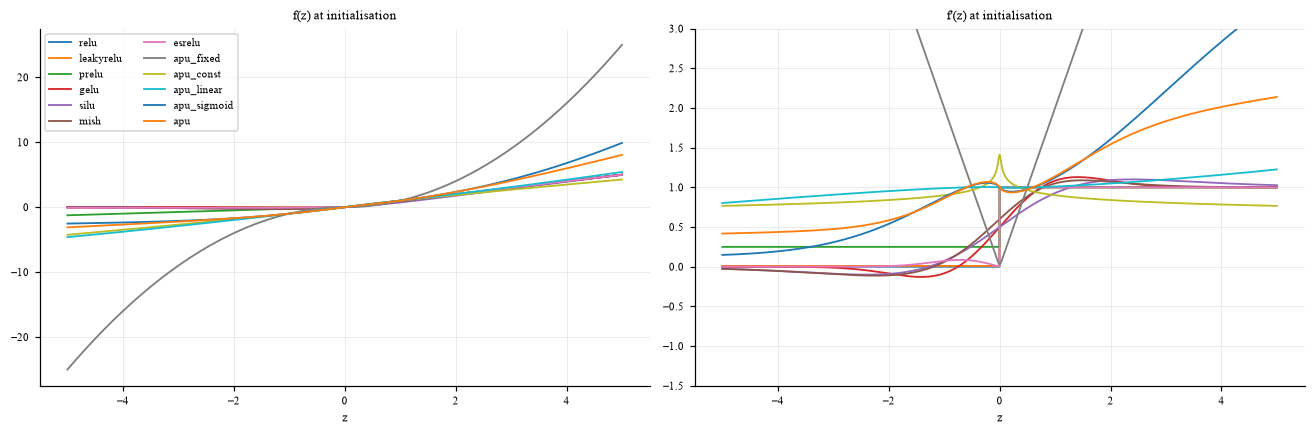

Largest |activation| at initialisation (resnet18, cifar10). Values far above the ReLU row predict unstable training:


,activation,first_layer,middle_layer,last_layer,logits_finite
0,relu,5.5,8.9,8.9,True
1,gelu,5.5,9.8,9.3,True
2,silu,5.5,10.1,10.0,True
3,apu_fixed,30.1,85428496.0,11901408.0,True
4,apu_const,4.6,6.9,6.9,True
5,apu_sigmoid,11.6,757.9,2682.0,True
6,apu_linear,6.0,14.9,13.4,True
7,apu@0.8,6.5,12.9,13.2,True
8,apu@0.9,7.7,22.0,23.9,True
9,apu@1.0,9.1,42.5,59.2,True


,activation,first_layer,middle_layer,last_layer,logits_finite
0,relu,5.483301,8.949549e+00,8.878612e+00,True
1,gelu,5.483301,9.757210e+00,9.348417e+00,True
2,silu,5.460609,1.011137e+01,9.989655e+00,True
3,apu_fixed,30.067091,8.542850e+07,1.190141e+07,True
4,apu_const,4.625270,6.937766e+00,6.859934e+00,True
5,apu_sigmoid,11.582704,7.578780e+02,2.682021e+03,True
6,apu_linear,6.019583,1.494187e+01,1.336310e+01,True
7,apu@0.8,6.473095,1.290025e+01,1.320298e+01,True
8,apu@0.9,7.673913,2.204839e+01,2.386541e+01,True
9,apu@1.0,9.097494,4.247186e+01,5.915041e+01,True


In [45]:
# ===== 11. Theory checks (at init and with trained parameters) and dead-unit rate =====
def _grid(lo=-5, hi=5, n=4001): return torch.linspace(lo, hi, n, device=device)

def lipschitz_estimate(act, lo=-5, hi=5, n=4001):
    """Empirical (finite-difference) estimate over [lo, hi]. An estimate, not a proof."""
    x = _grid(lo, hi, n)
    with torch.no_grad(): y = act(x)
    return ((y[1:] - y[:-1]) / (x[1:] - x[:-1])).abs().max().item()

def derivative_check(act, lo=-5, hi=5, n=4001):
    x = _grid(lo, hi, n).requires_grad_(True)
    y = act(x); g, = torch.autograd.grad(y.sum(), x)
    bad = ~torch.isfinite(g)
    return dict(finite=bool(~bad.any()), max_abs=g.abs().max().item(), min=g.min().item(), x=x.detach().cpu().numpy(), dy=g.detach().cpu().numpy(), y=y.detach().cpu().numpy())

def activation_theory(names=None, seed=0):
    names = names or (BASELINES + ["apu_fixed", "apu_const", "apu_linear", "apu_sigmoid", "apu"])
    torch.manual_seed(seed); rows, curves = [], {}
    for n in names:
        a = make_act(n).to(device); c = derivative_check(a)
        rows.append(dict(activation=n, lipschitz_est=lipschitz_estimate(a), derivative_finite=c["finite"], max_abs_derivative=c["max_abs"]))
        curves[n] = c
    t = pd.DataFrame(rows); t.to_csv(ROOT / "tables" / "theory_at_init.csv", index=False); return t, curves

def plot_activation_curves(curves, path=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for n, c in curves.items():
        ax[0].plot(c["x"], c["y"], label=n); ax[1].plot(c["x"], c["dy"], label=n)
    ax[0].set_title("f(z) at initialisation"); ax[1].set_title("f'(z) at initialisation")
    for a in ax: a.grid(alpha=.3); a.set_xlabel("z")
    ax[1].set_ylim(-1.5, 3); ax[0].legend(fontsize=7, ncol=2); plt.tight_layout()
    fig.savefig(path or ROOT / "figures" / "activation_curves_init.png", dpi=200); plt.show()

@torch.no_grad()
def dead_unit_rate(model, loader, n_batches=4, tol=1e-6):
    """Fraction of units (channels / features) whose post-activation is ~0 for every probe sample."""
    stats_, hs = {}, []
    def hook(name, cd):
        def f(m, i, o):
            o = o.detach().float(); C = o.shape[cd] if o.dim() > 1 else o.shape[0]
            alive = (o.abs() > tol).movedim(cd, -1).reshape(-1, C).any(0) if o.dim() > 1 else (o.abs() > tol)
            stats_[name] = alive if name not in stats_ else (stats_[name] | alive)
        return f
    for n, m in act_modules(model):
        hs.append(m.register_forward_hook(hook(n, getattr(m, "_cd", 1))))
    model.eval()
    for i, (x, _) in enumerate(loader):
        model(x.to(device));
        if i + 1 >= n_batches: break
    for h in hs: h.remove()
    tot = sum(v.numel() for v in stats_.values()); dead = sum((~v).sum().item() for v in stats_.values())
    return dead / max(tot, 1)

t_init, curves_init = activation_theory(); display(t_init.round(4)); plot_activation_curves(curves_init)


def activation_growth_report(dataset="cifar10", arch="resnet18", acts=None, batch=64):
    """Stability at initialisation: largest |activation output| at the first / middle / last activation layer of a freshly built network
    on a standard-normal batch. Power units can compound through residual additions, so this is checked before any training."""
    acts = acts or ["relu", "gelu", "silu", "apu_fixed", "apu_const", "apu_sigmoid", "apu_linear", "apu@0.8", "apu@0.9", "apu@1.0", "apu@1.5"]
    meta = get_meta(dataset); rows = []; x = torch.randn(batch, meta["in_ch"], meta["img"], meta["img"], device=device)
    for a in acts:
        torch.manual_seed(0); m = build_model(arch, a, meta).to(device).train(); mx = []
        hs = [mod.register_forward_hook(lambda mod, i, o: mx.append(o.detach().abs().max().item())) for _, mod in act_modules(m)]
        with torch.no_grad(): out = m(x)
        [h.remove() for h in hs]
        rows.append(dict(activation=a, first_layer=mx[0], middle_layer=mx[len(mx) // 2], last_layer=mx[-1], logits_finite=bool(torch.isfinite(out).all())))
    t = pd.DataFrame(rows); t.to_csv(ROOT / "tables" / f"growth_at_init_{dataset}_{arch}.csv", index=False)
    print(f"Largest |activation| at initialisation ({arch}, {dataset}). Values far above the ReLU row predict unstable training:")
    display(t.round(1)); return t

safe(activation_growth_report)


cifar10/resnet18: mean within-layer std of p(z) = 0.2679   std of layer-mean p across layers = 0.2777
   parameter movement from init:  |dA| = 0.2353   |dw_z| = 2.6911   |db_z| = 2.3282
   asymmetry: mean p on negative inputs = 0.614, on positive inputs = 1.059 (p < 1 compresses, p > 1 expands)
   NOTE: p(z) varies with the input by construction whenever A != 0, so within-layer variation alone is not evidence of learning.
   -> parameters moved; layer-mean p differs across layers by std 0.278. Check panels (a)-(c) of fig2 for whether that is a depth trend.


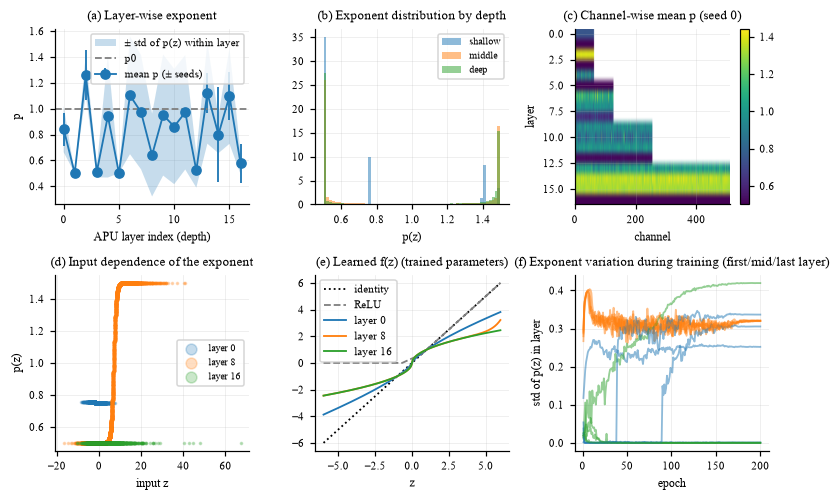

cifar100/resnet18: mean within-layer std of p(z) = 0.3046   std of layer-mean p across layers = 0.2443
   parameter movement from init:  |dA| = 0.2130   |dw_z| = 2.4762   |db_z| = 2.1947
   asymmetry: mean p on negative inputs = 0.613, on positive inputs = 1.147 (p < 1 compresses, p > 1 expands)
   NOTE: p(z) varies with the input by construction whenever A != 0, so within-layer variation alone is not evidence of learning.
   -> parameters moved; layer-mean p differs across layers by std 0.244. Check panels (a)-(c) of fig2 for whether that is a depth trend.


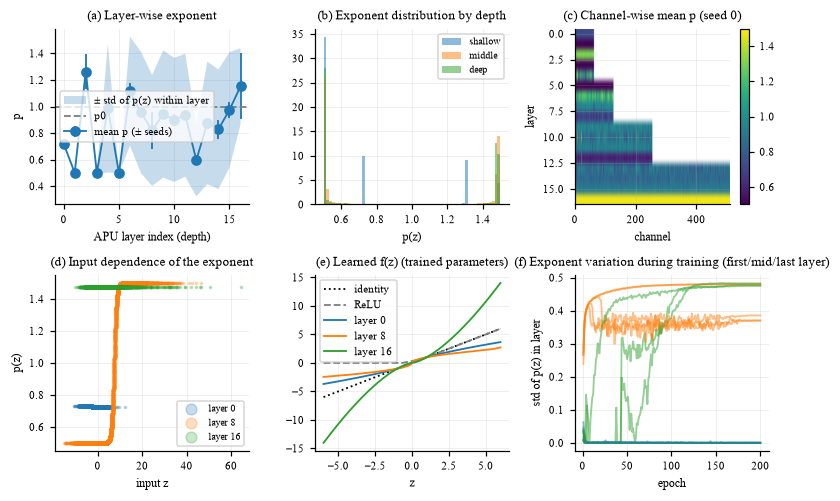

cifar10/vit_tiny: mean within-layer std of p(z) = 0.0499   std of layer-mean p across layers = 0.2030
   parameter movement from init:  |dA| = 0.2000   |dw_z| = 0.6530   |db_z| = 4.2500
   asymmetry: mean p on negative inputs = 1.412, on positive inputs = 1.463 (p < 1 compresses, p > 1 expands)
   NOTE: p(z) varies with the input by construction whenever A != 0, so within-layer variation alone is not evidence of learning.
   -> parameters moved; layer-mean p differs across layers by std 0.203. Check panels (a)-(c) of fig2 for whether that is a depth trend.


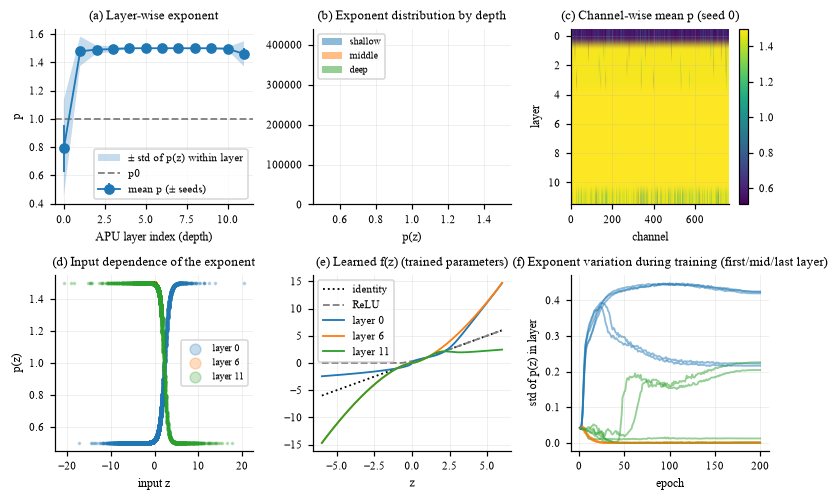

In [46]:
# ===== 12. APU-specific mechanistic analysis (uses trained checkpoints only) =====
def load_ckpt_model(rid, dataset, arch, act):
    ck = torch.load(ROOT / "ckpt" / f"{rid}.pt", map_location=device, weights_only=False)
    m = build_model(arch, act, get_meta(dataset)).to(device); m.load_state_dict(ck["model"]); return m.eval()

def runs_for(dataset, arch, act, holdout=False):
    df = load_results()
    if df.empty: return []
    d = df[(df.dataset == dataset) & (df.arch == arch) & (df.act == act) & (df.holdout == holdout) & (~df.diverged)]
    return [(r.run_id, int(r.seed)) for r in d.itertuples()]

def analyze_exponents(dataset, arch, act="apu", n_batches=8):
    """Record p(z) statistics of every APU layer for every trained seed; cache under analysis/."""
    out = {}
    for rid, seed in runs_for(dataset, arch, act):
        cache = ROOT / "analysis" / f"exp_{rid}.pt"
        if cache.exists(): out[seed] = torch.load(cache, weights_only=False); continue
        model = load_ckpt_model(rid, dataset, arch, act); _, vl = get_loaders(dataset, seed, 128)
        with torch.no_grad(), ExponentRecorder(model, max_pairs=2000) as rec:
            for i, (x, _) in enumerate(vl):
                model(x.to(device))
                if i + 1 >= n_batches: break
        out[seed] = rec.result(); torch.save(out[seed], cache)
    return out

def depth_group(i, n): return "shallow" if i < n / 3 else ("middle" if i < 2 * n / 3 else "deep")

def exponent_tables(dataset, arch, act="apu"):
    """Layer-wise table: mean p, within-layer std of p (input dependence), amplitude |A|; plus depth-group summary over seeds."""
    res = analyze_exponents(dataset, arch, act)
    if not res: print("no APU checkpoints for", dataset, arch, act); return None, None
    rows = []; _, _, ex = parse_act(act); A0 = ex.get("A", APU_DEFAULT["init_A"]); wz0 = ex.get("wz", APU_DEFAULT["init_wz"])
    for seed, layers in res.items():
        names = list(layers); n = len(names)
        for i, nme in enumerate(names):
            L = layers[nme]; full = L["mode"] == "full"
            A = float(np.mean(L["a_max"] * np.tanh(np.array(L["params"]["raw_A"])))) if full else float("nan")
            wz = float(np.mean(L["params"]["w_z"])) if "w_z" in L["params"] else float("nan")
            bz = float(np.mean(L["params"]["b_z"])) if "b_z" in L["params"] else float("nan")
            zs, ps = L.get("z"), L.get("p"); neg = float(ps[zs < 0].mean()) if zs is not None and (zs < 0).any() else float("nan"); pos = float(ps[zs > 0].mean()) if zs is not None and (zs > 0).any() else float("nan")
            rows.append(dict(seed=seed, layer=i, name=nme, depth=depth_group(i, n), p_mean=L["mean"], p_std_within=L["std"], p_neg=neg, p_pos=pos,
                             chan_spread=float(np.std(L["ch_mean"])), amplitude=abs(A) if full else float("nan"), dev_from_p0=abs(L["mean"] - L["p0"]),
                             A_change=abs(A - A0) if full else float("nan"), wz_change=abs(wz - wz0) if full else float("nan"),
                             bz_change=abs(bz) if full else float("nan")))
    t = pd.DataFrame(rows)
    g = t.groupby(["seed", "depth"])[["p_mean", "p_std_within", "chan_spread", "amplitude"]].mean().reset_index()
    summ = g.groupby("depth")[["p_mean", "p_std_within", "chan_spread", "amplitude"]].agg(["mean", "std"]).round(4)
    t.to_csv(ROOT / "tables" / f"exponent_layers_{dataset}_{arch}.csv", index=False)
    summ.to_csv(ROOT / "tables" / f"exponent_depth_summary_{dataset}_{arch}.csv"); return t, summ

def learned_curve(L, lo=-6, hi=6, n=1000):
    """Rebuild the trained activation of one layer from its saved parameters and evaluate f(z), f'(z), p(z)."""
    m = APU(mode=L["mode"], p0=L["p0"], a_max=L["a_max"], p_min=L["p_min"], p_max=L["p_max"], eps=L["eps"]).to(device)
    with torch.no_grad():
        for k, v in L["params"].items(): getattr(m, k).copy_(torch.tensor(np.mean(v), dtype=torch.float32).view(1))
    z = torch.linspace(lo, hi, n, device=device).requires_grad_(True); y = m(z); g, = torch.autograd.grad(y.sum(), z)
    return z.detach().cpu().numpy(), y.detach().cpu().numpy(), g.cpu().numpy(), m.exponent(z.detach()).detach().cpu().numpy()

def plot_exponent_analysis(dataset, arch, act="apu"):
    res = analyze_exponents(dataset, arch, act)
    if not res: print("nothing to plot"); return
    seeds = sorted(res); layers0 = res[seeds[0]]; names = list(layers0); n = len(names)
    fig, ax = plt.subplots(2, 3, figsize=(7.2, 4.6))
    # (a) layer-wise mean p, band = within-layer std (input dependence), error bars = across seeds
    M = np.array([[res[s][k]["mean"] for k in names] for s in seeds]); S = np.array([[res[s][k]["std"] for k in names] for s in seeds])
    x = np.arange(n); ax[0, 0].errorbar(x, M.mean(0), M.std(0), fmt="o-", label="mean p (± seeds)"); ax[0, 0].fill_between(x, M.mean(0) - S.mean(0), M.mean(0) + S.mean(0), alpha=.25, label="± std of p(z) within layer")
    ax[0, 0].axhline(layers0[names[0]]["p0"], ls="--", c="gray", label="p0"); ax[0, 0].set_xlabel("APU layer index (depth)"); ax[0, 0].set_ylabel("p"); ax[0, 0].set_title("(a) Layer-wise exponent"); ax[0, 0].legend(fontsize=7)
    # (b) distribution of p by depth group
    for grp, c in zip(["shallow", "middle", "deep"], ["C0", "C1", "C2"]):
        arrs = [layers0[k]["p"] for i, k in enumerate(names) if depth_group(i, n) == grp and layers0[k]["p"] is not None]
        if arrs: ax[0, 1].hist(np.concatenate(arrs), bins=60, alpha=.5, density=True, label=grp, color=c)
    ax[0, 1].set_xlabel("p(z)"); ax[0, 1].set_title("(b) Exponent distribution by depth"); ax[0, 1].legend()
    # (c) channel-wise heatmap (layers x channels, NaN-padded because widths differ)
    width = max(len(layers0[k]["ch_mean"]) for k in names); H = np.full((n, width), np.nan)
    for i, k in enumerate(names): H[i, :len(layers0[k]["ch_mean"])] = layers0[k]["ch_mean"]
    im = ax[0, 2].imshow(H, aspect="auto", cmap="viridis"); ax[0, 2].set_xlabel("channel"); ax[0, 2].set_ylabel("layer"); ax[0, 2].set_title(f"(c) Channel-wise mean p (seed {seeds[0]})"); plt.colorbar(im, ax=ax[0, 2])
    # (d) input dependence: z vs p(z) for shallow / middle / deep layer
    for idx, c in zip([0, n // 2, n - 1], ["C0", "C1", "C2"]):
        L = layers0[names[idx]]
        if L["z"] is not None: ax[1, 0].scatter(L["z"], L["p"], s=2, alpha=.25, c=c, label=f"layer {idx}")
    ax[1, 0].set_xlabel("input z"); ax[1, 0].set_ylabel("p(z)"); ax[1, 0].set_title("(d) Input dependence of the exponent"); ax[1, 0].legend(markerscale=5)
    # (e) learned f(z) at three depths (trained parameters)
    zz = np.linspace(-6, 6, 10); ax[1, 1].plot(zz, zz, "k:", label="identity"); ax[1, 1].plot(zz, np.maximum(zz, 0), "gray", ls="--", label="ReLU")
    for idx, c in zip([0, n // 2, n - 1], ["C0", "C1", "C2"]):
        z_, y_, g_, p_ = learned_curve(layers0[names[idx]]); ax[1, 1].plot(z_, y_, c=c, label=f"layer {idx}")
    ax[1, 1].set_title("(e) Learned f(z) (trained parameters)"); ax[1, 1].set_xlabel("z"); ax[1, 1].legend(fontsize=7)
    # (f) parameter / exponent trajectories over training (from logged history)
    df = load_results(); d = df[(df.dataset == dataset) & (df.arch == arch) & (df.act == act) & (~df.holdout)]
    for r in d.itertuples():
        h = r.history
        if not h or h[0].get("apu") is None: continue
        ln = list(h[0]["apu"]); first, mid, last = ln[0], ln[len(ln) // 2], ln[-1]
        for k, c in zip([first, mid, last], ["C0", "C1", "C2"]):
            ax[1, 2].plot([e["epoch"] for e in h], [e["apu"][k]["p_std"] for e in h], c=c, alpha=.5)
    ax[1, 2].set_xlabel("epoch"); ax[1, 2].set_ylabel("std of p(z) in layer"); ax[1, 2].set_title("(f) Exponent variation during training (first/mid/last layer)")
    plt.tight_layout(); fig.savefig(ROOT / "figures" / f"fig2_exponent_{dataset}_{arch}.png", dpi=200); fig.savefig(ROOT / "figures" / f"fig2_exponent_{dataset}_{arch}.pdf"); plt.show()

def adaptation_verdict(dataset, arch, act="apu"):
    """Direct answer to 'is the exponent really input-conditioned?': how far is p from p0, and does it vary with z?"""
    t, _ = exponent_tables(dataset, arch, act)
    if t is None: return
    spread = t.groupby("seed").p_mean.std().mean()
    print(f"{dataset}/{arch}: mean within-layer std of p(z) = {t.p_std_within.mean():.4f}   std of layer-mean p across layers = {spread:.4f}")
    print(f"   parameter movement from init:  |dA| = {np.nanmean(t.A_change):.4f}   |dw_z| = {np.nanmean(t.wz_change):.4f}   |db_z| = {np.nanmean(t.bz_change):.4f}")
    print(f"   asymmetry: mean p on negative inputs = {np.nanmean(t.p_neg):.3f}, on positive inputs = {np.nanmean(t.p_pos):.3f} (p < 1 compresses, p > 1 expands)")
    print("   NOTE: p(z) varies with the input by construction whenever A != 0, so within-layer variation alone is not evidence of learning.")
    moved = np.nanmax([np.nanmean(t.A_change), np.nanmean(t.wz_change), np.nanmean(t.bz_change)])
    if moved < 0.05:
        print("   -> parameters stayed near their initial values: the exponent profile is mostly the initialisation, not learned behaviour.")
    else:
        print(f"   -> parameters moved; layer-mean p differs across layers by std {spread:.3f}. Check panels (a)-(c) of fig2 for whether that is a depth trend.")

@torch.no_grad()
def _first_batch(dataset, seed=0, batch=64, holdout=False):
    tl, vl = get_loaders(dataset, seed, batch, holdout); x, y = next(iter(tl)); return x.to(device), y.to(device)

def layerwise_grad_profile(dataset, arch, act, seed=0, final=True):
    """Gradient norm of each conv/linear weight on one training batch (at init or from the trained checkpoint)."""
    x, y = _first_batch(dataset, seed)
    if final:
        rows = runs_for(dataset, arch, act); rid = [r for r, s in rows if s == seed]
        if not rid: return None
        model = load_ckpt_model(rid[0], dataset, arch, act)
    else:
        seed_everything(seed); model = build_model(arch, act, get_meta(dataset)).to(device)
    model.train(); model.zero_grad(); F.cross_entropy(model(x), y).backward()
    return [p.grad.norm().item() for n, p in model.named_parameters() if p.ndim > 1 and p.grad is not None]

def plot_gradient_dynamics(dataset, arch, acts=("relu", "gelu", "silu", "apu")):
    df = load_results(); d = df[(df.dataset == dataset) & (df.arch == arch) & (~df.holdout)]
    if d.empty: print("no runs"); return
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a in acts:
        da = d[d.act == a]
        if da.empty: continue
        G = np.array([[h["grad_norm_mean"] for h in r.history] for r in da.itertuples() if len(r.history) == len(da.iloc[0].history)])
        e = np.arange(1, G.shape[1] + 1); ax[0].plot(e, G.mean(0), label=a); ax[0].fill_between(e, G.mean(0) - G.std(0), G.mean(0) + G.std(0), alpha=.2)
        Gs = np.array([[h["grad_norm_std"] for h in r.history] for r in da.itertuples() if len(r.history) == G.shape[1]]); ax[1].plot(e, Gs.mean(0), label=a)
        for final, ls_ in [(False, "--"), (True, "-")]:
            prof = layerwise_grad_profile(dataset, arch, a, final=final)
            if prof: ax[2].plot(prof, ls_, label=f"{a} {'final' if final else 'init'}")
    ax[0].set_title("global grad norm (mean ± std over seeds)"); ax[1].set_title("within-epoch grad-norm std (stability)"); ax[2].set_title("per-layer grad norm, init (--) vs final (-)")
    ax[0].set_yscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("layer"); [a.set_xlabel("epoch") for a in ax[:2]]; ax[0].legend(); ax[2].legend(fontsize=6, ncol=2)
    plt.tight_layout(); fig.savefig(ROOT / "figures" / f"grad_{dataset}_{arch}.png", dpi=200); plt.show()

if analysis_on():
    for ds, ar in P["main_grid"][:3]:
        if not load_results().empty and runs_for(ds, ar, "apu"):
            safe(adaptation_verdict, ds, ar); safe(plot_exponent_analysis, ds, ar)
else:
    print("analysis skipped (add 'analysis' to APU_STAGES)")


In [47]:
# ===== 13. Robustness: common-corruption evaluation (+ optional PGD) on the saved checkpoints =====
# Official CIFAR-10-C / CIFAR-100-C are used if CIFAR_C_DIR is set. Otherwise a re-implemented SUBSET of the corruptions
# with approximate severity schedules is used; those numbers are for development and must not be reported as CIFAR-C.
CORRUPTIONS = ["gaussian_noise", "shot_noise", "impulse_noise", "speckle_noise", "gaussian_blur", "brightness", "contrast", "pixelate"]
_SEV = dict(gaussian_noise=[.04, .06, .08, .09, .10], shot_noise=[500, 250, 100, 75, 50], impulse_noise=[.01, .02, .03, .05, .07],
            speckle_noise=[.06, .1, .12, .16, .2], gaussian_blur=[.4, .6, .7, .8, 1.0], brightness=[.05, .10, .15, .20, .30], contrast=[.75, .5, .4, .3, .15], pixelate=[.95, .9, .85, .75, .65])

def corrupt(x, name, severity):
    """x: float tensor in [0,1], shape (B,C,H,W). severity 1..5."""
    c = _SEV[name][severity - 1]
    if name == "gaussian_noise": y = x + torch.randn_like(x) * c
    elif name == "shot_noise":   y = torch.poisson(x * c) / c
    elif name == "impulse_noise":
        u = torch.rand_like(x); y = x.clone(); y[u < c / 2] = 0.0; y[u > 1 - c / 2] = 1.0
    elif name == "speckle_noise": y = x + x * torch.randn_like(x) * c
    elif name == "gaussian_blur":
        k = 2 * math.ceil(3 * c) + 1; y = T.functional.gaussian_blur(x, [k, k], [c, c])
    elif name == "brightness":   y = x + c
    elif name == "contrast":
        m = x.mean(dim=(2, 3), keepdim=True); y = (x - m) * c + m
    elif name == "pixelate":
        h = x.shape[-1]; s = max(int(h * c), 2); y = F.interpolate(F.interpolate(x, size=(s, s), mode="area"), size=(h, h), mode="nearest")
    else: raise ValueError(name)
    return y.clamp(0, 1)

def load_clean_test(dataset):
    ds = base_dataset(dataset, "test", T.ToTensor()); xs, ys = [], []
    for x, y in DataLoader(ds, batch_size=500, num_workers=0): xs.append(x); ys.append(y)
    return torch.cat(xs), torch.cat(ys)

def load_official_c(dataset, name, severity):
    root = Path(CIFAR_C_DIR) / ("CIFAR-10-C" if dataset == "cifar10" else "CIFAR-100-C")
    f = root / f"{name}.npy"
    if not f.exists(): return None
    a = np.load(f)[(severity - 1) * 10000: severity * 10000]; y = np.load(root / "labels.npy")[:10000]
    return torch.from_numpy(a).permute(0, 3, 1, 2).float() / 255.0, torch.from_numpy(y).long()

@torch.no_grad()
def acc_on(model, x01, y, meta, bs=500):
    mean = torch.tensor(meta["mean"], device=device).view(1, -1, 1, 1); std = torch.tensor(meta["std"], device=device).view(1, -1, 1, 1)
    c = 0
    for i in range(0, len(x01), bs):
        xb = ((x01[i:i + bs].to(device) - mean) / std); out = model(xb).float(); c += (out.argmax(1).cpu() == y[i:i + bs]).sum().item()
    return 100 * c / len(x01)

def corruption_eval(dataset, arch, acts, seeds=None):
    meta = get_meta(dataset); x, y = load_clean_test(dataset); use_official = bool(CIFAR_C_DIR) and not P["fake"]
    for act in acts:
        for rid, seed in runs_for(dataset, arch, act):
            out_f = ROOT / "robust" / f"{rid}.json"
            if out_f.exists() or (seeds is not None and seed not in seeds): continue
            torch.manual_seed(0); model = load_ckpt_model(rid, dataset, arch, act); res = dict(run_id=rid, clean=acc_on(model, x, y, meta), source="official" if use_official else "reimplemented-subset", acc={})
            for cname in CORRUPTIONS:
                accs = []
                for s in range(1, 6):
                    if use_official:
                        got = load_official_c(dataset, cname, s)
                        if got is None: continue
                        xc, yc = got
                    else: xc, yc = corrupt(x, cname, s), y
                    accs.append(acc_on(model, xc, yc, meta))
                if accs: res["acc"][cname] = accs
            json.dump(res, open(out_f, "w"))

def robustness_table(dataset, arch, ref="relu"):
    """Clean accuracy, mean corruption accuracy, and relative mCE (mean over corruptions of err_act / err_ref, x100)."""
    rows = []
    for f in (ROOT / "robust").glob("*.json"):
        r = json.load(open(f)); rid = r["run_id"]
        if not rid.startswith(f"{dataset}-{arch}-"): continue
        parts = rid.split("-"); act = parts[2]; seed = int(parts[3][1:])
        err = {c: 100 - np.mean(v) for c, v in r["acc"].items()}
        rows.append(dict(act=act, seed=seed, clean=r["clean"], corrupt_acc=100 - np.mean(list(err.values())), err=err, source=r["source"]))
    if not rows: print("no robustness results yet"); return None
    d = pd.DataFrame(rows)
    ref_err = {c: np.mean([r["err"][c] for _, r in d[d.act == ref].iterrows()]) for c in CORRUPTIONS if any(c in e for e in d[d.act == ref].err)} if (d.act == ref).any() else {}
    d["rel_mCE"] = [100 * np.mean([e[c] / ref_err[c] for c in ref_err if c in e]) if ref_err else float("nan") for e in d.err]
    g = d.groupby("act")[["clean", "corrupt_acc", "rel_mCE"]].agg(["mean", "std"]).round(2)
    g.to_csv(ROOT / "tables" / f"robustness_{dataset}_{arch}.csv"); print("source:", d.source.iloc[0]); return g

def pgd_eval(dataset, arch, acts, eps_list=(1, 2, 4, 8), n=1000, steps=10):
    """OPTIONAL adversarial check. Interpret with care: sanity-check for gradient masking (accuracy should reach ~0 at large eps)."""
    meta = get_meta(dataset); x, y = load_clean_test(dataset); x, y = x[:n].to(device), y[:n].to(device)
    mean = torch.tensor(meta["mean"], device=device).view(1, -1, 1, 1); std = torch.tensor(meta["std"], device=device).view(1, -1, 1, 1)
    rows = []
    for act in acts:
        for rid, seed in runs_for(dataset, arch, act):
            model = load_ckpt_model(rid, dataset, arch, act); f = lambda z: model((z - mean) / std); row = dict(act=act, seed=seed)
            for e in eps_list:
                eps = e / 255; xa = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
                for _ in range(steps):
                    xa.requires_grad_(True); g, = torch.autograd.grad(F.cross_entropy(f(xa), y), xa)
                    xa = (x + (xa.detach() + 2.5 * eps / steps * g.sign() - x).clamp(-eps, eps)).clamp(0, 1)
                with torch.no_grad(): row[f"pgd_eps{e}"] = 100 * (f(xa).argmax(1) == y).float().mean().item()
            rows.append(row)
    return pd.DataFrame(rows).groupby("act").mean(numeric_only=True).round(2) if rows else None

def load_robust(dataset, arch):
    """Long table of corruption results: act, seed, corruption, severity, acc (+ clean accuracy)."""
    rows = []
    for f in (ROOT / "robust").glob("*.json"):
        r = json.load(open(f)); rid = r["run_id"]
        if not rid.startswith(f"{dataset}-{arch}-") or r.get("kind") == "pgd": continue
        parts = rid.split("-"); act = parts[2]; seed = int(parts[3][1:])
        for c, accs in r["acc"].items():
            for s_, a_ in enumerate(accs, 1): rows.append(dict(act=act, seed=seed, corruption=c, severity=s_, acc=a_, clean=r["clean"], source=r["source"]))
    return pd.DataFrame(rows)

def pgd_table(dataset, arch, acts=("relu", "gelu", "silu", "apu"), eps_list=(1, 2, 4, 8), n=1000):
    """OPTIONAL adversarial check on a subset (PGD-10, L-inf). Accuracy must fall to ~0 at the largest eps, otherwise suspect gradient masking."""
    f = ROOT / "robust" / f"pgd_{dataset}_{arch}.csv"
    if f.exists(): return pd.read_csv(f)
    meta = get_meta(dataset); x, y = load_clean_test(dataset); x, y = x[:n].to(device), y[:n].to(device)
    mean = torch.tensor(meta["mean"], device=device).view(1, -1, 1, 1); std = torch.tensor(meta["std"], device=device).view(1, -1, 1, 1); rows = []
    for act in acts:
        for rid, seed in runs_for(dataset, arch, act):
            model = load_ckpt_model(rid, dataset, arch, act); fwd = lambda z: model((z - mean) / std)
            with torch.no_grad(): rows.append(dict(act=act, seed=seed, eps=0, acc=100 * (fwd(x).argmax(1) == y).float().mean().item()))
            for e in eps_list:
                eps = e / 255; xa = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
                for _ in range(10):
                    xa.requires_grad_(True); g, = torch.autograd.grad(F.cross_entropy(fwd(xa), y), xa)
                    xa = (x + (xa.detach() + 2.5 * eps / 10 * g.sign() - x).clamp(-eps, eps)).clamp(0, 1)
                with torch.no_grad(): rows.append(dict(act=act, seed=seed, eps=e, acc=100 * (fwd(xa).argmax(1) == y).float().mean().item()))
    t = pd.DataFrame(rows); t.to_csv(f, index=False); return t

if analysis_on():
    for ds, ar in P["robust_grid"]:
        if runs_for(ds, ar, "relu"):
            safe(corruption_eval, ds, ar, MAIN_ACTS); display(safe(robustness_table, ds, ar))
            if not SMOKE or True: safe(pgd_table, ds, ar)
else:
    print("robustness skipped (add 'analysis' to APU_STAGES)")


source: reimplemented-subset


clean       corrupt_acc       rel_mCE      
            mean   std        mean   std    mean   std
act                                                   
apu        94.50  0.16       62.86  1.16  105.96  2.56
esrelu     95.05  0.12       64.91  0.88   99.48  2.12
gelu       94.98  0.10       64.97  0.91   99.90  1.94
leakyrelu  95.01  0.16       64.65  0.69  100.19  1.89
mish       95.00  0.08       64.87  0.77   99.94  2.00
prelu      94.70  0.09       64.30  1.06  102.47  2.52
relu       94.92  0.12       64.76  0.85  100.00  1.56
silu       95.04  0.20       65.92  0.40   97.40  0.97

source: reimplemented-subset


clean       corrupt_acc       rel_mCE      
            mean   std        mean   std    mean   std
act                                                   
apu        75.43  0.47       40.12  0.58   99.78  0.72
esrelu     77.08  0.14       40.31  0.43   99.11  0.61
gelu       77.28  0.13       40.34  0.31   99.12  0.43
leakyrelu  76.80  0.16       39.80  0.27   99.96  0.40
mish       77.26  0.27       40.98  0.40   98.04  0.62
prelu      75.43  0.35       38.39  0.47  102.93  0.79
relu       76.65  0.24       39.85  0.65  100.00  0.87
silu       77.43  0.24       41.12  0.39   97.76  0.50

In [48]:
# ===== 14. Efficiency: parameters, FLOPs, latency, train-step time, peak memory, relative overhead =====
from torch.utils.flop_counter import FlopCounterMode

def _sync():
    if IS_CUDA: torch.cuda.synchronize()

def _time(fn, warm, iters):
    for _ in range(warm): fn()
    _sync(); ts = []
    for _ in range(iters):
        t = time.perf_counter(); fn(); _sync(); ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))

_EFF_WARM = [False]
def _warm_gpu(dataset, arch):
    """One throw-away model so cuDNN autotuning / the allocator do not distort the first measured activation."""
    if _EFF_WARM[0]: return
    meta = get_meta(dataset); m = build_model(arch, "relu", meta).to(device).train(); x = torch.randn(8, meta["in_ch"], meta["img"], meta["img"], device=device)
    for _ in range(3): m(x).sum().backward()
    _sync(); del m; (torch.cuda.empty_cache() if IS_CUDA else None); _EFF_WARM[0] = True

def efficiency_profile(dataset, arch, act, batch=None, compiled=None):
    """One measurement round. FLOPs come from torch's FlopCounterMode (matmul/conv only: elementwise activation cost is NOT included).
    Latency, train-step time and peak memory are measured and do capture the real cost of the activation.
    Precision: *_ms columns are fp32; *_amp_ms use bf16/fp16 autocast like the training runs (APU computes its power in fp32 either way)."""
    meta = get_meta(dataset); batch = batch or (4 if SMOKE else 128); compiled = P['compile'] if compiled is None else compiled
    _warm_gpu(dataset, arch); seed_everything(0); model = build_model(arch, act, meta).to(device); H = meta["img"]; C = meta["in_ch"]
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    act_params = sum(p.numel() for _, m in act_modules(model) for p in m.parameters(recurse=False))
    act_elems = [0]
    hs = [m.register_forward_hook(lambda m, i, o: act_elems.__setitem__(0, act_elems[0] + o[0].numel())) for _, m in act_modules(model)]
    model.eval(); x1 = torch.randn(1, C, H, H, device=device)
    with torch.no_grad(), FlopCounterMode(display=False) as fc: model(x1)
    flops = fc.get_total_flops(); [h.remove() for h in hs]
    xb = torch.randn(batch, C, H, H, device=device); yb = torch.randint(0, meta["num_classes"], (batch,), device=device)
    n_it, warm = (3, 1) if SMOKE else (30, 5)
    amp_ctx = (lambda: torch.autocast("cuda", dtype=amp_dtype())) if IS_CUDA else contextlib.nullcontext
    with torch.no_grad():
        lat1 = _time(lambda: model(x1), warm, n_it); latb = _time(lambda: model(xb), warm, n_it)
        def f_amp():
            with amp_ctx(): model(xb)
        lat_amp = _time(f_amp, warm, n_it)
    model.train(); opt = torch.optim.SGD(model.parameters(), 0.01)
    def train_step():
        opt.zero_grad(set_to_none=True)
        with amp_ctx(): loss = F.cross_entropy(model(xb), yb)
        loss.backward(); opt.step()
    if IS_CUDA: torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    step_ms = _time(train_step, warm, max(n_it // 2, 2)); mem = torch.cuda.max_memory_allocated() / 2**20 if IS_CUDA else float("nan")
    step_c_ms, mem_c = float("nan"), float("nan"); comp_ms = float("nan")
    if compiled:
        try:
            mc = torch.compile(model.eval())
            with torch.no_grad(): comp_ms = _time(lambda: mc(xb), warm + 2, n_it)
        except Exception as e: print("compile skipped:", repr(e)[:100])
    del model, opt
    if compiled and act in ("relu", "gelu", "silu", "mish", "apu"):            # compiled training step (what the training runs use when compile works)
        try:
            seed_everything(0); reset_compile_state(); mdl = build_model(arch, act, meta).to(device).train(); mcomp = torch.compile(mdl); o2 = torch.optim.SGD(mdl.parameters(), 0.01)
            def train_step_c():
                o2.zero_grad(set_to_none=True)
                with amp_ctx(): l2 = F.cross_entropy(mcomp(xb), yb)
                l2.backward(); o2.step()
            for _ in range(3): train_step_c()                                   # compile + warm-up
            if IS_CUDA: torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            step_c_ms = _time(train_step_c, 2, max(n_it // 2, 2)); mem_c = torch.cuda.max_memory_allocated() / 2**20 if IS_CUDA else float("nan")
            del mdl, mcomp, o2
        except Exception as e: print("compiled train step skipped:", repr(e)[:100])
    return dict(train_step_compiled_ms=step_c_ms, peak_mem_compiled_mb=mem_c, dataset=dataset, arch=arch, act=act, params=params, act_params=act_params, gflops=flops / 1e9, act_elements_per_img=act_elems[0],
                latency_bs1_ms=lat1, latency_bs_ms=latb, latency_bs_amp_ms=lat_amp, latency_bs_compiled_ms=comp_ms, train_step_ms=step_ms, peak_mem_mb=mem, batch=batch)

def table4_efficiency(dataset, arch, acts=None, ref="relu", rounds=None):
    """Interleaved rounds (every activation once per round), median over rounds: removes order and clock-speed effects."""
    acts = acts or (MAIN_ACTS + ["apu_fixed", "apu_const", "apu_linear", "apu_sigmoid"]); rounds = rounds or (1 if SMOKE else 3)
    runs = [[efficiency_profile(dataset, arch, a) for a in acts] for _ in range(rounds)]
    num = ["latency_bs1_ms", "latency_bs_ms", "latency_bs_amp_ms", "latency_bs_compiled_ms", "train_step_ms", "peak_mem_mb", "train_step_compiled_ms", "peak_mem_compiled_mb"]
    t = pd.DataFrame(runs[0])
    for c in num: t[c] = np.nanmedian(np.array([[r[i][c] for i in range(len(acts))] for r in runs]), axis=0) if rounds > 1 else t[c]
    df = load_results()
    if len(df):   # measured training time per epoch from the actual runs (mean over seeds; note whether runs were compiled)
        et = df[(df.dataset == dataset) & (df.arch == arch) & (~df.holdout) & (~df.diverged)].groupby("act").median_epoch_time.mean()
        t["epoch_time_s"] = t.act.map(et)
    base = t[t.act == ref].iloc[0]
    for c in ["params", "gflops"] + num[:3] + num[4:] + (["epoch_time_s"] if "epoch_time_s" in t else []):
        if c not in t or not np.isfinite(base[c]): continue
        t[f"{c}_overhead_%"] = 100 * (t[c] - base[c]) / base[c]        # 100 * (APU cost - baseline cost) / baseline cost
    t.to_csv(ROOT / "tables" / f"table4_efficiency_{dataset}_{arch}.csv", index=False)
    (ROOT / "tables" / f"table4_efficiency_{dataset}_{arch}.tex").write_text(t.round(3).to_latex(index=False)); return t

EFF = {}
if analysis_on():
    for ds, ar in P["main_grid"][:2] + P["imagenet_grid"][:1]:
        try:
            EFF[(ds, ar)] = table4_efficiency(ds, ar); display(EFF[(ds, ar)].round(3))
        except Exception as e:
            print("efficiency skipped for", ds, ar, repr(e)[:120])
else:
    print("efficiency table skipped (add 'analysis' to APU_STAGES)")


,train_step_compiled_ms,peak_mem_compiled_mb,dataset,arch,act,params,act_params,gflops,act_elements_per_img,latency_bs1_ms,...,params_overhead_%,gflops_overhead_%,latency_bs1_ms_overhead_%,latency_bs_ms_overhead_%,latency_bs_amp_ms_overhead_%,train_step_ms_overhead_%,peak_mem_mb_overhead_%,train_step_compiled_ms_overhead_%,peak_mem_compiled_mb_overhead_%,epoch_time_s_overhead_%
0,12.345,490.707,cifar10,resnet18,relu,11173962,0,1.111,557056,3.027,...,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,NaN,NaN,cifar10,resnet18,leakyrelu,11173962,0,1.111,557056,2.998,...,0.0,0.0,-0.958,0.408,0.189,1.962,32.590,NaN,NaN,1.366
2,NaN,NaN,cifar10,resnet18,prelu,11173979,17,1.111,557056,3.170,...,0.0,0.0,4.706,0.052,4.289,7.421,32.594,NaN,NaN,14.200
3,12.130,535.988,cifar10,resnet18,gelu,11173962,0,1.111,557056,3.005,...,0.0,0.0,-0.743,-0.651,1.333,1.257,32.590,-1.746,9.228,7.055
4,12.142,535.988,cifar10,resnet18,silu,11173962,0,1.111,557056,3.018,...,0.0,0.0,-0.306,-0.335,0.895,0.955,32.590,-1.646,9.228,6.910
5,12.213,535.988,cifar10,resnet18,mish,11173962,0,1.111,557056,3.010,...,0.0,0.0,-0.563,-0.154,3.157,1.980,32.590,-1.068,9.228,8.280
6,NaN,NaN,cifar10,resnet18,esrelu,11173962,0,1.111,557056,5.414,...,0.0,0.0,78.845,44.164,103.449,85.408,179.300,NaN,NaN,10.390
7,16.115,548.496,cifar10,resnet18,apu,11174013,51,1.111,557056,7.879,...,0.0,0.0,160.263,87.174,178.315,226.528,335.552,30.537,11.777,39.204
8,NaN,NaN,cifar10,resnet18,apu_fixed,11173962,0,1.111,557056,5.765,...,0.0,0.0,90.437,56.862,123.504,120.505,268.165,NaN,NaN,NaN
9,NaN,NaN,cifar10,resnet18,apu_const,11173979,17,1.111,557056,6.709,...,0.0,0.0,121.631,42.970,100.639,170.109,269.146,NaN,NaN,NaN


,train_step_compiled_ms,peak_mem_compiled_mb,dataset,arch,act,params,act_params,gflops,act_elements_per_img,latency_bs1_ms,...,params_overhead_%,gflops_overhead_%,latency_bs1_ms_overhead_%,latency_bs_ms_overhead_%,latency_bs_amp_ms_overhead_%,train_step_ms_overhead_%,peak_mem_mb_overhead_%,train_step_compiled_ms_overhead_%,peak_mem_compiled_mb_overhead_%,epoch_time_s_overhead_%
0,11.471,491.256,cifar100,resnet18,relu,11220132,0,1.111,557056,3.034,...,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,NaN,NaN,cifar100,resnet18,leakyrelu,11220132,0,1.111,557056,3.032,...,0.0,0.0,-0.063,0.036,0.069,0.746,32.562,NaN,NaN,1.309
2,NaN,NaN,cifar100,resnet18,prelu,11220149,17,1.111,557056,3.190,...,0.0,0.0,5.139,0.297,4.238,8.171,32.566,NaN,NaN,14.328
3,12.172,536.538,cifar100,resnet18,gelu,11220132,0,1.111,557056,2.995,...,0.0,0.0,-1.259,-0.492,1.263,1.158,32.562,6.117,9.217,6.989
4,12.199,536.538,cifar100,resnet18,silu,11220132,0,1.111,557056,3.008,...,0.0,0.0,-0.837,-0.684,0.724,0.865,32.562,6.349,9.217,6.874
5,12.246,536.538,cifar100,resnet18,mish,11220132,0,1.111,557056,3.000,...,0.0,0.0,-1.113,-0.485,2.837,1.802,32.562,6.759,9.217,8.252
6,NaN,NaN,cifar100,resnet18,esrelu,11220132,0,1.111,557056,5.384,...,0.0,0.0,77.478,43.776,104.474,85.203,179.104,NaN,NaN,10.390
7,16.095,549.221,cifar100,resnet18,apu,11220183,51,1.111,557056,7.871,...,0.0,0.0,159.451,87.156,177.437,226.323,335.264,40.309,11.799,39.304
8,NaN,NaN,cifar100,resnet18,apu_fixed,11220132,0,1.111,557056,5.642,...,0.0,0.0,85.994,56.054,123.848,120.284,267.935,NaN,NaN,NaN
9,NaN,NaN,cifar100,resnet18,apu_const,11220149,17,1.111,557056,6.676,...,0.0,0.0,120.070,43.015,101.114,169.224,268.915,NaN,NaN,22.454


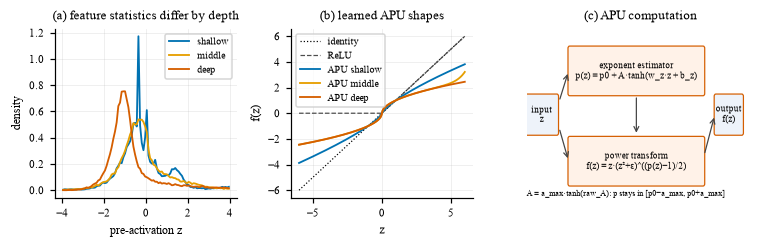

no results for imagenet


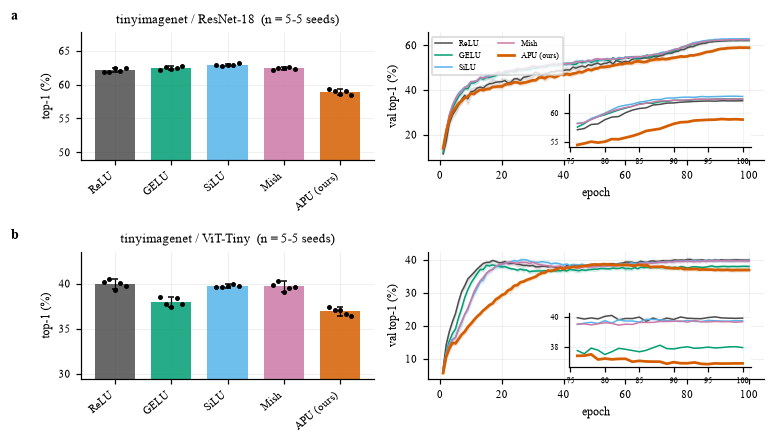

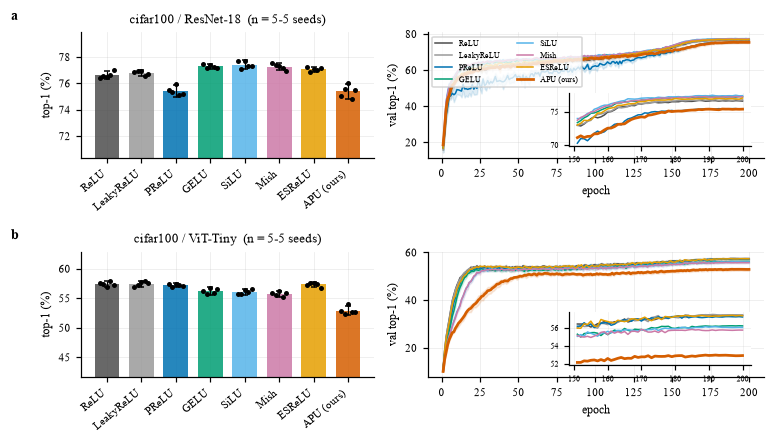

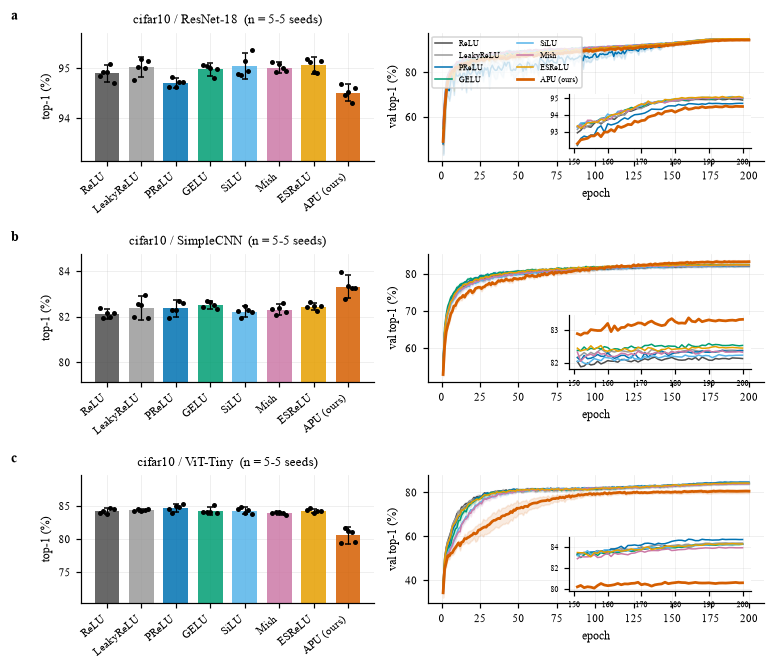

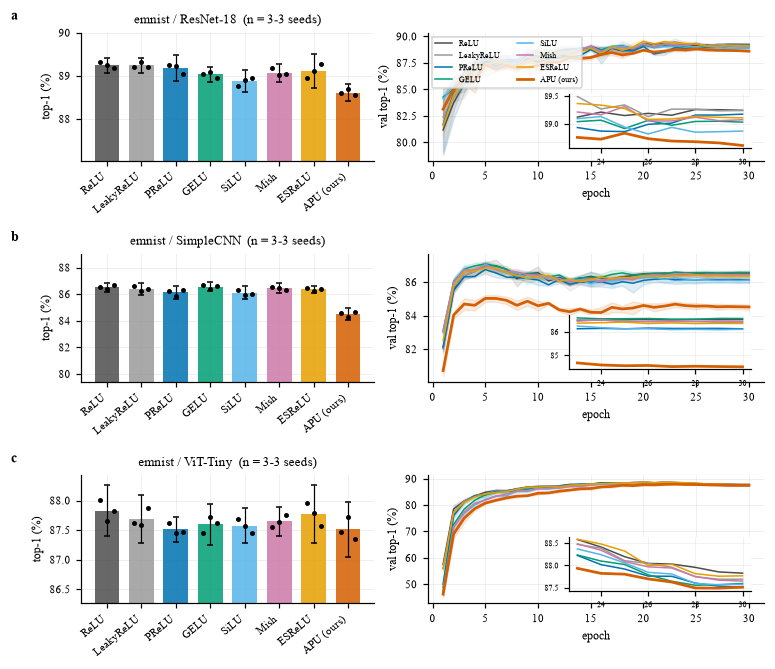

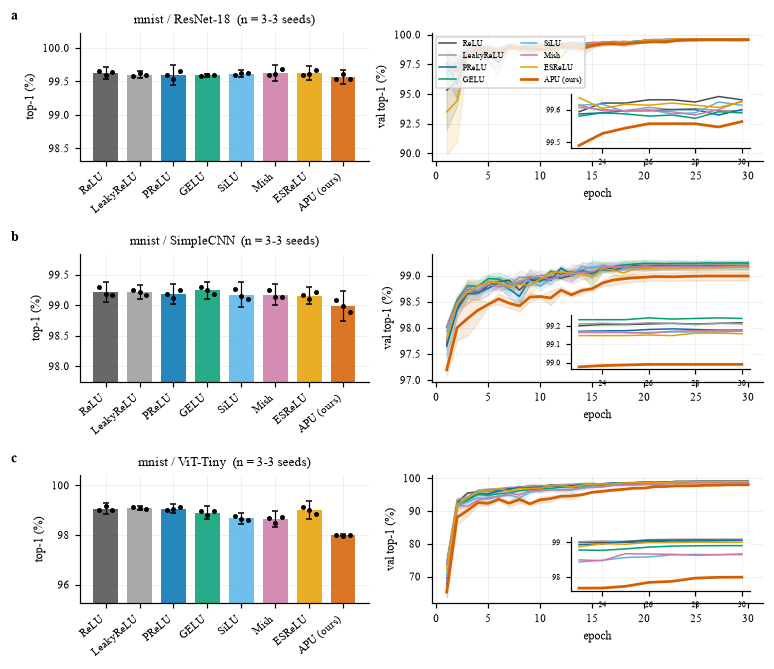

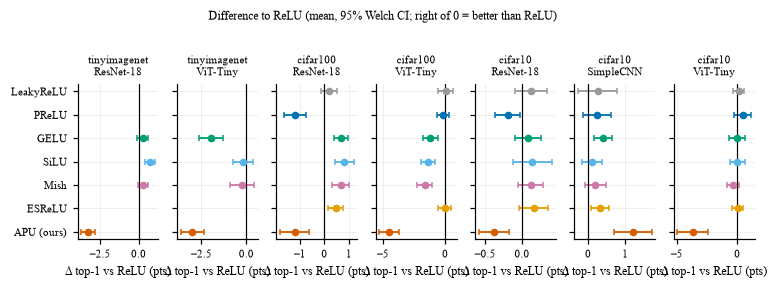

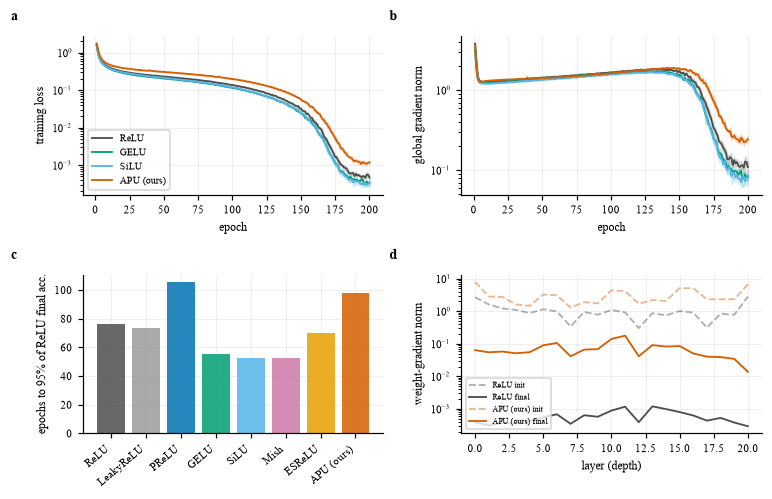

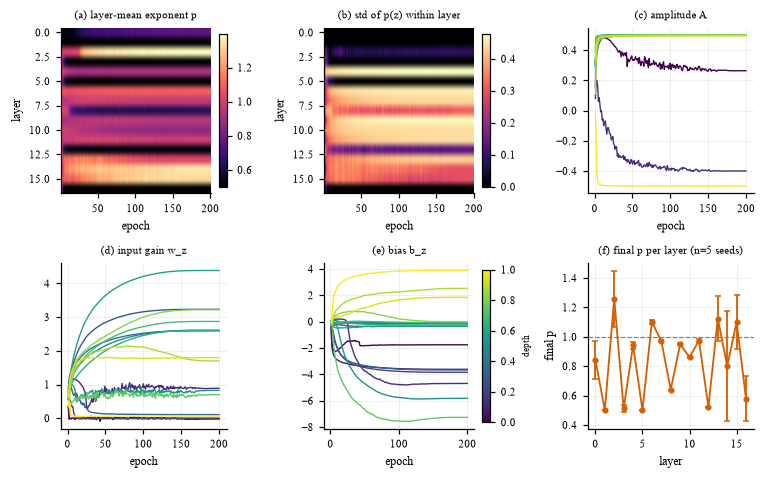

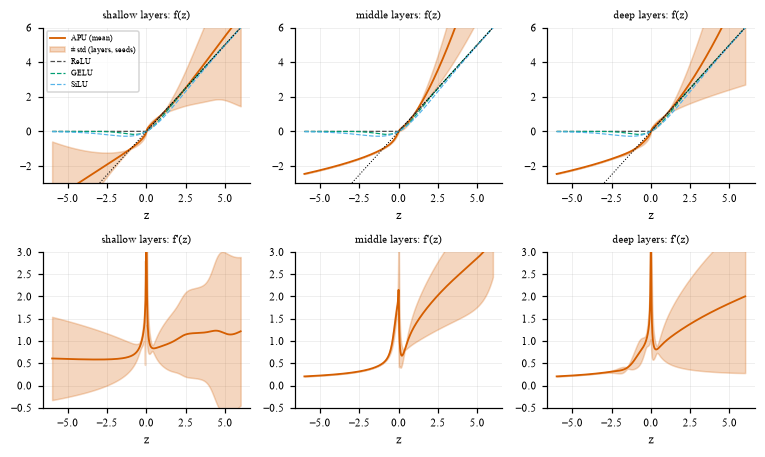

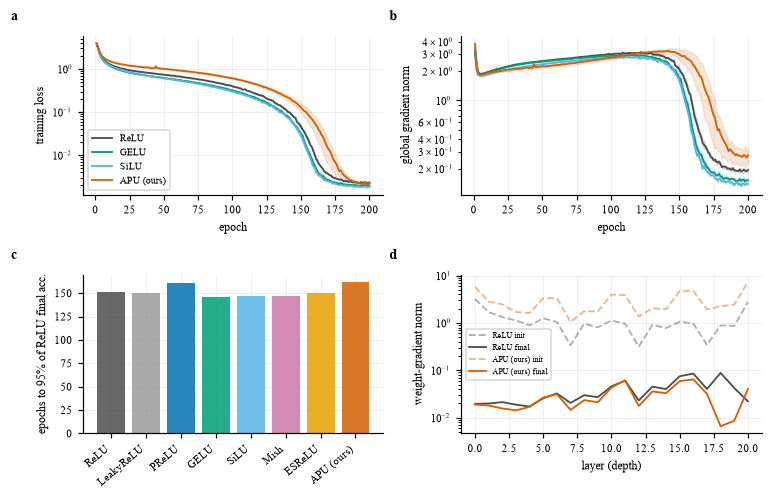

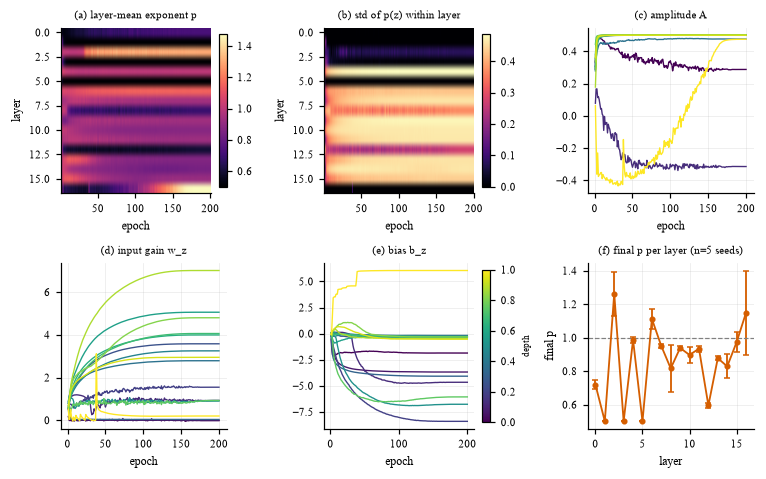

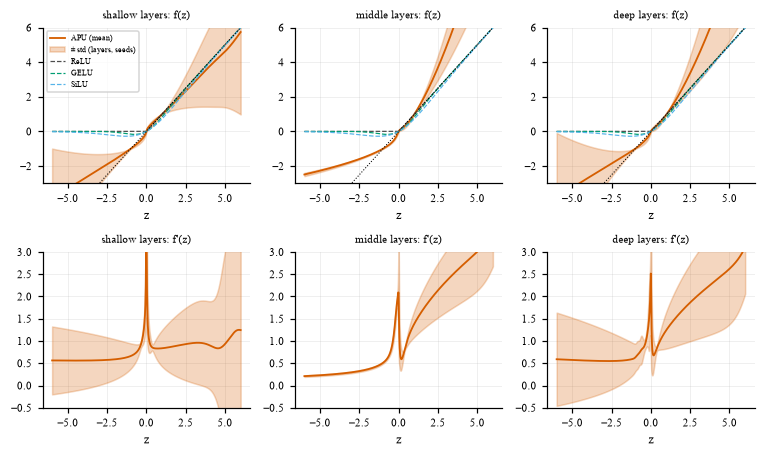

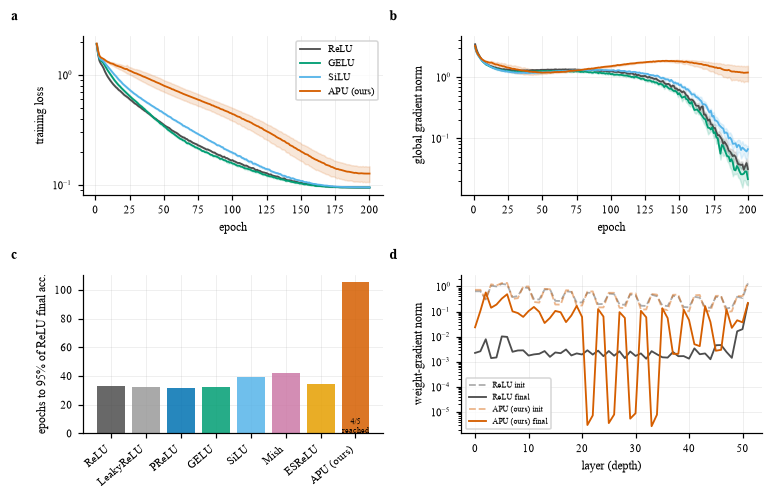

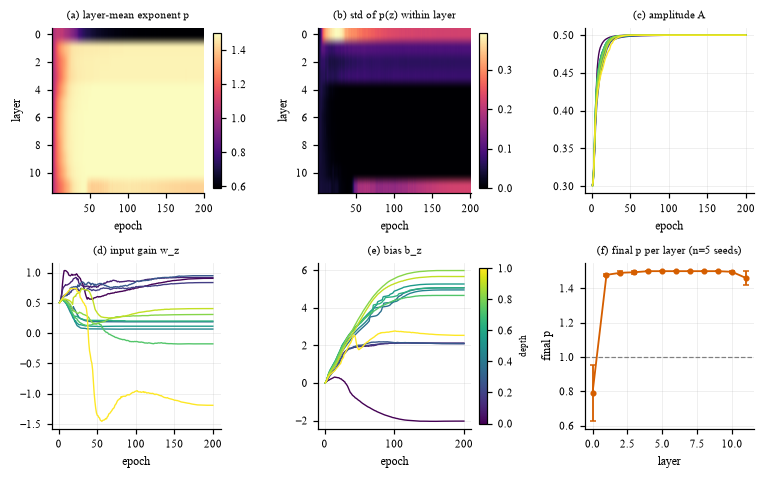

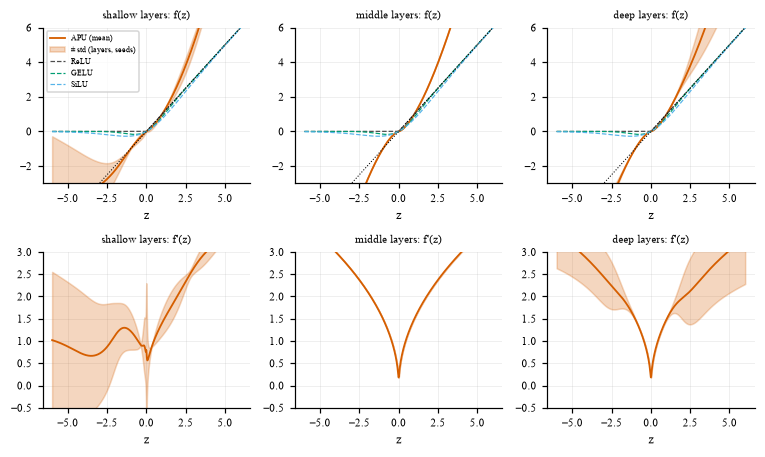

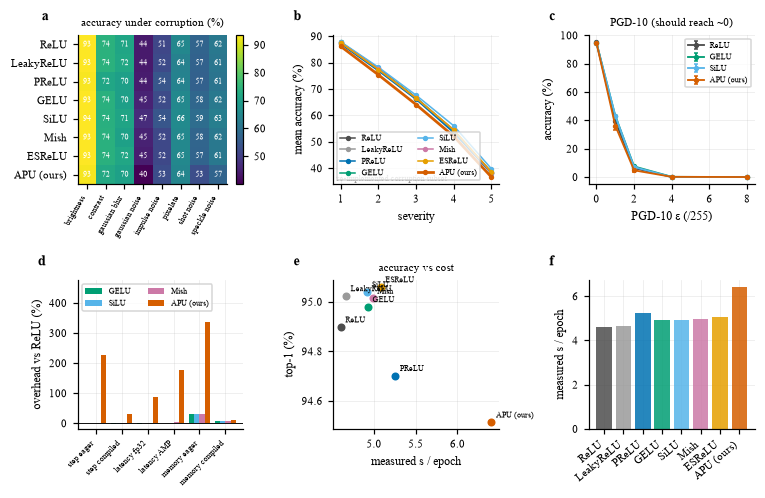

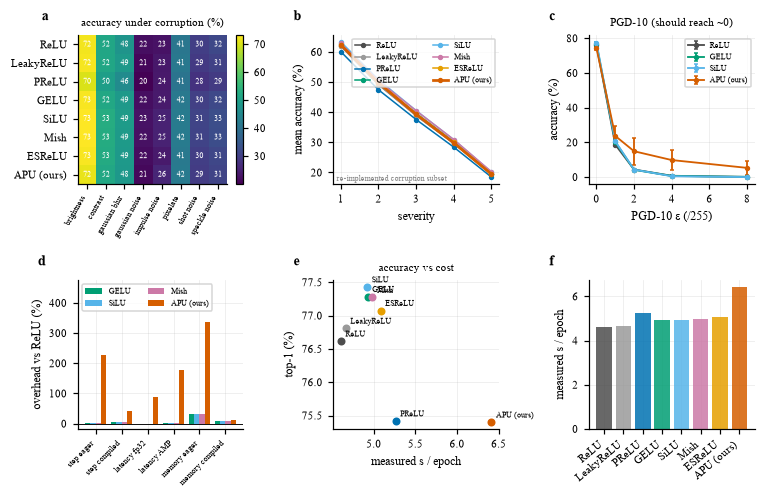

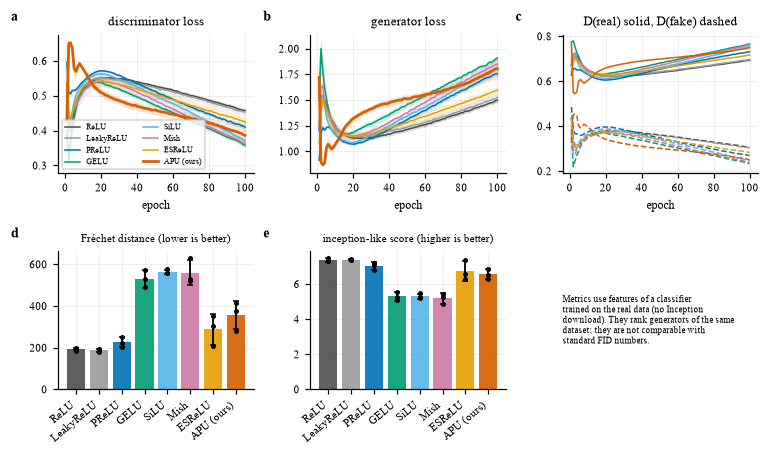

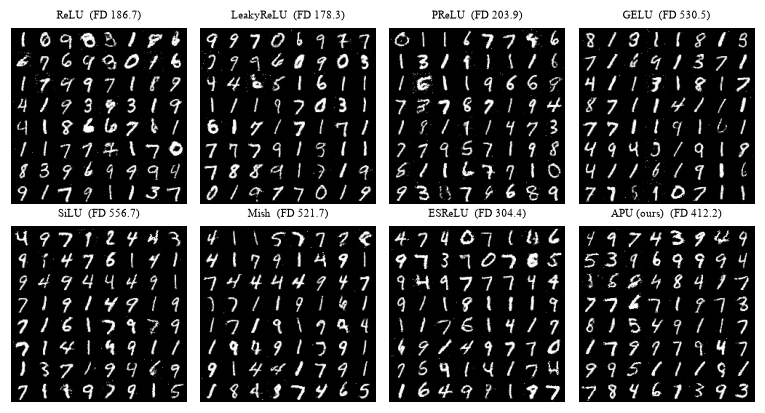

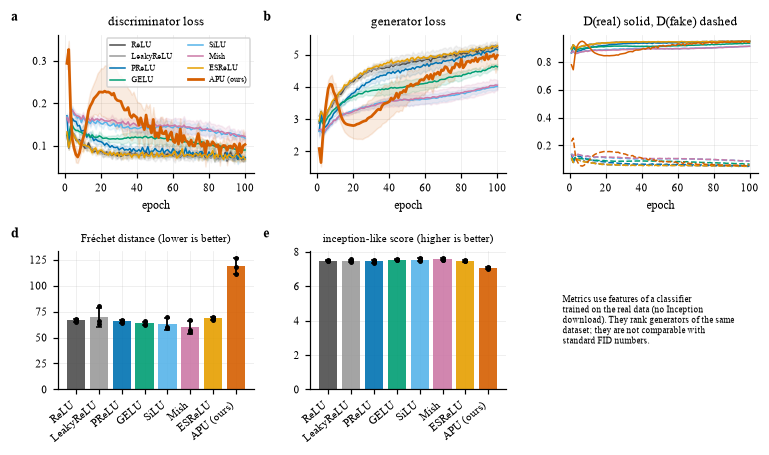

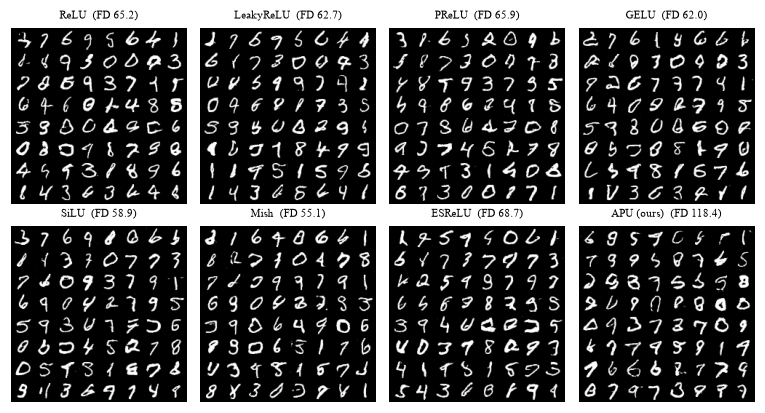

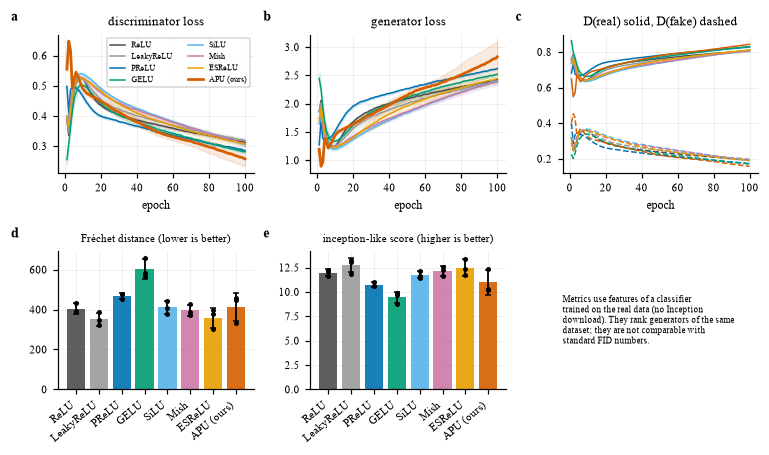

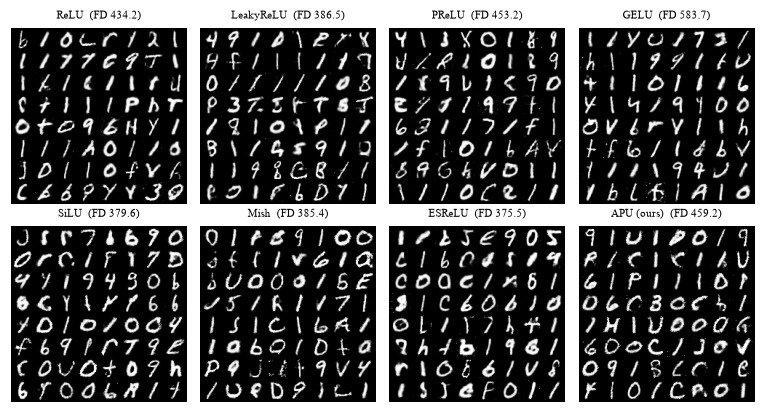

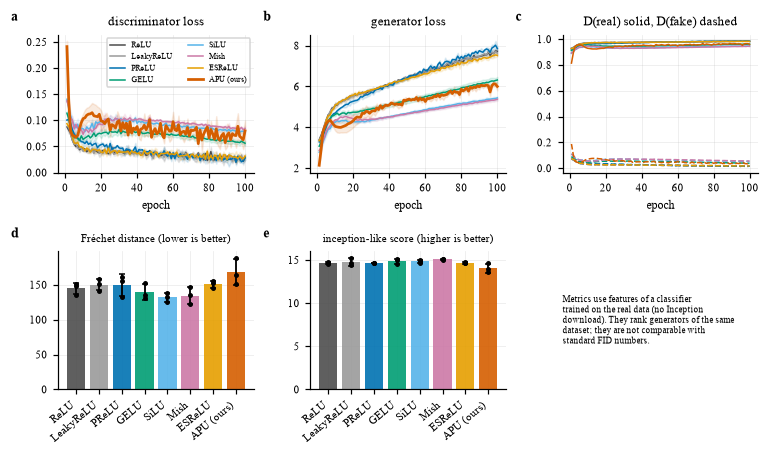

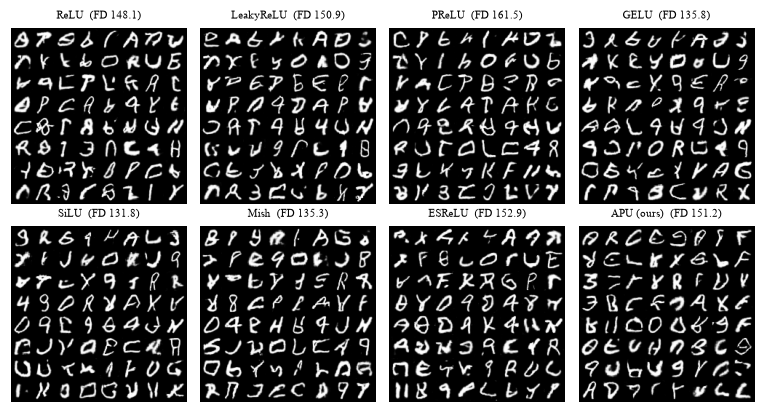

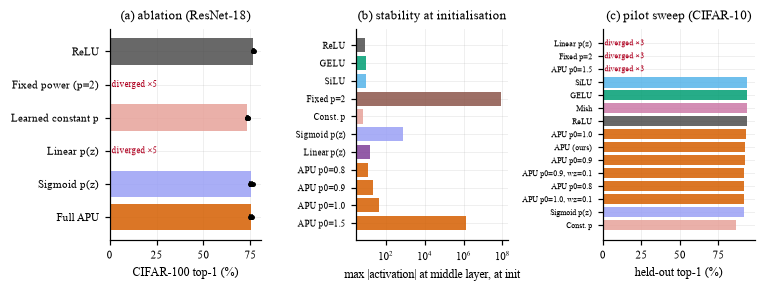

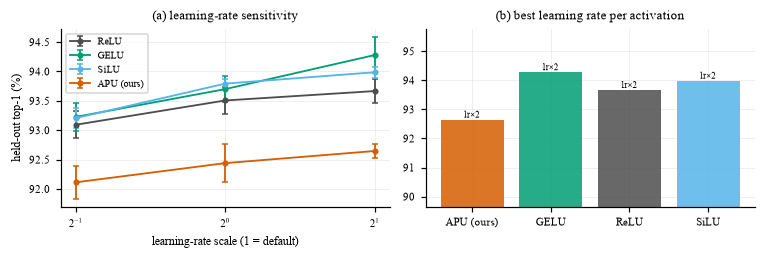

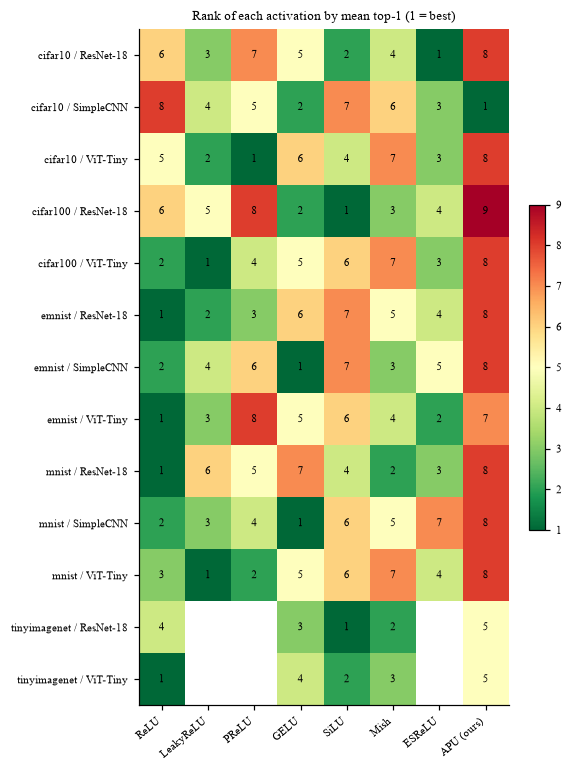

In [49]:
# ===== 15. Paper figures: built only from logged results, consistent style, PDF + PNG =====
import matplotlib as mpl

ACT_COLOR = dict(relu="#4D4D4D", leakyrelu="#9A9A9A", prelu="#0072B2", gelu="#009E73", silu="#56B4E9", mish="#CC79A7", esrelu="#E69F00", apu="#D55E00",
                 apu_fixed="#8C564B", apu_const="#E7A29A", apu_linear="#7F3F98", apu_sigmoid="#9AA0F5")
ACT_NAME = dict(relu="ReLU", leakyrelu="LeakyReLU", prelu="PReLU", gelu="GELU", silu="SiLU", mish="Mish", esrelu="ESReLU", apu="APU (ours)",
                apu_fixed="Fixed p=2", apu_const="Const. p", apu_linear="Linear p(z)", apu_sigmoid="Sigmoid p(z)")
def act_color(a): return ACT_COLOR.get(a.split("@")[0], "#D55E00")
def act_name(a):
    b, p0, ex = parse_act(a)
    return ACT_NAME.get(b, b) if (p0 is None and not ex) or b != "apu" else f"APU p0={p0}" + (f", wz={ex['wz']}" if "wz" in ex else "")
W1, W2 = 3.4, 7.0           # single / double column width (inches)

def paper_style():
    mpl.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
                         "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5, "lines.linewidth": 1.2, "figure.dpi": 110, "savefig.dpi": 300,
                         "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.bbox": "tight", "axes.axisbelow": True})
paper_style()

def _save(fig, name):
    fig.savefig(ROOT / "figures" / f"{name}.png"); fig.savefig(ROOT / "figures" / f"{name}.pdf"); plt.show(); plt.close(fig)

def _panel(ax, s): ax.text(-0.24, 1.10, s, transform=ax.transAxes, fontweight="bold", fontsize=9)

def _combos(d, order=("imagenet", "tinyimagenet", "cifar100", "cifar10", "emnist", "mnist")):
    out = []
    for ds in order:
        for ar in sorted(d[d.dataset == ds].arch.unique()): out.append((ds, ar))
    return out

def _results(non_holdout=True, drop_diverged=True):
    df = load_results()
    if df.empty: return df
    if non_holdout: df = df[~df.holdout]
    return df[~df.diverged] if drop_diverged else df

# ---------------- Figure 1: motivation, learned shapes, mechanism ----------------
def fig1_motivation(dataset="cifar10", arch="resnet18"):
    fig, ax = plt.subplots(1, 3, figsize=(W2, 2.3), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
    rows = runs_for(dataset, arch, "relu")
    if rows:
        rid, seed = rows[0]; model = load_ckpt_model(rid, dataset, arch, "relu"); store = {}
        hs = [m.register_forward_pre_hook((lambda nme: lambda m, i: store.setdefault(nme, []).append(i[0].detach().flatten()[:20000].cpu()))(n)) for n, m in act_modules(model)]
        _, vl = get_loaders(dataset, seed, 128)
        with torch.no_grad():
            for i, (x, _) in enumerate(vl):
                model(x.to(device))
                if i >= 1: break
        [h.remove() for h in hs]; names = list(store)
        for idx, c, lab in zip([0, len(names) // 2, len(names) - 1], ["#0072B2", "#E69F00", "#D55E00"], ["shallow", "middle", "deep"]):
            v = torch.cat(store[names[idx]]).numpy(); h, e = np.histogram(v, bins=100, range=(-4, 4), density=True)
            ax[0].plot((e[1:] + e[:-1]) / 2, h, c=c, label=lab)
        ax[0].set_xlabel("pre-activation z"); ax[0].set_ylabel("density"); ax[0].legend(); ax[0].set_title("(a) feature statistics differ by depth")
    else: ax[0].text(.5, .5, "needs a trained ReLU run", ha="center"); ax[0].axis("off")
    res = analyze_exponents(dataset, arch) if runs_for(dataset, arch, "apu") else {}
    if res:
        s0 = sorted(res)[0]; names = list(res[s0]); n = len(names); zz = np.linspace(-6, 6, 200)
        ax[1].plot(zz, zz, ":", c="k", lw=.8, label="identity"); ax[1].plot(zz, np.maximum(zz, 0), "--", c="#4D4D4D", lw=.8, label="ReLU")
        for idx, c, lab in zip([0, n // 2, n - 1], ["#0072B2", "#E69F00", "#D55E00"], ["shallow", "middle", "deep"]):
            z_, y_, _, _ = learned_curve(res[s0][names[idx]]); ax[1].plot(z_, y_, c=c, label=f"APU {lab}")
        ax[1].set_xlabel("z"); ax[1].set_ylabel("f(z)"); ax[1].legend(); ax[1].set_title("(b) learned APU shapes")
    else: ax[1].text(.5, .5, "needs a trained APU run", ha="center"); ax[1].axis("off")
    from matplotlib.patches import FancyBboxPatch
    ax[2].axis("off"); ax[2].set_title("(c) APU computation"); ax[2].set_xlim(0, 10.6); ax[2].set_ylim(0, 6); ax[2].grid(False)
    def box(x, y, w, h, txt, fc="#FFF2E8"):
        ax[2].add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=fc, ec="#D55E00", lw=.8)); ax[2].text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=5.6)
    box(0.0, 2.3, 1.4, 1.3, "input\nz", "#EEF3FA"); box(2.0, 3.7, 6.2, 1.6, "exponent estimator\np(z) = p0 + A·tanh(w_z·z + b_z)"); box(2.0, 0.5, 6.2, 1.6, "power transform\nf(z) = z·(z²+ε)^((p(z)−1)/2)"); box(8.8, 2.3, 1.2, 1.3, "output\nf(z)", "#EEF3FA")
    for xy, xyt in [((1.95, 4.5), (1.5, 3.4)), ((1.95, 1.3), (1.5, 2.5)), ((5.1, 2.2), (5.1, 3.65)), ((8.75, 2.95), (8.25, 1.5))]:
        ax[2].annotate("", xy=xy, xytext=xyt, arrowprops=dict(arrowstyle="->", lw=.8, color="#444"))
    ax[2].text(0.0, 0.0, "A = a_max·tanh(raw_A): p stays in [p0−a_max, p0+a_max]", fontsize=5.3, va="bottom")
    plt.tight_layout(); _save(fig, "fig1_motivation")

# ---------------- Figure 3: recognition accuracy + convergence, and gap to ReLU ----------------
def fig3_recognition(dataset):
    """One figure per dataset: a row per model with final accuracy (left) and convergence curves (right)."""
    d = _results(); d = d[d.dataset == dataset] if len(d) else d
    if d.empty: print("no results for", dataset); return
    combos = _combos(d); n = len(combos)
    fig, ax = plt.subplots(n, 2, figsize=(W2, 2.05 * n), squeeze=False, gridspec_kw=dict(width_ratios=[1, 1.15]))
    for r, (ds, ar) in enumerate(combos):
        dd = d[(d.dataset == ds) & (d.arch == ar)]; acts = [a for a in ACT_ORDER if a in set(dd.act)]
        a0 = ax[r, 0]
        for i, a in enumerate(acts):
            v = dd[dd.act == a].top1.values; m, lo, hi = mean_ci(v)
            a0.bar(i, m, color=act_color(a), alpha=.85, width=.72)
            if np.isfinite(lo): a0.errorbar(i, m, yerr=[[m - lo], [hi - m]], color="k", capsize=2, lw=.8)
            a0.scatter(i + (np.linspace(-.2, .2, len(v)) if len(v) > 1 else 0), v, s=5, color="k", zorder=3)
        ms = [dd[dd.act == a].top1.mean() for a in acts]; spread = max(np.nanmax(ms) - np.nanmin(ms), 0.5)
        a0.set_ylim(max(np.nanmin(ms) - 2.5 * spread, 0), np.nanmax(ms) + 1.2 * spread)
        a0.set_xticks(range(len(acts))); a0.set_xticklabels([act_name(a) for a in acts], rotation=40, ha="right"); a0.set_ylabel("top-1 (%)")
        a0.set_title(f"{ds} / {arch_label(ar)}  (n = {int(dd.groupby('act').seed.nunique().min())}-{int(dd.groupby('act').seed.nunique().max())} seeds)"); _panel(a0, "abcdefghij"[r] if r < 10 else "")
        a1 = ax[r, 1]
        for a in acts:
            H = [[h["val_top1"] for h in x.history] for x in dd[dd.act == a].itertuples()]; L = min(map(len, H)); H = np.array([h[:L] for h in H]); e = np.arange(1, L + 1)
            a1.plot(e, H.mean(0), color=act_color(a), lw=1.8 if a == "apu" else 1.0, label=act_name(a)); a1.fill_between(e, H.mean(0) - H.std(0), H.mean(0) + H.std(0), color=act_color(a), alpha=.12)
        a1.set_xlabel("epoch"); a1.set_ylabel("val top-1 (%)")
        if L >= 20:                                              # zoom on the end of training
            ins = a1.inset_axes([0.42, 0.10, 0.54, 0.42]); k0 = int(L * 0.75)
            for a in acts:
                H = np.array([[h["val_top1"] for h in x.history][:L] for x in dd[dd.act == a].itertuples()]); ins.plot(np.arange(1, L + 1)[k0:], H.mean(0)[k0:], color=act_color(a), lw=1.8 if a == "apu" else 1.0)
            ins.tick_params(labelsize=5); ins.grid(alpha=.2)
        if r == 0: a1.legend(ncol=2, loc="lower right" if L < 20 else "upper left", fontsize=5.5)
    plt.tight_layout(); _save(fig, f"fig3_recognition_{dataset}")

def arch_label(a): return dict(resnet18="ResNet-18", resnet50="ResNet-50", vit_tiny="ViT-Tiny", vit_small="ViT-Small", simplecnn="SimpleCNN", vit_micro="ViT-Micro").get(a, a)

def fig3b_gap_to_relu():
    d = _results(); d = d[d.dataset.isin(["imagenet", "tinyimagenet", "cifar100", "cifar10"])] if len(d) else d
    if d.empty: print("no results"); return
    combos = [c for c in _combos(d) if (d[(d.dataset == c[0]) & (d.arch == c[1])].act == "relu").any()]; n = len(combos)
    fig, ax = plt.subplots(1, n, figsize=(W2, 2.5), sharey=True, squeeze=False); ax = ax[0]
    acts = [a for a in ACT_ORDER if a != "relu"]
    for k, (ds, ar) in enumerate(combos):
        dd = d[(d.dataset == ds) & (d.arch == ar)]; ref = dd[dd.act == "relu"].top1.values
        for i, a in enumerate(acts):
            v = dd[dd.act == a].top1.values
            if len(v) == 0: continue
            dif, lo, hi, p = welch_diff(v, ref)
            ax[k].errorbar(dif, i, xerr=[[dif - lo], [hi - dif]] if np.isfinite(lo) else None, fmt="o", color=act_color(a), capsize=2, ms=4)
        ax[k].axvline(0, c="k", lw=.8); ax[k].set_yticks(range(len(acts))); ax[k].set_yticklabels([act_name(a) for a in acts]); ax[k].set_title(f"{ds}\n{arch_label(ar)}", fontsize=7)
        ax[k].set_xlabel("Δ top-1 vs ReLU (pts)"); ax[k].invert_yaxis()
    fig.suptitle("Difference to ReLU (mean, 95% Welch CI; right of 0 = better than ReLU)", fontsize=8, y=1.02)
    plt.tight_layout(); _save(fig, "fig3b_gap_to_relu")

# ---------------- Figure 4: optimisation, robustness, efficiency ----------------
def fig4a_optimization(dataset="cifar10", arch="resnet18", acts=("relu", "gelu", "silu", "apu")):
    d = _results(drop_diverged=True); d = d[(d.dataset == dataset) & (d.arch == arch)]
    if d.empty: print("no runs for", dataset, arch); return
    fig, ax = plt.subplots(2, 2, figsize=(W2, 4.6))
    for a in acts:
        da = d[d.act == a]
        if da.empty: continue
        for k, (key, axx) in enumerate([("train_loss", ax[0, 0]), ("grad_norm_mean", ax[0, 1])]):
            H = np.array([[h[key] for h in r.history] for r in da.itertuples()]); e = np.arange(1, H.shape[1] + 1)
            axx.plot(e, H.mean(0), color=act_color(a), label=act_name(a)); axx.fill_between(e, H.mean(0) - H.std(0), H.mean(0) + H.std(0), color=act_color(a), alpha=.15)
    ax[0, 0].set_yscale("log"); ax[0, 0].set_ylabel("training loss"); ax[0, 0].set_xlabel("epoch"); ax[0, 0].legend(); _panel(ax[0, 0], "a")
    ax[0, 1].set_yscale("log"); ax[0, 1].set_ylabel("global gradient norm"); ax[0, 1].set_xlabel("epoch"); _panel(ax[0, 1], "b")
    ct = convergence_table()
    if ct is not None:
        c = ct[(ct.dataset == dataset) & (ct.arch == arch)]; c = c[c.act.isin(ACT_ORDER)].set_index("act").reindex([a for a in ACT_ORDER if a in set(c.act)])
        ax[1, 0].bar(range(len(c)), c.epochs_to_target.fillna(0), color=[act_color(a) for a in c.index], alpha=.85)
        for i, (a, r) in enumerate(c.iterrows()):
            if r.reached < r.n: ax[1, 0].text(i, 0.3, f"{int(r.reached)}/{int(r.n)}\nreached", ha="center", fontsize=5)
        ax[1, 0].set_xticks(range(len(c))); ax[1, 0].set_xticklabels([act_name(a) for a in c.index], rotation=40, ha="right")
        ax[1, 0].set_ylabel("epochs to 95% of ReLU final acc."); _panel(ax[1, 0], "c")
    for a, ls in [("relu", "-"), ("apu", "-")]:
        for final, alpha in [(False, .45), (True, 1.0)]:
            prof = safe(layerwise_grad_profile, dataset, arch, a, final=final)
            if prof: ax[1, 1].plot(prof, color=act_color(a), alpha=alpha, ls="--" if not final else "-", label=f"{act_name(a)} {'final' if final else 'init'}")
    ax[1, 1].set_yscale("log"); ax[1, 1].set_xlabel("layer (depth)"); ax[1, 1].set_ylabel("weight-gradient norm"); ax[1, 1].legend(fontsize=5.5); _panel(ax[1, 1], "d")
    plt.tight_layout(); _save(fig, f"fig4a_optimization_{dataset}_{arch}")

def fig4b_robust_efficiency(dataset="cifar10", arch="resnet18"):
    fig, ax = plt.subplots(2, 3, figsize=(W2, 4.6))
    rob = load_robust(dataset, arch)
    if len(rob):
        piv = rob.groupby(["act", "corruption"]).acc.mean().unstack("corruption"); piv = piv.reindex([a for a in ACT_ORDER if a in piv.index])
        im = ax[0, 0].imshow(piv.values, aspect="auto", cmap="viridis"); ax[0, 0].set_xticks(range(piv.shape[1])); ax[0, 0].set_xticklabels([c.replace("_", " ") for c in piv.columns], rotation=60, ha="right", fontsize=5.5)
        ax[0, 0].set_yticks(range(piv.shape[0])); ax[0, 0].set_yticklabels([act_name(a) for a in piv.index]); ax[0, 0].grid(False); plt.colorbar(im, ax=ax[0, 0], fraction=.046)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]): ax[0, 0].text(j, i, f"{piv.values[i, j]:.0f}", ha="center", va="center", color="w", fontsize=5)
        ax[0, 0].set_title("accuracy under corruption (%)", fontsize=7); _panel(ax[0, 0], "a")
        sev = rob.groupby(["act", "severity"]).acc.mean().unstack("act")
        for a in ACT_ORDER:
            if a in sev: ax[0, 1].plot(sev.index, sev[a], marker="o", ms=2.5, color=act_color(a), lw=1.8 if a == "apu" else 1.0, label=act_name(a))
        ax[0, 1].set_xlabel("severity"); ax[0, 1].set_ylabel("mean accuracy (%)"); ax[0, 1].legend(fontsize=5, ncol=2); _panel(ax[0, 1], "b")
        if rob.source.iloc[0] != "official": ax[0, 1].text(.02, .02, "re-implemented corruption subset", transform=ax[0, 1].transAxes, fontsize=5, color="#888")
    pg = ROOT / "robust" / f"pgd_{dataset}_{arch}.csv"
    if pg.exists():
        t = pd.read_csv(pg).groupby(["act", "eps"]).acc.agg(["mean", "std"]).reset_index()
        for a in ACT_ORDER:
            ta = t[t.act == a]
            if len(ta): ax[0, 2].errorbar(ta.eps, ta["mean"], yerr=ta["std"].fillna(0), marker="o", ms=2.5, color=act_color(a), capsize=1.5, label=act_name(a))
        ax[0, 2].set_xlabel("PGD-10 ε (/255)"); ax[0, 2].set_ylabel("accuracy (%)"); ax[0, 2].legend(fontsize=5); _panel(ax[0, 2], "c")
        ax[0, 2].set_title("PGD-10 (should reach ~0)", fontsize=7)
    tf = ROOT / "tables" / f"table4_efficiency_{dataset}_{arch}.csv"
    if tf.exists():
        t = pd.read_csv(tf).set_index("act"); show = [a for a in ["gelu", "silu", "mish", "apu"] if a in t.index]
        mets = [("train_step_ms_overhead_%", "step eager"), ("train_step_compiled_ms_overhead_%", "step compiled"), ("latency_bs_ms_overhead_%", "latency fp32"), ("latency_bs_amp_ms_overhead_%", "latency AMP"),
                ("peak_mem_mb_overhead_%", "memory eager"), ("peak_mem_compiled_mb_overhead_%", "memory compiled")]
        mets = [(m, n) for m, n in mets if m in t.columns]
        w = 0.8 / len(show)
        for k, a in enumerate(show):
            ax[1, 0].bar(np.arange(len(mets)) + k * w, [t.loc[a, m] if np.isfinite(t.loc[a, m]) else 0 for m, _ in mets], w, color=act_color(a), label=act_name(a))
        ax[1, 0].set_xticks(np.arange(len(mets)) + 0.4 - w / 2); ax[1, 0].set_xticklabels([n for _, n in mets], rotation=45, ha="right", fontsize=5.5); ax[1, 0].axhline(0, c="k", lw=.6)
        ax[1, 0].set_ylabel("overhead vs ReLU (%)"); ax[1, 0].set_ylim(top=ax[1, 0].get_ylim()[1] * 1.35); ax[1, 0].legend(fontsize=5.5, ncol=2, loc="upper left"); _panel(ax[1, 0], "d")
        acc = _results(); acc = acc[(acc.dataset == dataset) & (acc.arch == arch)].groupby("act").top1.mean()
        xcol = "epoch_time_s" if "epoch_time_s" in t.columns and t.epoch_time_s.notna().any() else "train_step_ms"        # measured time per epoch is the same setting for every activation
        for a in ACT_ORDER:
            if a in t.index and a in acc.index:
                ax[1, 1].scatter(t.loc[a, xcol], acc[a], color=act_color(a), s=18); ax[1, 1].annotate(act_name(a), (t.loc[a, xcol], acc[a]), fontsize=5.5, xytext=(3, 3), textcoords="offset points")
        ax[1, 1].set_xlabel("measured s / epoch" if xcol == "epoch_time_s" else "train-step time (ms)"); ax[1, 1].set_ylabel("top-1 (%)"); ax[1, 1].set_title("accuracy vs cost", fontsize=7); _panel(ax[1, 1], "e")
        if "epoch_time_s" in t:
            e = t.reindex([a for a in ACT_ORDER if a in t.index]); ax[1, 2].bar(range(len(e)), e.epoch_time_s, color=[act_color(a) for a in e.index], alpha=.85)
            ax[1, 2].set_xticks(range(len(e))); ax[1, 2].set_xticklabels([act_name(a) for a in e.index], rotation=40, ha="right"); ax[1, 2].set_ylabel("measured s / epoch"); _panel(ax[1, 2], "f")
    plt.tight_layout(); _save(fig, f"fig4b_robust_efficiency_{dataset}_{arch}")

# ---------------- Figure 5: GAN ----------------
def fig5_gan(dataset=None, arch=None):
    g = load_results("gan")
    if g.empty: print("no GAN results"); return
    dataset = dataset or g.dataset.iloc[0]; arch = arch or g.arch.iloc[0]; g = g[(g.dataset == dataset) & (g.arch == arch)]
    if g.empty: print(f"no GAN results for {dataset}/{arch}"); return
    acts = [a for a in ACT_ORDER if a in set(g.act)]; fig, ax = plt.subplots(2, 3, figsize=(W2, 4.2))
    for met, a_, ttl in [("d_loss", ax[0, 0], "discriminator loss"), ("g_loss", ax[0, 1], "generator loss")]:
        for a in acts:
            H = np.array([[h[met] for h in r.history] for r in g[g.act == a].itertuples()]); e = np.arange(1, H.shape[1] + 1)
            a_.plot(e, H.mean(0), color=act_color(a), lw=1.8 if a == "apu" else 1.0, label=act_name(a)); a_.fill_between(e, H.mean(0) - H.std(0), H.mean(0) + H.std(0), color=act_color(a), alpha=.12)
        a_.set_title(ttl); a_.set_xlabel("epoch")
    ax[0, 0].legend(fontsize=5, ncol=2); _panel(ax[0, 0], "a"); _panel(ax[0, 1], "b")
    for a in acts:
        for key, ls in [("real_score", "-"), ("fake_score", "--")]:
            H = np.array([[h[key] for h in r.history] for r in g[g.act == a].itertuples()]); ax[0, 2].plot(np.arange(1, H.shape[1] + 1), H.mean(0), ls=ls, color=act_color(a), lw=1.0)
    ax[0, 2].set_title("D(real) solid, D(fake) dashed"); ax[0, 2].set_xlabel("epoch"); _panel(ax[0, 2], "c")
    for k, (met, ttl) in enumerate([("fd", "Fréchet distance (lower is better)"), ("is_like", "inception-like score (higher is better)")]):
        s = g.groupby("act")[met].agg(["mean", "std"]).reindex(acts)
        ax[1, k].bar(range(len(acts)), s["mean"], yerr=s["std"].fillna(0), color=[act_color(a) for a in acts], capsize=2, alpha=.9)
        for i, a in enumerate(acts):
            v = g[g.act == a][met].values; ax[1, k].scatter(np.full(len(v), i), v, s=5, color="k", zorder=3)
        ax[1, k].set_xticks(range(len(acts))); ax[1, k].set_xticklabels([act_name(a) for a in acts], rotation=40, ha="right"); ax[1, k].set_title(ttl, fontsize=7); _panel(ax[1, k], "de"[k])
    ax[1, 2].axis("off"); ax[1, 2].text(0, .5, "Metrics use features of a classifier\ntrained on the real data (no Inception\ndownload). They rank generators of the same\ndataset; they are not comparable with\nstandard FID numbers.", fontsize=6, va="center")
    plt.tight_layout(); _save(fig, f"fig5_gan_{dataset}_{arch}")
    acts_s = acts; ncol = min(4, len(acts_s)); nrow = -(-len(acts_s) // ncol)
    fig, axs = plt.subplots(nrow, ncol, figsize=(W2, 1.9 * nrow), squeeze=False)
    for a_ in axs.ravel(): a_.axis("off")
    for a_, a in zip(axs.ravel(), acts_s):
        r = g[g.act == a].sort_values("seed").iloc[0]; p = ROOT / "samples" / f"{r.run_id}-ep{r.epochs}.png"
        if p.exists(): a_.imshow(plt.imread(p))
        a_.set_title(f"{act_name(a)}  (FD {r.fd:.1f})" if np.isfinite(r.fd) else act_name(a), fontsize=7)
    plt.tight_layout(); _save(fig, f"fig5b_gan_samples_{dataset}_{arch}")

# ---------------- Figure 6: ablation + stability at initialisation + pilot sweep ----------------
def fig6_ablation_stability():
    d = _results(drop_diverged=False); fig, ax = plt.subplots(1, 3, figsize=(W2, 2.7))
    dd = d[(d.dataset == "cifar100") & (d.arch == "resnet18") & (d.act.isin(ABLATION))] if len(d) else d
    if len(dd):
        for i, a in enumerate(ABLATION):
            da = dd[dd.act == a]
            if da.empty: continue
            ok = da[~da.diverged].top1.values; nd = int(da.diverged.sum())
            if len(ok):
                m, lo, hi = mean_ci(ok); ax[0].barh(i, m, color=act_color(a), alpha=.85)
                if np.isfinite(lo): ax[0].errorbar(m, i, xerr=[[m - lo], [hi - m]], color="k", capsize=2, lw=.8)
                ax[0].scatter(ok, np.full(len(ok), i), s=5, color="k", zorder=3)
            if nd: ax[0].text(1, i, f"diverged ×{nd}", va="center", fontsize=6, color="#B00020")
        ax[0].set_yticks(range(len(ABLATION))); ax[0].set_yticklabels([ABL_NAME[a] for a in ABLATION]); ax[0].invert_yaxis(); ax[0].set_xlabel("CIFAR-100 top-1 (%)"); ax[0].set_title("(a) ablation (ResNet-18)")
    gf = ROOT / "tables" / "growth_at_init_cifar10_resnet18.csv"
    if gf.exists():
        t = pd.read_csv(gf); ax[1].barh(range(len(t)), t.middle_layer, color=[act_color(a) for a in t.activation], alpha=.85)
        ax[1].set_xscale("log"); ax[1].set_yticks(range(len(t))); ax[1].set_yticklabels([act_name(a) for a in t.activation], fontsize=6); ax[1].invert_yaxis()
        ax[1].set_xlabel("max |activation| at middle layer, at init"); ax[1].set_title("(b) stability at initialisation")
    pt = pilot_table()
    if pt is not None:
        pt = pt.sort_values("top1_mean"); ax[2].barh(range(len(pt)), pt.top1_mean.fillna(0), color=[act_color(a) for a in pt.act], alpha=.85)
        for i, r in enumerate(pt.itertuples()):
            if r.diverged: ax[2].text(1, i, f"diverged ×{int(r.diverged)}", va="center", fontsize=5.5, color="#B00020")
        ax[2].set_yticks(range(len(pt))); ax[2].set_yticklabels([act_name(a) for a in pt.act], fontsize=5.5); ax[2].set_xlabel("held-out top-1 (%)"); ax[2].set_title("(c) pilot sweep (CIFAR-10)")
    plt.tight_layout(); _save(fig, "fig6_ablation_stability")

def fig7_lr_sweep():
    r = lr_sweep_table()
    if r is None: print("no lr sweep results"); return
    t, best = r; fig, ax = plt.subplots(1, 2, figsize=(W2, 2.4))
    for a in LRSWEEP_ACTS:
        ta = t[t.act == a]
        if len(ta): ax[0].errorbar(ta.lr_scale, ta["mean"], yerr=ta["std"].fillna(0), marker="o", ms=3, capsize=2, color=act_color(a), label=act_name(a))
    ax[0].set_xscale("log", base=2); ax[0].set_xlabel("learning-rate scale (1 = default)"); ax[0].set_ylabel("held-out top-1 (%)"); ax[0].legend(); ax[0].set_title("(a) learning-rate sensitivity")
    b = best.set_index("act"); ax[1].bar(range(len(b)), b.best_top1, color=[act_color(a) for a in b.index], alpha=.85)
    for i, (a, rr) in enumerate(b.iterrows()): ax[1].text(i, rr.best_top1, f"lr×{rr.best_lr_scale:g}", ha="center", va="bottom", fontsize=6)
    ax[1].set_xticks(range(len(b))); ax[1].set_xticklabels([act_name(a) for a in b.index]); ax[1].set_ylim(b.best_top1.min() - 3, b.best_top1.max() + 1.5); ax[1].set_title("(b) best learning rate per activation")
    plt.tight_layout(); _save(fig, "fig7_lr_sweep")

# ---------------- Figure 8: how the APU parameters evolve ----------------
def fig8_parameter_dynamics(dataset="cifar10", arch="resnet18"):
    df = _results(); d = df[(df.dataset == dataset) & (df.arch == arch) & (df.act == "apu")] if len(df) else df
    if d.empty: print("no APU runs for", dataset, arch); return
    r = d.sort_values("seed").iloc[0]; h = r.history
    if not h or h[0].get("apu") is None: print("no APU logs"); return
    layers = list(h[0]["apu"]); E = len(h); L = len(layers)
    pm = np.array([[e["apu"][l]["p_mean"] for l in layers] for e in h]).T; ps = np.array([[e["apu"][l]["p_std"] for l in layers] for e in h]).T
    par = lambda k: np.array([[e["apu"][l]["params"].get(k, np.nan) for l in layers] for e in h]).T
    A = APU_DEFAULT["a_max"] * np.tanh(par("raw_A")); wz = par("w_z"); bz = par("b_z"); cm = plt.cm.viridis(np.linspace(0, 1, L)); ep = np.arange(1, E + 1)
    fig, ax = plt.subplots(2, 3, figsize=(W2, 4.4))
    for a_, M, ttl in [(ax[0, 0], pm, "(a) layer-mean exponent p"), (ax[0, 1], ps, "(b) std of p(z) within layer")]:
        im = a_.imshow(M, aspect="auto", cmap="magma", extent=[0.5, E + .5, L - .5, -.5]); a_.set_xlabel("epoch"); a_.set_ylabel("layer"); a_.set_title(ttl, fontsize=7); a_.grid(False); plt.colorbar(im, ax=a_, fraction=.046)
    for a_, M, ttl in [(ax[0, 2], A, "(c) amplitude A"), (ax[1, 0], wz, "(d) input gain w_z"), (ax[1, 1], bz, "(e) bias b_z")]:
        for i in range(L): a_.plot(ep, M[i], color=cm[i], lw=.9)
        a_.set_xlabel("epoch"); a_.set_title(ttl, fontsize=7)
    sm = plt.cm.ScalarMappable(cmap="viridis"); sm.set_array([0, 1]); cb = plt.colorbar(sm, ax=ax[1, 1], fraction=.046); cb.set_label("depth", fontsize=6)
    allp = d.sort_values("seed"); fin = np.array([[x.history[-1]["apu"][l]["p_mean"] for l in layers] for x in allp.itertuples() if x.history and x.history[-1].get("apu")])
    ax[1, 2].errorbar(range(L), fin.mean(0), yerr=fin.std(0) if len(fin) > 1 else None, marker="o", ms=3, color=act_color("apu"), capsize=2); ax[1, 2].axhline(APU_DEFAULT["p0"], ls="--", c="gray", lw=.8)
    ax[1, 2].set_xlabel("layer"); ax[1, 2].set_ylabel("final p"); ax[1, 2].set_title(f"(f) final p per layer (n={len(fin)} seeds)", fontsize=7)
    plt.tight_layout(); _save(fig, f"fig8_parameter_dynamics_{dataset}_{arch}")

# ---------------- Figure 9: ranks across all settings ----------------
def fig9_rank_heatmap():
    r = rank_table()
    if r is None or r.empty: print("no ranks"); return
    fig, ax = plt.subplots(figsize=(W2 * .75, 0.45 * len(r) + 1.2)); im = ax.imshow(r.values, cmap="RdYlGn_r", aspect="auto", vmin=1, vmax=max(r.values[np.isfinite(r.values)].max(), 2))
    ax.set_xticks(range(r.shape[1])); ax.set_xticklabels([act_name(a) for a in r.columns], rotation=40, ha="right"); ax.set_yticks(range(len(r))); ax.set_yticklabels([f"{a} / {arch_label(b)}" for a, b in r.index]); ax.grid(False)
    for i in range(r.shape[0]):
        for j in range(r.shape[1]): ax.text(j, i, "" if np.isnan(r.values[i, j]) else f"{int(r.values[i, j])}", ha="center", va="center", fontsize=7)
    ax.set_title("Rank of each activation by mean top-1 (1 = best)"); plt.colorbar(im, ax=ax, fraction=.04); plt.tight_layout(); _save(fig, "fig9_rank_heatmap")

# ---------------- Figure 10: learned activation shapes by depth, with seed/layer spread ----------------
def fig10_learned_shapes(dataset="cifar10", arch="resnet18"):
    res = analyze_exponents(dataset, arch)
    if not res: print("no APU checkpoints"); return
    zs = np.linspace(-6, 6, 1000); zt = torch.tensor(zs, dtype=torch.float32); base = dict(relu=F.relu(zt).numpy(), gelu=F.gelu(zt).numpy(), silu=F.silu(zt).numpy())
    fig, ax = plt.subplots(2, 3, figsize=(W2, 4.2))
    for col, grp in enumerate(["shallow", "middle", "deep"]):
        Y, G = [], []
        for s in sorted(res):
            names = list(res[s])
            for i, nme in enumerate(names):
                if depth_group(i, len(names)) == grp: _, y_, g_, _ = learned_curve(res[s][nme]); Y.append(y_); G.append(g_)
        if not Y: continue
        Y, G = np.array(Y), np.array(G); z_ = np.linspace(-6, 6, Y.shape[1])
        ax[0, col].plot(z_, Y.mean(0), color=act_color("apu"), label="APU (mean)"); ax[0, col].fill_between(z_, Y.mean(0) - Y.std(0), Y.mean(0) + Y.std(0), color=act_color("apu"), alpha=.25, label="± std (layers, seeds)")
        for k, c in [("relu", "#4D4D4D"), ("gelu", "#009E73"), ("silu", "#56B4E9")]: ax[0, col].plot(zs, base[k], "--", c=c, lw=.8, label=act_name(k))
        ax[0, col].plot(zs, zs, ":", c="k", lw=.7); ax[0, col].set_title(f"{grp} layers: f(z)", fontsize=7); ax[0, col].set_xlabel("z"); ax[0, col].set_ylim(-3, 6)
        ax[1, col].plot(z_, G.mean(0), color=act_color("apu")); ax[1, col].fill_between(z_, G.mean(0) - G.std(0), G.mean(0) + G.std(0), color=act_color("apu"), alpha=.25)
        ax[1, col].set_title(f"{grp} layers: f'(z)", fontsize=7); ax[1, col].set_xlabel("z"); ax[1, col].set_ylim(-0.5, 3)
    ax[0, 0].legend(fontsize=5); plt.tight_layout(); _save(fig, f"fig10_learned_shapes_{dataset}_{arch}")

if analysis_on():
    safe(fig1_motivation)
    for _d in ["imagenet", "tinyimagenet", "cifar100", "cifar10", "emnist", "mnist"]: safe(fig3_recognition, _d)      # first four: main paper; emnist / mnist: supplementary
    safe(fig3b_gap_to_relu)
    for _ds, _ar in P["main_grid"][:3]:
        if runs_for(_ds, _ar, "apu"):
            safe(fig4a_optimization, _ds, _ar); safe(fig8_parameter_dynamics, _ds, _ar); safe(fig10_learned_shapes, _ds, _ar)
    for _ds, _ar in P["robust_grid"]: safe(fig4b_robust_efficiency, _ds, _ar)
    for _gd in P["gan_datasets"]:
        for _ga in P["gan_archs"]: safe(fig5_gan, _gd, _ga)
    safe(fig6_ablation_stability); safe(fig7_lr_sweep); safe(fig9_rank_heatmap)
else:
    print("figures skipped (add 'analysis' to APU_STAGES)")


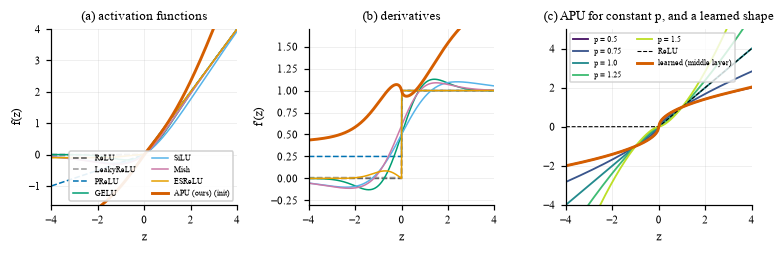

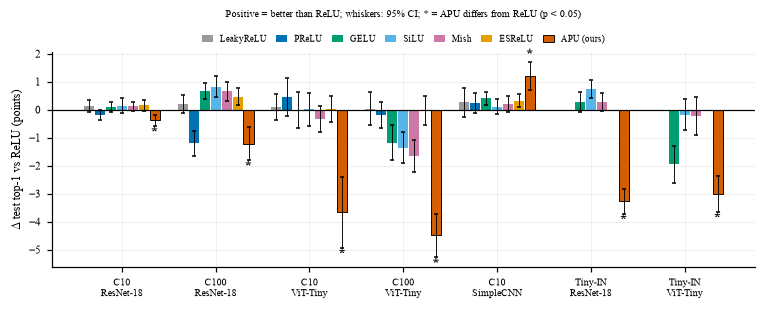

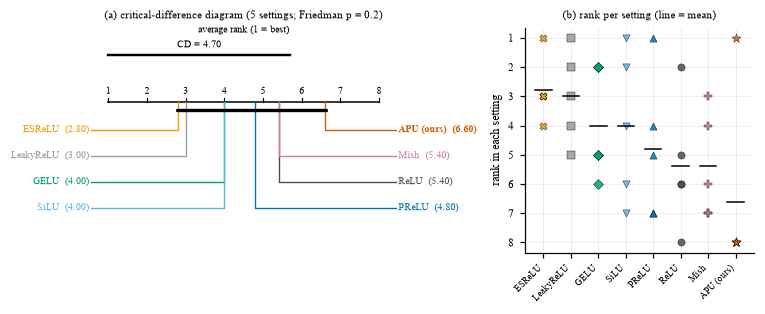

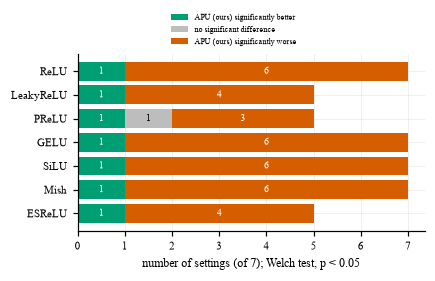

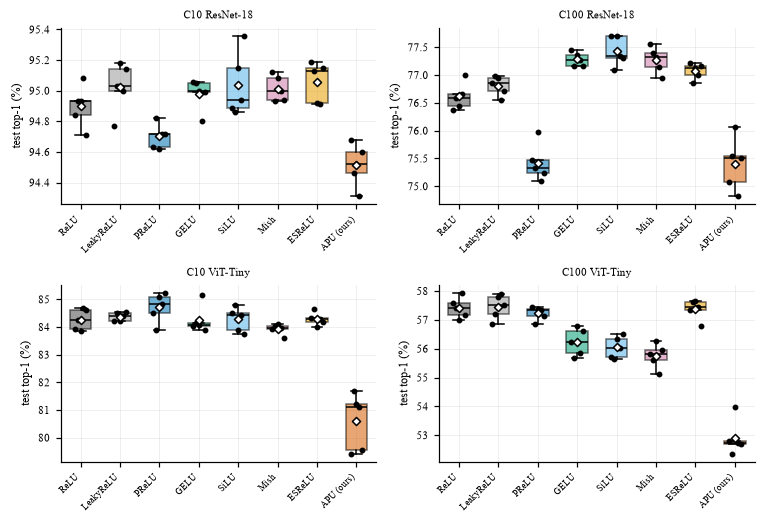

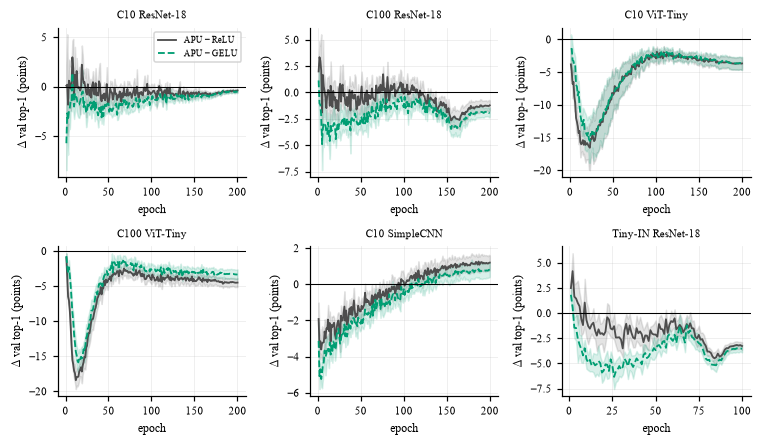

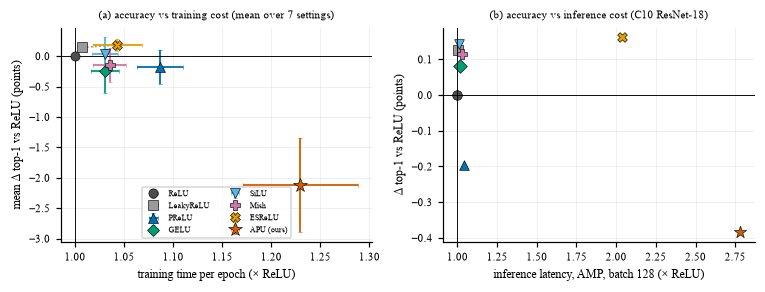

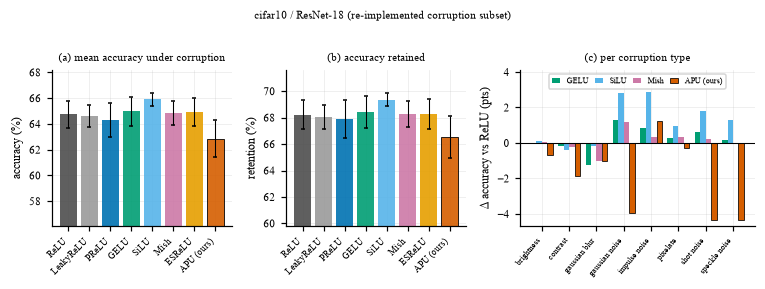

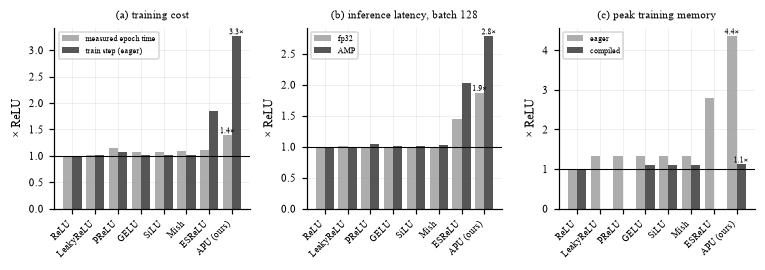

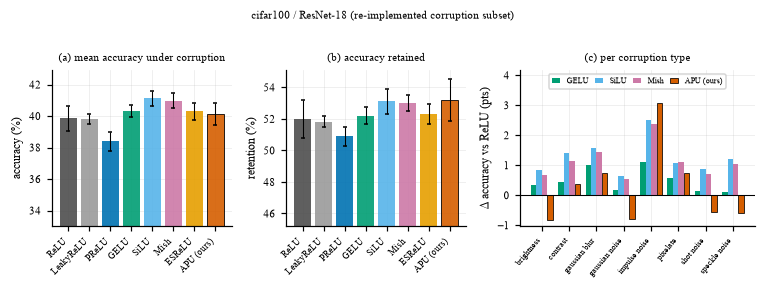

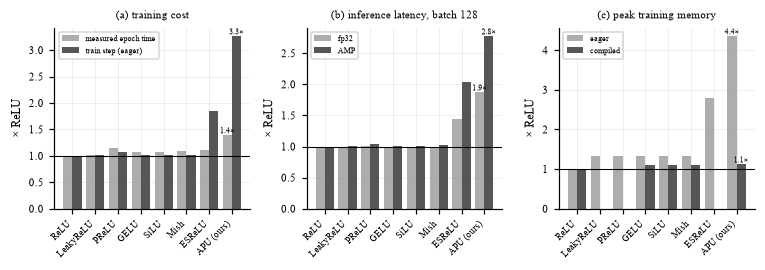

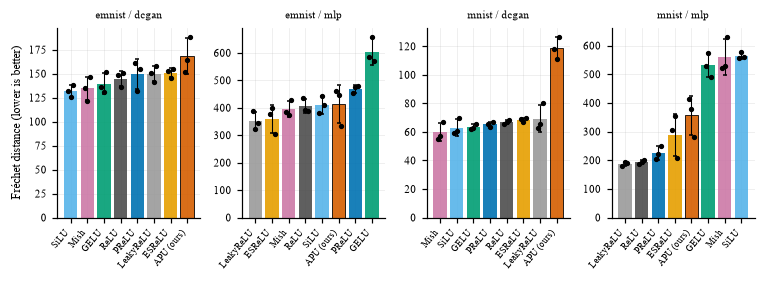

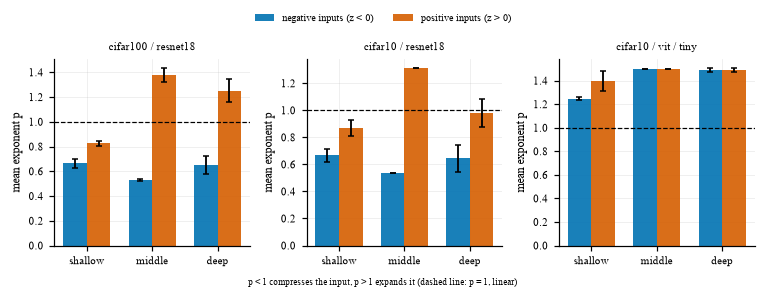

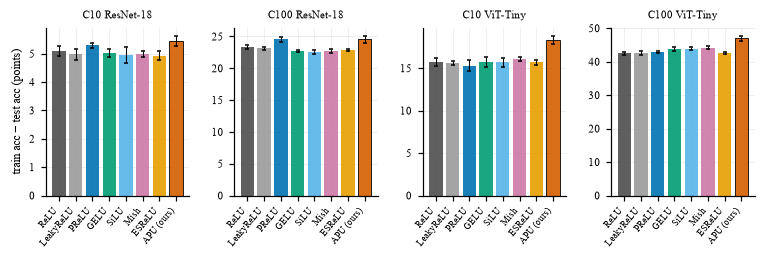

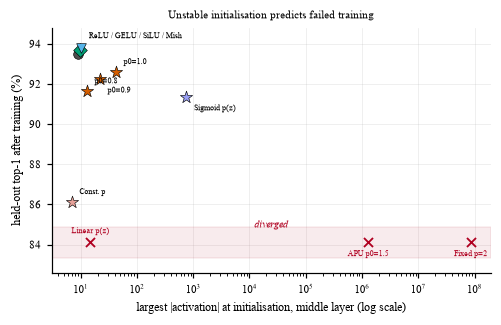

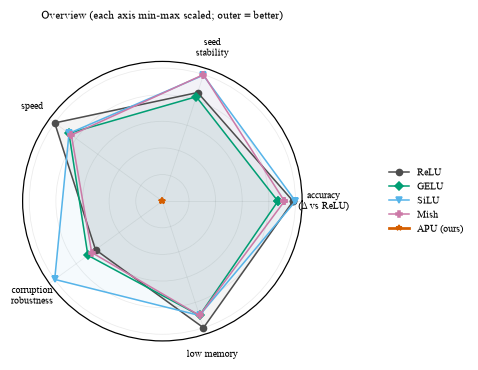

In [50]:
# ===== 15a. Paper-ready figures and comparison graphs (in addition to figures 1-10) =====
# Each figure answers one question, uses single/double-column widths, a colour + marker per activation (readable in black and white),
# and is saved as PDF (vector) and PNG. Names: figP01 ... figP14.
ACT_MARKER = dict(relu="o", leakyrelu="s", prelu="^", gelu="D", silu="v", mish="P", esrelu="X", apu="*")
def act_marker(a): return ACT_MARKER.get(a.split("@")[0], "*")
def set_label(ds, ar):
    dn = dict(cifar10="C10", cifar100="C100", tinyimagenet="Tiny-IN", imagenet="IN-1K", mnist="MNIST", emnist="EMNIST").get(ds, ds)
    return f"{dn}\n{arch_label(ar)}"
MAIN_ORDER = [("cifar10", "resnet18"), ("cifar100", "resnet18"), ("cifar10", "vit_tiny"), ("cifar100", "vit_tiny"), ("cifar10", "simplecnn"),
              ("tinyimagenet", "resnet18"), ("tinyimagenet", "vit_tiny"), ("imagenet", "resnet50")]
MAIN_DATASETS = ("cifar10", "cifar100", "tinyimagenet", "imagenet")

def _settings(d, require=("relu", "apu"), include_supp=False):
    """Dataset/model pairs that have finished runs for all `require` activations (main-paper datasets first, in a fixed order)."""
    ok = lambda ds, ar: all((d[(d.dataset == ds) & (d.arch == ar)].act == a).any() for a in require)
    out = [(ds, ar) for ds, ar in MAIN_ORDER if ok(ds, ar)]
    for ds, ar in sorted(set(zip(d.dataset, d.arch))):
        if (ds, ar) not in out and (ds in MAIN_DATASETS or include_supp) and ok(ds, ar): out.append((ds, ar))
    return out

def _acc(d, ds, ar, a): return d[(d.dataset == ds) & (d.arch == ar) & (d.act == a)].top1.values

# ---------------- P01: the activation functions being compared ----------------
def figP01_activation_functions():
    zz = torch.linspace(-4, 4, 801); names = ["relu", "leakyrelu", "prelu", "gelu", "silu", "mish", "esrelu", "apu"]
    fig, ax = plt.subplots(1, 3, figsize=(W2, 2.35))
    for a in names:
        z = zz.clone().requires_grad_(True); m = make_act(a); y = m(z); g, = torch.autograd.grad(y.sum(), z)
        kw = dict(color=act_color(a), lw=1.9 if a == "apu" else 1.0, ls="-" if a == "apu" else ("--" if a in ("relu", "leakyrelu", "prelu") else "-"), label=act_name(a) + (" (init)" if a == "apu" else "").replace(" (ours) (init)", " (init)"))
        ax[0].plot(zz, y.detach(), **kw); ax[1].plot(zz, g, **kw)
    ax[0].set_ylim(-1.6, 4); ax[0].set_ylabel("f(z)"); ax[1].set_ylim(-0.3, 1.7); ax[1].set_ylabel("f'(z)")
    for a_ in ax[:2]: a_.set_xlabel("z"); a_.set_xlim(-4, 4)
    ax[0].legend(ncol=2, loc="lower right", fontsize=5.2, framealpha=.9); ax[0].set_title("(a) activation functions"); ax[1].set_title("(b) derivatives")
    zc = torch.linspace(-4, 4, 400)
    for p, c in zip([0.5, 0.75, 1.0, 1.25, 1.5], plt.cm.viridis(np.linspace(0.05, 0.9, 5))):
        ax[2].plot(zc, zc * (zc ** 2 + 1e-3) ** ((p - 1) / 2), color=c, label=f"p = {p}")
    ax[2].plot(zc, F.relu(zc), "k--", lw=.7, label="ReLU")
    try: res = analyze_exponents("cifar10", "resnet18") if runs_for("cifar10", "resnet18", "apu") else {}
    except Exception: res = {}
    if res:
        s0 = sorted(res)[0]; names_ = list(res[s0]); z_, y_, _, _ = learned_curve(res[s0][names_[len(names_) // 2]]); ax[2].plot(z_, y_, color=act_color("apu"), lw=1.9, label="learned (middle layer)")
    ax[2].set_ylim(-4, 5); ax[2].set_xlim(-4, 4); ax[2].set_xlabel("z"); ax[2].set_title("(c) APU for constant p, and a learned shape"); ax[2].legend(fontsize=5, ncol=2, loc="upper left")
    plt.tight_layout(); _save(fig, "figP01_activation_functions")

# ---------------- P02: main comparison, difference to ReLU in every setting ----------------
def figP02_main_results():
    d = _results(); sets = _settings(d)
    if not sets: print("no settings with ReLU and APU"); return
    acts = [a for a in ACT_ORDER if a != "relu" and (d.act == a).any()]; w = 0.82 / len(acts)
    fig, ax = plt.subplots(figsize=(W2, 2.9))
    for j, a in enumerate(acts):
        for i, (ds, ar) in enumerate(sets):
            va, vr = _acc(d, ds, ar, a), _acc(d, ds, ar, "relu")
            if len(va) == 0 or len(vr) == 0: continue
            dif, lo, hi, p = welch_diff(va, vr); x = i + (j - (len(acts) - 1) / 2) * w
            ax.bar(x, dif, w * 0.92, color=act_color(a), label=act_name(a) if i == 0 else None, edgecolor="k" if a == "apu" else "none", lw=.6)
            if np.isfinite(lo): ax.errorbar(x, dif, yerr=[[dif - lo], [hi - dif]], color="k", lw=.6, capsize=1.2)
            if a == "apu" and np.isfinite(p) and p < 0.05:
                neg = dif < 0; ax.text(x, (lo if neg else hi) if np.isfinite(lo) else dif, "*", ha="center", va="top" if neg else "bottom", fontsize=10, fontweight="bold")
    ax.axhline(0, c="k", lw=.8); ax.set_xticks(range(len(sets))); ax.set_xticklabels([set_label(*s) for s in sets], fontsize=6.5)
    ax.set_ylabel("Δ test top-1 vs ReLU (points)"); ax.legend(ncol=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=6, frameon=False, columnspacing=1.0, handlelength=1.2)
    ax.set_title("Positive = better than ReLU; whiskers: 95% CI; * = APU differs from ReLU (p < 0.05)", fontsize=6.5, y=1.12)
    plt.tight_layout(); _save(fig, "figP02_main_results")

# ---------------- P03: average rank and critical-difference diagram ----------------
_NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

def _cd_diagram(ax, avg, cd, k, N):
    names = sorted(avg, key=avg.get); half = (k + 1) // 2; ax.set_xlim(0.2, k + 0.8); ax.set_ylim(-(half + 1.8) * 0.42, 1.2); ax.axis("off")
    ax.plot([1, k], [0, 0], "k", lw=1)
    for t in range(1, k + 1):
        ax.plot([t, t], [0, 0.07], "k", lw=.8); ax.text(t, 0.13, str(t), ha="center", fontsize=6.5)
    for i, n in enumerate(names):
        x = avg[n]; left = i < half; row = i if left else k - 1 - i; y = -(0.45 + 0.42 * row); xe = 0.55 if left else k + 0.45
        ax.plot([x, x, xe], [0, y, y], color=act_color(n), lw=.9)
        ax.text(xe + (-0.05 if left else 0.05), y, f"{act_name(n)}  ({x:.2f})", ha="right" if left else "left", va="center", fontsize=6.5, color=act_color(n), fontweight="bold" if n == "apu" else "normal")
    cl = []                                                           # maximal groups of activations whose average ranks differ by less than the critical difference
    for i in range(len(names)):
        j = i
        while j + 1 < len(names) and avg[names[j + 1]] - avg[names[i]] < cd: j += 1
        if j > i: cl.append((i, j))
    cl = [c for c in cl if not any(o != c and o[0] <= c[0] and o[1] >= c[1] for o in cl)]
    for level, (i, j) in enumerate(cl):
        ax.plot([avg[names[i]] - 0.03, avg[names[j]] + 0.03], [-0.13 - 0.1 * level] * 2, "k", lw=2.2, solid_capstyle="round")
    ax.plot([1, 1 + cd], [0.75, 0.75], "k", lw=1.6); ax.text(1 + cd / 2, 0.88, f"CD = {cd:.2f}", ha="center", fontsize=6.5)
    ax.text(k / 2 + 0.5, 1.12, "average rank (1 = best)", ha="center", fontsize=6.5)

def figP03_rank_cd():
    d = _results(); sets = _settings(d)
    full = [s_ for s_ in sets if all(len(_acc(d, *s_, a)) > 0 for a in ACT_ORDER)]          # settings where every activation was run (Tiny-ImageNet only has 5)
    if len(full) >= 3: sets = full
    acts = [a for a in ACT_ORDER if sets and all(len(_acc(d, ds, ar, a)) > 0 for ds, ar in sets)]; k, N = len(acts), len(sets)
    if N < 2 or k < 3: print(f"need >= 2 settings and >= 3 activations (have {N}, {k})"); return
    M = np.array([[_acc(d, ds, ar, a).mean() for a in acts] for ds, ar in sets]); ranks = np.array([stats.rankdata(-r) for r in M]); avg = dict(zip(acts, ranks.mean(0)))
    cd = _NEMENYI_Q05.get(k, 3.164) * math.sqrt(k * (k + 1) / (6 * N)); fp = stats.friedmanchisquare(*M.T).pvalue if N >= 3 else float("nan")
    fig, ax = plt.subplots(1, 2, figsize=(W2, 2.9), gridspec_kw=dict(width_ratios=[1.45, 1]))
    _cd_diagram(ax[0], avg, cd, k, N); ax[0].set_title(f"(a) critical-difference diagram ({N} settings; Friedman p = {fp:.3g})" if np.isfinite(fp) else f"(a) average ranks ({N} settings)", fontsize=7)
    order = sorted(acts, key=lambda a: avg[a])
    for j, a in enumerate(order):
        ax[1].scatter(np.full(N, j), ranks[:, acts.index(a)], color=act_color(a), marker=act_marker(a), s=22 if a != "apu" else 38, alpha=.85, edgecolor="k", lw=.3)
        ax[1].plot([j - .3, j + .3], [avg[a]] * 2, color="k", lw=1)
    ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels([act_name(a) for a in order], rotation=45, ha="right", fontsize=6); ax[1].set_ylabel("rank in each setting"); ax[1].invert_yaxis(); ax[1].set_title("(b) rank per setting (line = mean)", fontsize=7)
    plt.tight_layout(); _save(fig, "figP03_rank_cd_diagram")

# ---------------- P04: win / tie / loss of APU against every baseline ----------------
def figP04_win_tie_loss(ref="apu"):
    d = _results(); sets = _settings(d, require=("relu", ref))
    if not sets: print("no settings"); return
    base = [a for a in ACT_ORDER if a != ref]; W, T_, L = [], [], []
    for b in base:
        w = t = l = 0
        for ds, ar in sets:
            va, vb = _acc(d, ds, ar, ref), _acc(d, ds, ar, b)
            if len(vb) == 0: continue
            dif, lo, hi, p = welch_diff(va, vb)
            if np.isfinite(p) and p < 0.05: w, l = (w + 1, l) if dif > 0 else (w, l + 1)
            else: t += 1
        W.append(w); T_.append(t); L.append(l)
    fig, ax = plt.subplots(figsize=(W1 + 0.6, 2.6)); y = np.arange(len(base))
    ax.barh(y, W, color="#009E73", label=f"{act_name(ref)} significantly better"); ax.barh(y, T_, left=W, color="#BDBDBD", label="no significant difference")
    ax.barh(y, L, left=np.array(W) + np.array(T_), color="#D55E00", label=f"{act_name(ref)} significantly worse")
    for i in range(len(base)):
        for v, off, c in [(W[i], 0, "w"), (T_[i], W[i], "k"), (L[i], W[i] + T_[i], "w")]:
            if v: ax.text(off + v / 2, i, str(v), ha="center", va="center", fontsize=6.5, color=c)
    ax.set_yticks(y); ax.set_yticklabels([act_name(a) for a in base]); ax.invert_yaxis(); ax.set_xlabel(f"number of settings (of {len(sets)}); Welch test, p < 0.05")
    ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), fontsize=5.5, frameon=False, ncol=1); plt.tight_layout(); _save(fig, "figP04_win_tie_loss")

# ---------------- P05: distribution over seeds ----------------
def figP05_seed_distributions(max_sets=4):
    d = _results(); sets = _settings(d)[:max_sets]
    if not sets: print("no settings"); return
    n = len(sets); nc = 2 if n > 1 else 1; nr = -(-n // nc); fig, axs = plt.subplots(nr, nc, figsize=(W2, 2.4 * nr), squeeze=False)
    for a_ in axs.ravel(): a_.axis("off")
    for a_, (ds, ar) in zip(axs.ravel(), sets):
        a_.axis("on"); acts = [a for a in ACT_ORDER if len(_acc(d, ds, ar, a))]
        data = [_acc(d, ds, ar, a) for a in acts]
        bp = a_.boxplot(data, positions=range(len(acts)), widths=.55, patch_artist=True, showfliers=False, medianprops=dict(color="k", lw=1))
        for patch, a in zip(bp["boxes"], acts): patch.set_facecolor(act_color(a)); patch.set_alpha(.55)
        for i, (a, v) in enumerate(zip(acts, data)): a_.scatter(i + np.linspace(-.15, .15, len(v)) if len(v) > 1 else [i], v, s=8, color="k", zorder=3); a_.scatter([i], [v.mean()], marker="D", s=14, color="w", edgecolor="k", zorder=4)
        a_.set_xticks(range(len(acts))); a_.set_xticklabels([act_name(a) for a in acts], rotation=45, ha="right", fontsize=6); a_.set_ylabel("test top-1 (%)"); a_.set_title(set_label(ds, ar).replace("\n", " "), fontsize=7.5)
    plt.tight_layout(); _save(fig, "figP05_seed_distributions")

# ---------------- P06: does APU catch up during training? ----------------
def figP06_gap_over_training(refs=("relu", "gelu"), max_sets=6):
    d = _results(); sets = _settings(d)[:max_sets]
    if not sets: print("no settings"); return
    n = len(sets); nc = 3 if n > 2 else n; nr = -(-n // nc); fig, axs = plt.subplots(nr, nc, figsize=(W2, 2.05 * nr), squeeze=False)
    for a_ in axs.ravel(): a_.axis("off")
    def curves(ds, ar, a):
        H = [[h["val_top1"] for h in r.history] for r in d[(d.dataset == ds) & (d.arch == ar) & (d.act == a)].itertuples()]
        L = min(map(len, H)); return np.array([h[:L] for h in H])
    if curves(*sets[0], "apu").shape[1] < 3: print("runs are too short for a gap-over-training plot (needs >= 3 epochs)"); plt.close(fig); return
    for a_, (ds, ar) in zip(axs.ravel(), sets):
        a_.axis("on"); A = curves(ds, ar, "apu")
        for ref, ls in zip(refs, ["-", "--"]):
            if not (d[(d.dataset == ds) & (d.arch == ar) & (d.act == ref)].shape[0]): continue
            R = curves(ds, ar, ref); L = min(A.shape[1], R.shape[1]); e = np.arange(1, L + 1); gap = A[:, :L].mean(0) - R[:, :L].mean(0)
            se = np.sqrt(A[:, :L].var(0, ddof=1 if len(A) > 1 else 0) / len(A) + R[:, :L].var(0, ddof=1 if len(R) > 1 else 0) / len(R))
            a_.plot(e, gap, color=act_color(ref), ls=ls, label=f"APU − {act_name(ref)}"); a_.fill_between(e, gap - 1.96 * se, gap + 1.96 * se, color=act_color(ref), alpha=.15)
        a_.axhline(0, c="k", lw=.7); a_.set_xlabel("epoch"); a_.set_ylabel("Δ val top-1 (points)"); a_.set_title(set_label(ds, ar).replace("\n", " "), fontsize=7.5)
    axs.ravel()[0].legend(fontsize=6); plt.tight_layout(); _save(fig, "figP06_gap_over_training")

# ---------------- P07: accuracy against cost (Pareto view) ----------------
def figP07_accuracy_cost():
    d = _results(); sets = _settings(d)
    if not sets: print("no settings"); return
    acts = [a for a in ACT_ORDER if a != "relu"]; pts = {}
    for a in ACT_ORDER:
        dacc, tr = [], []
        for ds, ar in sets:
            dd = d[(d.dataset == ds) & (d.arch == ar)]; va, vr = _acc(d, ds, ar, a), _acc(d, ds, ar, "relu")
            ta, tr_ = dd[dd.act == a].median_epoch_time.mean(), dd[dd.act == "relu"].median_epoch_time.mean()
            if len(va) and len(vr) and np.isfinite(ta) and np.isfinite(tr_): dacc.append(va.mean() - vr.mean()); tr.append(ta / tr_)
        if dacc: pts[a] = (np.mean(dacc), np.std(dacc, ddof=1) / math.sqrt(len(dacc)) if len(dacc) > 1 else 0.0, np.mean(tr), np.std(tr, ddof=1) / math.sqrt(len(tr)) if len(tr) > 1 else 0.0)
    if not pts: print("no timing data"); return
    fig, ax = plt.subplots(1, 2, figsize=(W2, 2.7))
    for a, (my, sy, mx, sx) in pts.items():
        ax[0].errorbar(mx, my, xerr=sx, yerr=sy, fmt=act_marker(a), color=act_color(a), ms=9 if a == "apu" else 6, capsize=1.5, mec="k", mew=.4, label=act_name(a))
    front = sorted(pts.items(), key=lambda kv: kv[1][2]); best = -1e9; fx, fy = [], []
    for a, (my, sy, mx, sx) in front:
        if my > best: fx.append(mx); fy.append(my); best = my
    ax[0].plot(fx, fy, color="gray", ls=":", lw=1, zorder=0); ax[0].axhline(0, c="k", lw=.6); ax[0].axvline(1, c="k", lw=.6)
    ax[0].set_xlabel("training time per epoch (× ReLU)"); ax[0].set_ylabel("mean Δ top-1 vs ReLU (points)"); ax[0].legend(fontsize=5.5, ncol=2); ax[0].set_title(f"(a) accuracy vs training cost (mean over {len(sets)} settings)", fontsize=7)
    tf = ROOT / "tables" / "table4_efficiency_cifar10_resnet18.csv"; dd = _results(); dd = dd[(dd.dataset == "cifar10") & (dd.arch == "resnet18")]
    if tf.exists() and len(dd):
        t = pd.read_csv(tf).set_index("act"); acc = dd.groupby("act").top1.mean()
        for a in ACT_ORDER:
            if a in t.index and a in acc.index and "relu" in acc.index:
                ax[1].scatter(t.loc[a, "latency_bs_amp_ms"] / t.loc["relu", "latency_bs_amp_ms"], acc[a] - acc["relu"], marker=act_marker(a), color=act_color(a), s=70 if a == "apu" else 40, edgecolor="k", lw=.4, label=act_name(a))
        ax[1].axhline(0, c="k", lw=.6); ax[1].axvline(1, c="k", lw=.6); ax[1].set_xlabel("inference latency, AMP, batch 128 (× ReLU)"); ax[1].set_ylabel("Δ top-1 vs ReLU (points)"); ax[1].set_title("(b) accuracy vs inference cost (C10 ResNet-18)", fontsize=7)
    else: ax[1].axis("off")
    plt.tight_layout(); _save(fig, "figP07_accuracy_vs_cost")

# ---------------- P08: robustness comparison ----------------
def figP08_robustness(dataset="cifar10", arch="resnet18"):
    rob = load_robust(dataset, arch)
    if rob.empty: print("no robustness data for", dataset, arch); return
    per = rob.groupby(["act", "seed"]).agg(corrupt=("acc", "mean"), clean=("clean", "first")).reset_index(); per["retention"] = 100 * per.corrupt / per.clean
    acts = [a for a in ACT_ORDER if a in set(per.act)]; fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
    for k, (col, ttl, yl) in enumerate([("corrupt", "(a) mean accuracy under corruption", "accuracy (%)"), ("retention", "(b) accuracy retained", "retention (%)")]):
        for i, a in enumerate(acts):
            v = per[per.act == a][col].values; m, lo, hi = mean_ci(v); ax[k].bar(i, m, color=act_color(a), alpha=.9, edgecolor="k" if a == "apu" else "none", lw=.6)
            if np.isfinite(lo): ax[k].errorbar(i, m, yerr=[[m - lo], [hi - m]], color="k", capsize=1.5, lw=.7)
        mm = per.groupby("act")[col].mean(); ax[k].set_ylim(mm.min() - 6 * max(per[col].std(), .3), mm.max() + 2 * max(per[col].std(), .3))
        ax[k].set_xticks(range(len(acts))); ax[k].set_xticklabels([act_name(a) for a in acts], rotation=45, ha="right", fontsize=6); ax[k].set_ylabel(yl); ax[k].set_title(ttl, fontsize=7)
    corr = sorted(rob.corruption.unique()); show = [a for a in ["gelu", "silu", "mish", "apu"] if a in set(rob.act)]; w = 0.8 / max(len(show), 1)
    base = rob[rob.act == "relu"].groupby("corruption").acc.mean()
    for j, a in enumerate(show):
        diff = rob[rob.act == a].groupby("corruption").acc.mean() - base
        ax[2].bar(np.arange(len(corr)) + (j - (len(show) - 1) / 2) * w, [diff.get(c, np.nan) for c in corr], w, color=act_color(a), label=act_name(a), edgecolor="k" if a == "apu" else "none", lw=.5)
    ax[2].axhline(0, c="k", lw=.7); ax[2].set_xticks(range(len(corr))); ax[2].set_xticklabels([c.replace("_", " ") for c in corr], rotation=50, ha="right", fontsize=5.5)
    ax[2].set_ylabel("Δ accuracy vs ReLU (pts)"); ax[2].set_title("(c) per corruption type", fontsize=7); ax[2].legend(fontsize=5.3, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0), columnspacing=.8, handlelength=1)
    ax[2].set_ylim(top=max(ax[2].get_ylim()[1], 0) + 0.9)
    src = rob.source.iloc[0]; fig.suptitle(f"{dataset} / {arch_label(arch)} ({'official CIFAR-C' if src == 'official' else 're-implemented corruption subset'})", fontsize=7, y=1.02)
    plt.tight_layout(); _save(fig, f"figP08_robustness_{dataset}_{arch}")

# ---------------- P09: efficiency comparison relative to ReLU ----------------
def figP09_efficiency(dataset="cifar10", arch="resnet18"):
    tf = ROOT / "tables" / f"table4_efficiency_{dataset}_{arch}.csv"
    if not tf.exists(): print("no efficiency table for", dataset, arch); return
    t = pd.read_csv(tf).set_index("act"); acts = [a for a in ACT_ORDER if a in t.index]; r = lambda c: t.loc[acts, c] / t.loc["relu", c] if c in t.columns else None
    fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5))
    def bars(a_, cols, labels, title, ylab):
        cols = [(c, l) for c, l in zip(cols, labels) if c in t.columns and t.loc[acts, c].notna().any()]; w = 0.8 / max(len(cols), 1)
        for k, (c, l) in enumerate(cols):
            v = (t.loc[acts, c] / t.loc["relu", c]).values; a_.bar(np.arange(len(acts)) + (k - (len(cols) - 1) / 2) * w, np.nan_to_num(v), w, label=l, color=["#999999", "#4D4D4D"][k % 2], alpha=.8 if k == 0 else .95)
            for i, a in enumerate(acts):
                if a == "apu" and np.isfinite(v[i]): a_.text(i + (k - (len(cols) - 1) / 2) * w, v[i], f"{v[i]:.1f}×", ha="center", va="bottom", fontsize=5.5)
        a_.axhline(1, c="k", lw=.7); a_.set_xticks(range(len(acts))); a_.set_xticklabels([act_name(a) for a in acts], rotation=45, ha="right", fontsize=6); a_.set_ylabel(ylab); a_.set_title(title, fontsize=7); a_.legend(fontsize=5.5)
    bars(ax[0], ["epoch_time_s", "train_step_ms"], ["measured epoch time", "train step (eager)"], "(a) training cost", "× ReLU")
    bars(ax[1], ["latency_bs_ms", "latency_bs_amp_ms"], ["fp32", "AMP"], "(b) inference latency, batch 128", "× ReLU")
    bars(ax[2], ["peak_mem_mb", "peak_mem_compiled_mb"], ["eager", "compiled"], "(c) peak training memory", "× ReLU")
    plt.tight_layout(); _save(fig, f"figP09_efficiency_{dataset}_{arch}")

# ---------------- P10: GAN comparison across all configurations ----------------
def figP10_gan_comparison():
    g = load_results("gan")
    if g.empty: print("no GAN results"); return
    cfg = sorted(set(zip(g.dataset, g.arch))); n = len(cfg); fig, ax = plt.subplots(1, n, figsize=(W2, 2.6), squeeze=False); ax = ax[0]
    for a_, (ds, ar) in zip(ax, cfg):
        gg = g[(g.dataset == ds) & (g.arch == ar)]; s = gg.groupby("act").fd.agg(["mean", "std"]).sort_values("mean")
        for i, (a, r) in enumerate(s.iterrows()):
            a_.bar(i, r["mean"], color=act_color(a), edgecolor="k" if a == "apu" else "none", lw=.6, alpha=.9)
            if np.isfinite(r["std"]): a_.errorbar(i, r["mean"], yerr=r["std"], color="k", capsize=1.5, lw=.7)
            v = gg[gg.act == a].fd.values; a_.scatter(np.full(len(v), i) + np.linspace(-.15, .15, len(v)) if len(v) > 1 else [i], v, s=6, color="k", zorder=3)
        a_.set_xticks(range(len(s))); a_.set_xticklabels([act_name(a) for a in s.index], rotation=50, ha="right", fontsize=6); a_.set_title(f"{ds} / {ar}", fontsize=7.5)
        a_.set_ylabel("Fréchet distance (lower is better)" if a_ is ax[0] else "")
    plt.tight_layout(); _save(fig, "figP10_gan_comparison")

# ---------------- P11: learned exponent asymmetry ----------------
def figP11_exponent_asymmetry():
    files = sorted((ROOT / "tables").glob("exponent_layers_*.csv"))
    if not files: print("no exponent tables"); return
    fig, ax = plt.subplots(1, len(files), figsize=(W2, 2.4), squeeze=False); ax = ax[0]
    for a_, f in zip(ax, files):
        t = pd.read_csv(f); order = ["shallow", "middle", "deep"]; w = 0.36
        for k, (col, lab, c) in enumerate([("p_neg", "negative inputs (z < 0)", "#0072B2"), ("p_pos", "positive inputs (z > 0)", "#D55E00")]):
            g_ = t.groupby(["seed", "depth"])[col].mean().reset_index(); m = [g_[g_.depth == dpt][col].mean() for dpt in order]; s = [g_[g_.depth == dpt][col].std(ddof=1) if (g_.depth == dpt).sum() > 1 else 0 for dpt in order]
            a_.bar(np.arange(3) + (k - .5) * w, m, w, yerr=np.nan_to_num(s), color=c, capsize=2, label=lab, alpha=.9)
        a_.axhline(1.0, c="k", ls="--", lw=.8); a_.set_xticks(range(3)); a_.set_xticklabels(order); a_.set_ylabel("mean exponent p"); a_.set_title(f.stem.replace("exponent_layers_", "").replace("_", " / "), fontsize=7.5)
    h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc="upper center", ncol=2, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, 1.04))
    fig.text(0.5, -0.02, "p < 1 compresses the input, p > 1 expands it (dashed line: p = 1, linear)", ha="center", fontsize=6)
    plt.tight_layout(rect=(0, 0, 1, 0.95)); _save(fig, "figP11_exponent_asymmetry")

# ---------------- P12: generalisation gap ----------------
def figP12_generalization_gap(max_sets=4):
    df = load_results(); d = df[(~df.holdout) & (~df.diverged)] if len(df) else df; sets = _settings(d)[:max_sets]
    if not sets: print("no settings"); return
    fig, ax = plt.subplots(1, len(sets), figsize=(W2, 2.4), squeeze=False); ax = ax[0]
    for a_, (ds, ar) in zip(ax, sets):
        dd = d[(d.dataset == ds) & (d.arch == ar)]; acts = [a for a in ACT_ORDER if (dd.act == a).any()]
        for i, a in enumerate(acts):
            v = np.array([r.history[-1]["train_acc"] - r.history[-1]["val_top1"] for r in dd[dd.act == a].itertuples()]); m, lo, hi = mean_ci(v)
            a_.bar(i, m, color=act_color(a), edgecolor="k" if a == "apu" else "none", lw=.6, alpha=.9)
            if np.isfinite(lo): a_.errorbar(i, m, yerr=[[m - lo], [hi - m]], color="k", capsize=1.5, lw=.7)
        a_.set_xticks(range(len(acts))); a_.set_xticklabels([act_name(a) for a in acts], rotation=50, ha="right", fontsize=5.8); a_.set_title(set_label(ds, ar).replace("\n", " "), fontsize=7)
        a_.set_ylabel("train acc − test acc (points)" if a_ is ax[0] else "")
    plt.tight_layout(); _save(fig, "figP12_generalization_gap")

# ---------------- P13: stability at initialisation against accuracy ----------------
def figP13_stability_vs_accuracy():
    gf = ROOT / "tables" / "growth_at_init_cifar10_resnet18.csv"; pt = pilot_table()
    if not gf.exists() or pt is None: print("need growth table and pilot sweep"); return
    g = pd.read_csv(gf).set_index("activation"); p = pt.set_index("act"); acts = [a for a in g.index if a in p.index]
    fin = [a for a in acts if np.isfinite(p.loc[a, "top1_mean"])]; ymin = min(p.loc[a, "top1_mean"] for a in fin) if fin else 0; ymax = max(p.loc[a, "top1_mean"] for a in fin) if fin else 100
    ydiv = ymin - 0.16 * (ymax - ymin + 5); fig, ax = plt.subplots(figsize=(W1 + 1.2, 3.0))
    ax.axhspan(ydiv - 0.06 * (ymax - ymin + 5), ydiv + 0.06 * (ymax - ymin + 5), color="#B00020", alpha=.08); ax.text(0.5, ydiv + 0.05 * (ymax - ymin + 5), "diverged", transform=ax.get_yaxis_transform(), ha="center", va="bottom", fontsize=6.5, color="#B00020", style="italic")
    base = [a for a in fin if not a.startswith("apu")]; k = 0
    for a in acts:
        x = max(g.loc[a, "middle_layer"], 1.0)
        if a not in fin: ax.scatter(x, ydiv, marker="x", color="#B00020", s=35); ax.annotate(act_name(a), (x, ydiv), fontsize=5.3, xytext=(0, 6 if k % 2 else -9), textcoords="offset points", ha="center", color="#B00020"); k += 1
    for a in fin:
        x = max(g.loc[a, "middle_layer"], 1.0); y = p.loc[a, "top1_mean"]; ax.scatter(x, y, marker=act_marker(a), color=act_color(a), s=70 if a.startswith("apu") else 40, edgecolor="k", lw=.4, zorder=3)
    if base: ax.annotate("ReLU / GELU / SiLU / Mish", (np.mean([max(g.loc[a, "middle_layer"], 1.0) for a in base]), np.mean([p.loc[a, "top1_mean"] for a in base])), fontsize=5.5, xytext=(6, 8), textcoords="offset points")
    for i, a in enumerate([a for a in fin if a.startswith("apu")]):
        x = max(g.loc[a, "middle_layer"], 1.0); y = p.loc[a, "top1_mean"]; ax.annotate(act_name(a).replace("APU ", ""), (x, y), fontsize=5.3, xytext=(5, -9 if i % 2 else 5), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("largest |activation| at initialisation, middle layer (log scale)"); ax.set_ylabel("held-out top-1 after training (%)")
    ax.set_ylim(ydiv - 0.12 * (ymax - ymin + 5), ymax + 0.08 * (ymax - ymin + 5)); ax.set_title("Unstable initialisation predicts failed training", fontsize=7.5)
    plt.tight_layout(); _save(fig, "figP13_stability_vs_accuracy")

# ---------------- P14: overview radar ----------------
def figP14_overview_radar(show=("relu", "gelu", "silu", "mish", "apu")):
    d = _results(); sets = _settings(d)
    if not sets: print("no settings"); return
    m = {}
    m["accuracy"] = {a: np.mean([_acc(d, ds, ar, a).mean() - _acc(d, ds, ar, "relu").mean() for ds, ar in sets if len(_acc(d, ds, ar, a))]) for a in show}
    m["consistency"] = {a: -np.mean([_acc(d, ds, ar, a).std(ddof=1) for ds, ar in sets if len(_acc(d, ds, ar, a)) > 1] or [0.0]) for a in show}
    tm = {}
    for a in show:
        r_ = [d[(d.dataset == ds) & (d.arch == ar) & (d.act == a)].median_epoch_time.mean() / d[(d.dataset == ds) & (d.arch == ar) & (d.act == "relu")].median_epoch_time.mean() for ds, ar in sets]
        tm[a] = -np.nanmean(r_)
    m["speed"] = tm
    rob = load_robust("cifar10", "resnet18")
    if len(rob): m["robustness"] = {a: rob[rob.act == a].acc.mean() for a in show if (rob.act == a).any()}
    tf = ROOT / "tables" / "table4_efficiency_cifar10_resnet18.csv"
    if tf.exists():
        t = pd.read_csv(tf).set_index("act"); m["memory"] = {a: -t.loc[a, "peak_mem_mb"] for a in show if a in t.index}
    keys = [k for k, v in m.items() if all(a in v and np.isfinite(v[a]) for a in show)]
    if len(keys) < 3: print("not enough metrics for a radar chart"); return
    norm = {k: {a: (m[k][a] - min(m[k].values())) / (max(m[k].values()) - min(m[k].values()) + 1e-12) for a in show} for k in keys}
    ang = np.linspace(0, 2 * np.pi, len(keys), endpoint=False).tolist(); ang += ang[:1]
    fig = plt.figure(figsize=(W1 + 1.8, 3.3)); ax = fig.add_subplot(111, polar=True)
    for a in show:
        vals = [norm[k][a] for k in keys] + [norm[keys[0]][a]]; ax.plot(ang, vals, color=act_color(a), marker=act_marker(a), lw=1.8 if a == "apu" else 1.0, ms=4, label=act_name(a)); ax.fill(ang, vals, color=act_color(a), alpha=.06)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels([{"accuracy": "accuracy\n(Δ vs ReLU)", "consistency": "seed\nstability", "speed": "speed", "robustness": "corruption\nrobustness", "memory": "low memory"}.get(k, k) for k in keys], fontsize=6.5)
    ax.set_yticklabels([]); ax.set_ylim(0, 1.05); ax.legend(loc="center left", bbox_to_anchor=(1.28, 0.5), fontsize=6.5, ncol=1, frameon=False); ax.set_title("Overview (each axis min-max scaled; outer = better)", fontsize=7, y=1.12); fig.subplots_adjust(left=0.1, right=0.72)
    _save(fig, "figP14_overview_radar")

if analysis_on():
    safe(figP01_activation_functions); safe(figP02_main_results); safe(figP03_rank_cd); safe(figP04_win_tie_loss); safe(figP05_seed_distributions)
    safe(figP06_gap_over_training); safe(figP07_accuracy_cost)
    for _ds, _ar in P["robust_grid"]:
        safe(figP08_robustness, _ds, _ar); safe(figP09_efficiency, _ds, _ar)
    safe(figP10_gan_comparison); safe(figP11_exponent_asymmetry); safe(figP12_generalization_gap); safe(figP13_stability_vs_accuracy); safe(figP14_overview_radar)
else:
    print("paper figures skipped (add 'analysis' to APU_STAGES)")


In [51]:
# ===== 15b. Findings summary + paper assets (figures, tables, captions, one zip) =====
import shutil

def build_findings():
    """Plain-language summary of what the logged runs show, with the numbers filled in. It states results as measured, good or bad."""
    out = [f"# Measured findings (auto-generated {datetime.datetime.now():%Y-%m-%d %H:%M})", f"Profile `{PROFILE}`, size `{SIZE}`, device {device}.", ""]
    df = load_results(); d = df[~df.holdout] if len(df) else df
    if d.empty: out.append("No finished runs yet."); return "\n".join(out)
    out.append("## Recognition: final-epoch test top-1 (mean ± std over seeds)")
    wins = tot = 0
    for (ds, ar), g in d.groupby(["dataset", "arch"]):
        ok = g[~g.diverged]; base = [a for a in ok.act.unique() if not a.startswith("apu")]
        if "apu" not in set(ok.act) or not base: continue
        m = ok.groupby("act").top1.mean(); best = m[base].idxmax(); va, vb = ok[ok.act == "apu"].top1.values, ok[ok.act == best].top1.values
        dif, lo, hi, p = welch_diff(va, vb); sd = f"{va.std(ddof=1):.2f}" if len(va) > 1 else "n/a"; tot += 1; wins += int(dif > 0)
        rr = ok[ok.act == "relu"].top1.values; dr = float(va.mean() - rr.mean()) if len(rr) else float("nan")
        ci = f"95% CI [{lo:.2f}, {hi:.2f}], Welch p = {p:.3g}" if np.isfinite(lo) else "CI needs >= 2 seeds"
        out.append(f"- **{ds} / {arch_label(ar)}**: APU {va.mean():.2f} ± {sd} (n={len(va)}). Best baseline {act_name(best)} {vb.mean():.2f}. "
                   f"APU is {abs(dif):.2f} points {'ahead of' if dif > 0 else 'behind'} it ({ci}); versus ReLU {dr:+.2f}.")
    out.append(f"\nAPU beats the best baseline in {wins} of {tot} settings.")
    dv = d[d.diverged].groupby("act").size()
    if len(dv): out.append("\nDiverged runs (NaN loss, stopped early): " + ", ".join(f"{act_name(a)} ×{n}" for a, n in dv.items()) + ".")
    out.append("\n## Efficiency (APU vs ReLU)")
    for f in sorted((ROOT / "tables").glob("table4_efficiency_*.csv")):
        t = pd.read_csv(f).set_index("act")
        if "apu" in t.index and "relu" in t.index:
            cols = [c for c in ["train_step_ms_overhead_%", "train_step_compiled_ms_overhead_%", "peak_mem_compiled_mb_overhead_%", "latency_bs_ms_overhead_%", "latency_bs_amp_ms_overhead_%", "peak_mem_mb_overhead_%", "epoch_time_s_overhead_%"] if c in t]
            out.append(f"- {f.stem.replace('table4_efficiency_', '')}: " + ", ".join(f"{c.replace('_overhead_%', '').replace('_', ' ')} {t.loc['apu', c]:+.0f}%" for c in cols) + f"; parameters {t.loc['apu', 'params_overhead_%']:+.4f}%.")
    out.append("\n## Robustness (accuracy under corruption, mean over corruptions and severities)")
    for ds, ar in P["robust_grid"]:
        rb = load_robust(ds, ar)
        if len(rb):
            m = rb.groupby("act").acc.mean()
            if "apu" in m and "relu" in m: out.append(f"- {ds} / {arch_label(ar)}: APU {m['apu']:.2f}% vs ReLU {m['relu']:.2f}% ({m['apu'] - m['relu']:+.2f} points); best activation {act_name(m.idxmax())} {m.max():.2f}%. Source: {rb.source.iloc[0]}.")
    out.append("\n## Learned exponent")
    for f in sorted((ROOT / "tables").glob("exponent_layers_*.csv")):
        t = pd.read_csv(f)
        out.append(f"- {f.stem.replace('exponent_layers_', '')}: mean |ΔA| from init {t.A_change.mean():.3f}, |Δw_z| {t.wz_change.mean():.3f}, |Δb_z| {t.bz_change.mean():.3f}; std of p(z) inside a layer {t.p_std_within.mean():.3f}; std of layer-mean p across depth {t.groupby('seed').p_mean.std().mean():.3f}; mean p on negative inputs {t.p_neg.mean():.3f} vs positive inputs {t.p_pos.mean():.3f}.")
    g = load_results("gan")
    if len(g):
        out.append("\n## GAN (Fréchet distance in classifier-feature space, lower is better)")
        for (ds, ar), gg in g.groupby(["dataset", "arch"]):
            m = gg.groupby("act").fd.mean().sort_values(); out.append(f"- {ds} / {ar}: " + ", ".join(f"{act_name(a)} {v:.1f}" for a, v in m.items()))
    ct = convergence_table()
    if ct is not None and (ct.act == "apu").any():
        out.append("\n## Convergence (epochs to reach 95% of ReLU's final accuracy)")
        for (ds, ar), gg in ct.groupby(["dataset", "arch"]):
            a = gg[gg.act == "apu"]; r = gg[gg.act == "relu"]
            if len(a) and len(r): out.append(f"- {ds} / {arch_label(ar)}: APU {a.epochs_to_target.iloc[0]:.1f} (reached in {int(a.reached.iloc[0])}/{int(a.n.iloc[0])} runs) vs ReLU {r.epochs_to_target.iloc[0]:.1f}.")
    out.append("\n## How to read this\nThe decision rule from the requirements document applies: do not claim APU is better everywhere. State where it helps, where it does not, and what it costs.")
    return "\n".join(out)

CAPTIONS = {
 "fig1_motivation": "Figure 1. (a) Distribution of pre-activations at three depths of a trained ReLU network (measured). (b) Shapes learned by APU at three depths (trained parameters). (c) APU computation: an input-dependent exponent p(z) followed by a smooth power.",
 "fig2_exponent": "Figure 2. Learned exponent of a trained APU network: (a) layer-wise mean and within-layer spread, (b) distribution by depth, (c) channel-wise means, (d) exponent against input, (e) learned f(z), (f) spread of p(z) over training.",
 "fig3_recognition": "Figure 3 (one figure per dataset). Final-epoch test top-1 (bars: mean, whiskers: 95% CI, dots: individual seeds) and validation curves (mean ± std over seeds) for every model.",
 "fig3b_gap_to_relu": "Figure 3b. Difference to ReLU in test top-1 (mean and 95% Welch confidence interval). Points left of zero are worse than ReLU.",
 "fig4a_optimization": "Figure 4a. Optimisation behaviour: training loss, global gradient norm, epochs to reach 95% of ReLU's final accuracy, and per-layer gradient norms at initialisation and after training.",
 "fig4b_robust_efficiency": "Figure 4b. Corruption accuracy (heat map, severity curves), PGD sanity check, and efficiency: overhead versus ReLU, accuracy versus cost, measured time per epoch.",
 "fig5_gan": "Figure 5. GAN training curves, discriminator scores and sample-quality metrics computed in the feature space of a classifier trained on real data.",
 "fig5b_gan_samples": "Figure 5b. Generated samples from the same fixed noise vectors after the last epoch (first seed).",
 "fig6_ablation_stability": "Figure 6. (a) Ablation of the exponent design, (b) largest activation at initialisation (log scale), (c) pilot sweep over APU initial settings on a held-out split.",
 "fig7_lr_sweep": "Figure 7. Learning-rate sensitivity on the held-out split and the best learning rate per activation.",
 "fig8_parameter_dynamics": "Figure 8. Evolution of the learned APU parameters per layer during training.",
 "fig9_rank_heatmap": "Figure 9. Rank of every activation within each dataset and model.",
 "figP01": "Figure P1. (a) The compared activation functions and (b) their derivatives; (c) APU for constant exponents p and a shape learned during training.",
 "figP02": "Figure P2. Difference in test top-1 to ReLU in every dataset/model setting (mean and 95% Welch confidence interval). * marks settings where APU differs from ReLU at p < 0.05.",
 "figP03": "Figure P3. (a) Critical-difference diagram (Friedman test, Nemenyi post-hoc, alpha = 0.05) of the average rank over all settings; activations joined by a bar are not significantly different. (b) Rank in each setting.",
 "figP04": "Figure P4. Number of settings in which APU is significantly better, not significantly different, or significantly worse than each baseline (Welch test, p < 0.05).",
 "figP05": "Figure P5. Distribution of final test top-1 over seeds (box: quartiles, dots: individual seeds, diamond: mean).",
 "figP06": "Figure P6. Gap in validation accuracy between APU and ReLU / GELU during training (mean and 95% band over seeds).",
 "figP07": "Figure P7. (a) Accuracy against training cost (mean over settings; dotted line joins the non-dominated activations). (b) Accuracy against inference latency.",
 "figP08": "Figure P8. Robustness to common corruptions: (a) mean accuracy, (b) accuracy retained relative to clean accuracy, (c) difference to ReLU per corruption type.",
 "figP09": "Figure P9. Cost relative to ReLU: (a) training time, (b) inference latency in fp32 and AMP, (c) peak training memory in eager and compiled mode.",
 "figP10": "Figure P10. GAN comparison: Frechet distance in classifier-feature space for every dataset and architecture (bars: mean, whiskers: std, dots: seeds).",
 "figP11": "Figure P11. Learned exponent of APU on negative and positive inputs by depth (mean and std over seeds). p < 1 compresses, p > 1 expands.",
 "figP12": "Figure P12. Generalisation gap (train accuracy minus test accuracy) at the end of training.",
 "figP13": "Figure P13. Largest activation at initialisation against held-out accuracy of the pilot variants; diverged variants are shown in the bottom band.",
 "figP14": "Figure P14. Overview of accuracy, seed stability, speed, robustness and memory (each axis min-max scaled over the shown activations; outer is better).",
 "fig10_learned_shapes": "Figure 10. Learned f(z) and f'(z) by depth with spread over layers and seeds, compared with ReLU, GELU and SiLU."}

def export_paper_assets():
    out = ROOT / "paper_assets"; (out / "figures").mkdir(parents=True, exist_ok=True); (out / "tables").mkdir(exist_ok=True)
    for f in list((ROOT / "figures").glob("*.pdf")) + list((ROOT / "figures").glob("*.png")): shutil.copy(f, out / "figures" / f.name)
    for f in list((ROOT / "tables").glob("*.csv")) + list((ROOT / "tables").glob("*.tex")): shutil.copy(f, out / "tables" / f.name)
    txt = build_findings(); (out / "FINDINGS.md").write_text(txt, encoding="utf-8"); print(txt)
    figs = sorted(f.stem for f in (ROOT / "figures").glob("*.pdf"))
    (out / "CAPTIONS.md").write_text("\n\n".join(f"**{n}**: " + next((c for k, c in CAPTIONS.items() if n.startswith(k)), "(no caption template)") for n in figs), encoding="utf-8")
    z = shutil.make_archive(str(ROOT / "paper_assets"), "zip", out); print("\nsaved", z, "|", len(figs), "figures"); return z

if analysis_on():
    safe(export_paper_assets)


# Measured findings (auto-generated 2026-10-29 03:34)
Profile `local`, size `paper`, device cuda.

## Recognition: final-epoch test top-1 (mean ± std over seeds)
- **cifar10 / ResNet-18**: APU 94.51 ± 0.14 (n=5). Best baseline ESReLU 95.06. APU is 0.55 points behind it (95% CI [-0.75, -0.35], Welch p = 0.000242); versus ReLU -0.38.
- **cifar10 / SimpleCNN**: APU 83.33 ± 0.42 (n=5). Best baseline GELU 82.53. APU is 0.80 points ahead of it (95% CI [0.29, 1.31], Welch p = 0.0102); versus ReLU +1.20.
- **cifar10 / ViT-Tiny**: APU 80.59 ± 1.03 (n=5). Best baseline PReLU 84.71. APU is 4.12 points behind it (95% CI [-5.39, -2.84], Welch p = 0.000223); versus ReLU -3.67.
- **cifar100 / ResNet-18**: APU 75.40 ± 0.48 (n=5). Best baseline SiLU 77.43. APU is 2.03 points behind it (95% CI [-2.62, -1.44], Welch p = 0.000131); versus ReLU -1.22.
- **cifar100 / ViT-Tiny**: APU 52.92 ± 0.62 (n=5). Best baseline LeakyReLU 57.44. APU is 4.53 points behind it (95% CI [-5.33, -3.73], Welch p = 2.71e-06); v

In [52]:
# ===== 16. Requirements checklist: what exists on disk right now =====
def requirements_status():
    df = load_results(); gdf = load_results("gan"); ok, no = "DONE", "MISSING"
    d = df[~df.holdout] if len(df) else df; need_seeds = 5 if not SMOKE else 2
    def has(ds, archs, acts=("relu", "apu")):
        if d.empty: return False
        sub = d[(d.dataset == ds) & (d.arch.str.startswith(archs))]
        return all((sub.act == a).any() for a in acts)
    def seeds_ok():
        if d.empty: return False
        g = d[d.dataset.isin(["cifar10", "cifar100"]) & d.act.isin(["relu", "apu"])].groupby(["dataset", "arch", "act"]).seed.nunique()
        return len(g) > 0 and (g >= need_seeds).all()
    glob_ = lambda sub, pat: len(list((ROOT / sub).glob(pat))) > 0
    rows = [
        ("CIFAR-10: SimpleCNN, ResNet-18, ViT", all(has("cifar10", (a,)) for a in ("simplecnn", "resnet18", "vit"))),
        ("CIFAR-100: ResNet + ViT", has("cifar100", ("resnet",)) and has("cifar100", ("vit",))),
        ("ImageNet-1K: ResNet-50 + ViT (needs IMAGENET_DIR and SIZE=thorough)", has("imagenet", ("resnet",)) and has("imagenet", ("vit",))),
        ("Tiny-ImageNet (laptop-scale substitute for ImageNet)", has("tinyimagenet", ("resnet",))),
        ("Learning-rate parity sweep", (not df.empty) and bool(((df.lr_scale != 1.0) & df.holdout).any())),
        ("PGD sanity check", len(list((ROOT / "robust").glob("pgd_*.csv"))) > 0),
        ("Paper assets zip (figures, tables, captions, findings)", (ROOT / "paper_assets.zip").exists()),
        ("GELU, SiLU, Mish compared with APU", (not d.empty) and all((d.act == a).any() for a in ("gelu", "silu", "mish"))),
        ("MNIST / EMNIST supplementary", (not d.empty) and d.dataset.isin(["mnist"]).any() and d.dataset.isin(["emnist"]).any()),
        (f"Seeds >= {need_seeds} for CIFAR ReLU/APU", seeds_ok()),
        ("Full ablation (6 variants)", (not d.empty) and all(((d.dataset == "cifar100") & (d.act == a)).any() for a in ABLATION)),
        ("APU exponent analysis cached", glob_("analysis", "exp_*.pt")),
        ("Table 4 efficiency", glob_("tables", "table4_*.csv")),
        ("Corruption robustness", glob_("robust", "*.json")),
        ("GAN runs with Frechet distance", (not gdf.empty) and gdf.fd.notna().any()),
        ("Table 1 / Table 2 / Table 3", all((ROOT / "tables" / f).exists() for f in ["table1_activation_comparison.csv", "table2_main_results.csv", "table3_ablation.csv"])),
        ("Paper comparison figures P1-P14", len(list((ROOT / "figures").glob("figP*.pdf"))) >= 8),
        ("Figures 1-5 (+ supplementary 6-10)", all(glob_("figures", pat) for pat in ["fig1_*.png", "fig2_*.png", "fig3_*.png", "fig4a_*.png", "fig4b_*.png", "fig5_*.png", "fig6_*.png"])),
        ("Environment + seeds recorded", len(list(ROOT.glob("env*.json"))) > 0),
    ]
    in_size = {"CIFAR-10: SimpleCNN, ResNet-18, ViT": {("cifar10", "simplecnn"), ("cifar10", "resnet18"), ("cifar10", "vit_tiny")} <= set(P["main_grid"]),
               "CIFAR-100: ResNet + ViT": {("cifar100", "resnet18"), ("cifar100", "vit_tiny")} <= set(P["main_grid"]),
               "Tiny-ImageNet (laptop-scale substitute for ImageNet)": bool(P["tiny_grid"]),
               "MNIST / EMNIST supplementary": {d for d, _ in P["supp_grid"]} >= {"mnist", "emnist"},
               f"Seeds >= {need_seeds} for CIFAR ReLU/APU": len(P["main"]["seeds"]) >= need_seeds,
               "ImageNet-1K: ResNet-50 + ViT (needs IMAGENET_DIR and SIZE=paper)": bool(P["imagenet_grid"])}
    status = []
    for r, v in rows:
        key = next((k for k in in_size if r.startswith(k[:30])), None)
        status.append(ok if v else (f"not in SIZE={SIZE}" if key is not None and not in_size[key] else no))
    out = pd.DataFrame([dict(requirement=r, status=s) for (r, v), s in zip(rows, status)]); display(out)
    print(f"\n{(out.status == ok).sum()}/{len(out)} items present; {(out.status.str.startswith('not in')).sum()} are not part of SIZE='{SIZE}'.")
    if (ROOT / "logs" / "failures.log").exists(): print("Some runs failed, see", ROOT / "logs" / "failures.log")
    return out

_ = requirements_status()

# ---- preflight verdict ----
if SIZE == "preflight":
    _fail = ROOT / "logs" / "failures.log"; _problems = []
    if _fail.exists() and _fail.read_text().strip(): _problems.append(f"failed runs listed in {_fail}")
    _d = load_results(); _have = set(zip(_d.dataset, _d.arch)) if len(_d) else set()
    _need = set(P["main_grid"]) | set(P["tiny_grid"]) | set(P["supp_grid"])
    if _need - _have: _problems.append(f"no finished run for: {sorted(_need - _have)}")
    if len(load_results("gan")) == 0: _problems.append("no GAN run finished")
    if not (ROOT / "paper_assets.zip").exists(): _problems.append("paper_assets.zip was not created")
    if _DL_FAILED: _problems.append(f"downloads failed: {sorted(_DL_FAILED)}")
    if _problems:
        print("\nPREFLIGHT FOUND PROBLEMS (fix these before the long run):"); [print(" -", p) for p in _problems]
    else:
        Path("apu_preflight_ok.flag").write_text(f"preflight passed {datetime.datetime.now():%Y-%m-%d %H:%M}\n")
        print("\nPREFLIGHT OK. Every dataset, model, stage, figure and export worked. Now run all cells again to start the real paper run.")
elif os.environ.get("APU_REQUESTED_SIZE") == "paper":
    print(f"\nPaper run finished. Results: {ROOT.resolve()}  |  paper assets: {(ROOT / 'paper_assets.zip').resolve()}")


,requirement,status
0,"CIFAR-10: SimpleCNN, ResNet-18, ViT",DONE
1,CIFAR-100: ResNet + ViT,DONE
2,ImageNet-1K: ResNet-50 + ViT (needs IMAGENET_D...,not in SIZE=paper
3,Tiny-ImageNet (laptop-scale substitute for Ima...,DONE
4,Learning-rate parity sweep,DONE
5,PGD sanity check,DONE
6,"Paper assets zip (figures, tables, captions, f...",DONE
7,"GELU, SiLU, Mish compared with APU",DONE
8,MNIST / EMNIST supplementary,DONE
9,Seeds >= 5 for CIFAR ReLU/APU,DONE



18/19 items present; 1 are not part of SIZE='paper'.

Paper run finished. Results: C:\Users\ziaur\Downloads\APU_Final2\apu_runs_paper  |  paper assets: C:\Users\ziaur\Downloads\APU_Final2\apu_runs_paper\paper_assets.zip


## Reading the results

Decision rule from the requirements document: **do not claim APU is better everywhere.** The claim the experiments can support is that APU is an input-conditioned adaptive nonlinearity, and the tables and figures should show *when* that helps (accuracy, optimisation, robustness, cost). If `adaptation_verdict()` in section 12 says the exponent barely moves from `p0`, the honest description is a near-fixed-power unit, and the paper should say so.

Before writing numbers into a manuscript:

- Use only final-epoch test numbers from `tables/` (never `best_top1`).
- Replace the re-implemented corruption subset with official CIFAR-10-C / CIFAR-100-C (`CIFAR_C_DIR`).
- Report FLOPs together with measured latency and memory, since FLOP counters ignore the elementwise cost of the activation.
- State the hardware and software versions from `env.json`.
